### Section 0 — Setup

In [1]:
import gc
import io
import json
import sys
import time
import warnings
from importlib.metadata import version as _pkg_version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GroupKFold
from torch import nn, optim
from torch.utils.data import DataLoader, Dataset, Subset, TensorDataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer
from transformers.utils import logging as hf_logging

In [2]:
warnings.filterwarnings("ignore")
hf_logging.set_verbosity_error()
sns.set_style("whitegrid")

In [3]:
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

BASE_DIR = Path.cwd()
PATHS = {
    "processed": BASE_DIR / "dataset_processed.csv",
    "splits": BASE_DIR / "split_indices.npz",
    "cv_folds": BASE_DIR / "cv_fold_indices.npz",
    "artifact": BASE_DIR / "model_artifact.json",
    "models_dir": BASE_DIR / "models",
    "scaler": BASE_DIR / "scaler.pkl",
    "plots_dir": BASE_DIR / "plots",
}
PATHS["plots_dir"].mkdir(exist_ok=True)
PATHS["models_dir"].mkdir(parents=True, exist_ok=True)
(PATHS["models_dir"] / "reports").mkdir(exist_ok=True)
(PATHS["models_dir"] / "errors").mkdir(exist_ok=True)
(PATHS["models_dir"] / "cv_deep").mkdir(exist_ok=True)

# Experiment constants
TARGET_FPR = 1e-3
MAX_LEN = 75
BATCH_SIZE_DEEP = 512
NUM_WORKERS = 0  # Windows-safe
PIN_MEMORY = True
MAX_EPOCHS_DEEP = 40
PATIENCE_DEEP = 4
N_CV_SPLITS = 5
N_LEGIT_GROUPS = 10
N_TOP_ERRORS = 10
CV_USE_SUMMARY_CACHE = True
CV_FOLD_RESUME = True

# Model name registries
FEATURE_MODEL_NAMES = ["LightGBM", "XGBoost", "MLP"]
DEEP_MODEL_NAMES = [
    "CharCNN-Small",
    "CharCNN-Medium",
    "CharBERT-Small",
    "CharBERT-Medium",
]

MODEL_ORDER = FEATURE_MODEL_NAMES + DEEP_MODEL_NAMES
ALL_MODEL_ORDER = MODEL_ORDER + ["DomURLs_BERT"]

SCALED_MODEL_NAMES = {"MLP"}

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"- GPU: {torch.cuda.get_device_name(0)}")
    print(f"- CUDA: {torch.version.cuda}")

Device: cuda
- GPU: NVIDIA GeForce RTX 2060
- CUDA: 12.6


In [4]:
def pick_threshold(y_val, y_prob, target_fpr=1e-3):
    """Порог, максимизирующий TPR при FPR <= target_fpr."""
    fpr, tpr, thr = roc_curve(y_val, y_prob)
    valid = fpr <= target_fpr
    if not valid.any():
        return 0.5, None, None
    idx = np.argmax(tpr * valid)
    return float(thr[idx]), float(fpr[idx]), float(tpr[idx])


def pick_threshold_at_recall(y_val, y_prob, target_recall=0.95):
    """Порог при достижении заданного recall."""
    _, r, thr = precision_recall_curve(y_val, y_prob)
    idx = np.searchsorted(-r, -target_recall, side="right") - 1
    return float(thr[max(idx, 0)])


def tpr_at_fpr(y_true, y_prob, target_fpr):
    """TPR при FPR <= target_fpr (threshold-free)."""
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    idx = np.searchsorted(fpr, target_fpr, side="right") - 1
    return float(tpr[max(idx, 0)])


def precision_at_recall(y_true, y_prob, target_recall):
    p, r, _ = precision_recall_curve(y_true, y_prob)
    idx = np.searchsorted(-r, -target_recall, side="right") - 1
    return float(p[max(idx, 0)])


def fp_per_million(fpr):
    return fpr * 1_000_000


def precision_at_prevalence(tpr, fpr, prevalence):
    num = prevalence * tpr
    den = num + (1 - prevalence) * fpr
    return num / den if den > 0 else 0.0


def metrics_block(y_true, y_prob, threshold):
    """17-колоночный блок метрик."""
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "pr_auc": average_precision_score(y_true, y_prob),
        "tpr": tp / (tp + fn) if tp + fn else 0.0,
        "fpr": fp / (fp + tn) if fp + tn else 0.0,
        "fp_per_million": fp_per_million(fp / (fp + tn)) if fp + tn else 0.0,
        "brier": brier_score_loss(y_true, y_prob),
    }


def per_family_recall(df_test, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    out = {}
    for fam in df_test.loc[df_test["label"] == 1, "class"].unique():
        m = (df_test["class"] == fam).to_numpy()
        out[fam] = float((y_pred[m] == 1).mean())
    return out


def top_errors(y_true, df, y_prob, threshold, n=10):
    """Топ ошибок FP и топ ошибок FN."""
    pred = (y_prob >= threshold).astype(int)
    fp_mask = (y_true == 0) & (pred == 1)
    fn_mask = (y_true == 1) & (pred == 0)
    fp = (
        df.loc[fp_mask, ["domain", "class"]]
        .assign(prob=y_prob[fp_mask])
        .sort_values("prob", ascending=False)
    )
    fn = (
        df.loc[fn_mask, ["domain", "class"]]
        .assign(prob=y_prob[fn_mask])
        .sort_values("prob", ascending=True)
    )
    return fp.head(n), fn.head(n)


def full_metrics_block(y_true, y_prob, threshold):
    """17-колоночный блок метрик: metrics_block + threshold-free + prevalence-aware"""
    m = metrics_block(y_true, y_prob, threshold)
    m["tpr@fpr=1e-2"] = tpr_at_fpr(y_true, y_prob, 1e-2)
    m["tpr@fpr=1e-3"] = tpr_at_fpr(y_true, y_prob, 1e-3)
    m["tpr@fpr=1e-4"] = tpr_at_fpr(y_true, y_prob, 1e-4)
    for r in (0.95, 0.99):
        m[f"prec@rec={r}"] = precision_at_recall(y_true, y_prob, r)
    for prev in (1e-3, 1e-4):
        m[f"prec@prev={prev}"] = precision_at_prevalence(m["tpr"], m["fpr"], prev)
    return m


def save_top_errors(name, y_true, df, y_prob, threshold, out_dir, n=10):
    """Запускает top_errors и сохраняет результат в CSV"""
    out_dir = Path(out_dir)
    fp, fn = top_errors(y_true, df, y_prob, threshold, n=n)
    fp.to_csv(out_dir / f"{name}_ood_FP.csv", index=False)
    fn.to_csv(out_dir / f"{name}_ood_FN.csv", index=False)
    return fp, fn

### Section 1 — Data & Feature Models

In [5]:
full_df = pd.read_csv(PATHS["processed"])
splits = np.load(PATHS["splits"], allow_pickle=True)

train_idx = splits["train_idx"]
val_idx = splits["val_idx"]
test_id_idx = splits["test_id_idx"]
test_ood_idx = splits["test_ood_idx"]
held_families = splits["held_families"] if "held_families" in splits.files else None

with open(PATHS["artifact"], "r", encoding="utf-8") as f:
    artifact = json.load(f)

PRETRAINED_FEAT = artifact["feature_cols"]
PRETRAINED_THRESHOLDS = dict(artifact["thresholds"])

feature_cols_final_all = [
    c for c in full_df.columns if c.startswith(("nlp_", "isnan_"))
]

print(f"full_df: {full_df.shape}")
print(f"PRETRAINED_FEAT: {len(PRETRAINED_FEAT)} features")
print(f"feature_cols_final_all: {len(feature_cols_final_all)} features")

dropped = set(feature_cols_final_all) - set(PRETRAINED_FEAT)
if dropped:
    print(f"- pruned in models: {sorted(dropped)}")

missing = set(PRETRAINED_FEAT) - set(feature_cols_final_all)
assert not missing, f"Features listed in artifact but missing in full_df: {missing}"

# Domains and labels
X_domain = full_df["domain"].values
y_all = full_df["label"].values.astype(np.int64)

# Test/val views
y_val = y_all[val_idx]
y_test_id = y_all[test_id_idx]
y_test_ood = y_all[test_ood_idx]
df_test_id = full_df.loc[test_id_idx].copy()
df_test_ood = full_df.loc[test_ood_idx].copy()

# held_families: splits vs artifact
if held_families is not None:
    artifact_held = artifact.get("held_families")
    if artifact_held is not None:
        assert list(held_families) == list(artifact_held), (
            f"\nheld_families mismatch: splits={list(held_families)}, "
            f"artifact={list(artifact_held)}"
        )
        print(
            f"\nheld_families consistent with artifact ({len(held_families)} families)"
        )

# All feature models present in artifact
for _n in FEATURE_MODEL_NAMES:
    assert _n in artifact["thresholds"], f"{_n} missing in artifact.thresholds"
    assert _n in artifact["metrics_id"], f"{_n} missing in artifact.metrics_id"
    assert _n in artifact["metrics_ood"], f"{_n} missing in artifact.metrics_ood"
print(f"\nArtifact contains all {len(FEATURE_MODEL_NAMES)} feature models")


_versions = artifact.get("versions", {})
_expected = {
    "sklearn": _pkg_version("scikit-learn"),
    "lightgbm": _pkg_version("lightgbm"),
    "xgboost": _pkg_version("xgboost"),
}
_mismatches = [
    f"  {k}: artifact={_versions.get(k)}, env={v}"
    for k, v in _expected.items()
    if _versions.get(k) and _versions[k] != v
]
if _mismatches:
    print("\nVersion mismatches (feature models may predict differently):")
    print("\n".join(_mismatches))
else:
    print("Dependency versions match artifact")

print(
    f"\nSplits: train={len(train_idx)} val={len(val_idx)} "
    f"test_id={len(test_id_idx)} test_ood={len(test_ood_idx)}"
)
if held_families is not None:
    print(f"\nheld_families: {list(held_families)}")

full_df: (1999920, 135)
PRETRAINED_FEAT: 130 features
feature_cols_final_all: 132 features
- pruned in models: ['nlp_2g_tske', 'nlp_3g_tske']

held_families consistent with artifact (10 families)

Artifact contains all 3 feature models
Dependency versions match artifact

Splits: train=1281254 val=274555 test_id=274555 test_ood=319547

held_families: [np.str_('fobber-v2'), np.str_('murofet-v1'), np.str_('cryptolocker'), np.str_('pykspa'), np.str_('shiotob'), np.str_('suppobox-1'), np.str_('tinba'), np.str_('simda'), np.str_('proslikefan'), np.str_('dircrypt')]


In [6]:
trained_models = {}
calibrators = {}

for name in FEATURE_MODEL_NAMES:
    pkl_path = PATHS["models_dir"] / f"{name}.pkl"
    cal_path = PATHS["models_dir"] / f"{name}_cal.pkl"

    if not pkl_path.exists():
        print(f"Missing model: {pkl_path}")
        continue
    trained_models[name] = joblib.load(pkl_path)
    print(f"Model: {name} ({type(trained_models[name]).__name__})")

    if cal_path.exists():
        calibrators[name] = joblib.load(cal_path)
        print(f"- calibrator: {name}")
    else:
        print(f"- missing calibrator: {cal_path}")

scaler = joblib.load(PATHS["scaler"])
print(f"\nScaler: {type(scaler).__name__} | n_features_in_={scaler.n_features_in_}")

Model: LightGBM (LGBMClassifier)
- calibrator: LightGBM
Model: XGBoost (XGBClassifier)
- calibrator: XGBoost
Model: MLP (MLPClassifier)
- calibrator: MLP

Scaler: StandardScaler | n_features_in_=130


In [7]:
feature_mismatches = []

for name, m in trained_models.items():
    # 1. LightGBM
    if hasattr(m, "feature_name_"):
        stored = list(m.feature_name_)
        if stored != PRETRAINED_FEAT:
            feature_mismatches.append(
                {
                    "model": name,
                    "attr": "feature_name_",
                    "expected_n": len(PRETRAINED_FEAT),
                    "got_n": len(stored),
                    "first_diff": next(
                        (
                            i
                            for i, (a, b) in enumerate(zip(stored, PRETRAINED_FEAT))
                            if a != b
                        ),
                        None,
                    ),
                }
            )
    # 2. XGBoost
    elif hasattr(m, "get_booster"):
        stored = m.get_booster().feature_names
        if stored is not None and list(stored) != PRETRAINED_FEAT:
            feature_mismatches.append(
                {
                    "model": name,
                    "attr": "booster.feature_names",
                    "expected_n": len(PRETRAINED_FEAT),
                    "got_n": len(stored),
                    "first_diff": next(
                        (
                            i
                            for i, (a, b) in enumerate(zip(stored, PRETRAINED_FEAT))
                            if a != b
                        ),
                        None,
                    ),
                }
            )
    elif hasattr(m, "n_features_in_"):
        if m.n_features_in_ != len(PRETRAINED_FEAT):
            feature_mismatches.append(
                {
                    "model": name,
                    "attr": "n_features_in_",
                    "expected_n": len(PRETRAINED_FEAT),
                    "got_n": m.n_features_in_,
                    "first_diff": None,
                }
            )

if feature_mismatches:
    print("FEATURE MISMATCH DETECTED:")
    for item in feature_mismatches:
        print(f"  {item}")
    raise ValueError(
        "Models expect a different feature set than artifact['feature_cols']. "
        "Either artifact was regenerated or models were trained on a different feature_cols_final."
    )
print(
    f"All {len(trained_models)} models match PRETRAINED_FEAT ({len(PRETRAINED_FEAT)} features)"
)

All 3 models match PRETRAINED_FEAT (130 features)


In [8]:
def get_X_pretrained(name, X_raw):
    """Скейлит, если модель этого ждёт."""
    if name in SCALED_MODEL_NAMES:
        arr = scaler.transform(X_raw).astype("float32")
        return pd.DataFrame(arr, columns=X_raw.columns, index=X_raw.index)
    return X_raw


smoke_n = 1000
rng = np.random.RandomState(SEED)
smoke_pos = rng.choice(len(test_id_idx), size=smoke_n, replace=False)

X_smoke_raw = full_df.iloc[test_id_idx[smoke_pos]][PRETRAINED_FEAT].astype("float32")
y_smoke = y_all[test_id_idx[smoke_pos]]

print(f"Smoke test on {smoke_n} rows from test_id (SEED={SEED}):\n")
print(f"{'model':15s} | {'AP':>7s} | {'mean_prob':>10s} | {'threshold':>10s}")
print("-" * 55)
for name, m in trained_models.items():
    X_in = get_X_pretrained(name, X_smoke_raw)
    p = m.predict_proba(X_in)
    p = p[:, 1] if p.ndim == 2 else p
    ap = average_precision_score(y_smoke, p)
    thr = PRETRAINED_THRESHOLDS.get(name, None)
    thr_str = f"{thr:.4f}" if thr is not None else "N/A"
    print(f"{name:15s} | {ap:.4f} | {p.mean():>10.4f} | {thr_str:>10s}")

Smoke test on 1000 rows from test_id (SEED=42):

model           |      AP |  mean_prob |  threshold
-------------------------------------------------------
LightGBM        | 0.9875 |     0.4633 |     0.9703
XGBoost         | 0.9863 |     0.4634 |     0.9725
MLP             | 0.9834 |     0.4582 |     0.9769


In [9]:
def get_features_for_idx(name, idx):
    """Ленивая загрузка: только нужные строки + правильный preprocessing для name."""
    X_raw = full_df.iloc[idx][PRETRAINED_FEAT].astype("float32")
    return get_X_pretrained(name, X_raw)

In [10]:
cv_idx = np.concatenate([train_idx, val_idx, test_id_idx])

# g_cv: DGA = class, legit = pseudo-groups via hash
g_cv = full_df.loc[cv_idx, "class"].values.astype(object).copy()
domain_cv = full_df.loc[cv_idx, "domain"].values
legit_mask = g_cv == "legit"
legit_hashes = pd.util.hash_array(domain_cv[legit_mask]) % N_LEGIT_GROUPS
g_cv[legit_mask] = np.array([f"legit_{h}" for h in legit_hashes])

for g in np.unique(g_cv):
    classes = np.unique(y_all[cv_idx][g_cv == g])
    assert len(classes) == 1, f"Group {g} has mixed classes {classes}"

n_groups = len(np.unique(g_cv))
n_dga_groups = sum(not str(g).startswith("legit_") for g in np.unique(g_cv))
print(
    f"CV groups: {n_groups} total = {N_LEGIT_GROUPS} legit pseudo + {n_dga_groups} DGA families"
)

gkf = GroupKFold(n_splits=N_CV_SPLITS)
folds_pos = list(gkf.split(cv_idx, y_all[cv_idx], g_cv))  # позиции в cv_idx
folds_full = [(cv_idx[tr], cv_idx[va]) for tr, va in folds_pos]  # индексы в full_df

if PATHS["cv_folds"].exists():
    saved = np.load(PATHS["cv_folds"], allow_pickle=True)
    same = True
    for k, (tr, va) in enumerate(folds_full):
        if not np.array_equal(saved[f"fold_{k}_train"], tr):
            same = False
            break
        if not np.array_equal(saved[f"fold_{k}_val"], va):
            same = False
            break
    if same:
        print(f"loaded existing {PATHS['cv_folds'].name} — matches reconstruction")
    else:
        raise ValueError(
            f"cv_fold_indices.npz does not match reconstruction. "
            f"Investigate: either delete {PATHS['cv_folds']} (will regenerate) "
            f"or check that split_indices.npz hasn't changed."
        )
else:
    save_dict = {
        "cv_idx": cv_idx,
        "group_names": np.array(np.unique(g_cv)),
        "n_legit_groups": np.int64(N_LEGIT_GROUPS),
        "n_splits": np.int64(N_CV_SPLITS),
        "pandas_version": np.array(pd.__version__),
        "python_version": np.array(sys.version.split()[0]),
        "seed": np.int64(SEED),
    }
    for k, (tr, va) in enumerate(folds_full):
        save_dict[f"fold_{k}_train"] = tr
        save_dict[f"fold_{k}_val"] = va
    np.savez(PATHS["cv_folds"], **save_dict)
    print(f"saved {PATHS['cv_folds'].name}")

print("\nFold sizes (val only):")
for k, (tr, va) in enumerate(folds_full):
    g_va = full_df.loc[va, "class"].values
    n_legit = int(sum(1 for g in g_va if g == "legit"))
    n_dga = len(va) - n_legit
    print(f"  fold {k}: val={len(va):>7d} (legit={n_legit:>6d}, dga={n_dga:>7d})")

CV groups: 50 total = 10 legit pseudo + 40 DGA families
loaded existing cv_fold_indices.npz — matches reconstruction

Fold sizes (val only):
  fold 0: val= 360062 (legit=200069, dga= 159993)
  fold 1: val= 369612 (legit=200060, dga= 169552)
  fold 2: val= 369985 (legit=199992, dga= 169993)
  fold 3: val= 365781 (legit=199893, dga= 165888)
  fold 4: val= 364924 (legit=199924, dga= 165000)


In [11]:
VOCAB = {chr(i): i + 1 for i in range(128)}
VOCAB["<PAD>"] = 0
VOCAB["<UNK>"] = 129


def encode_domain(domain, max_len=MAX_LEN):
    seq = [VOCAB.get(c, VOCAB["<UNK>"]) for c in domain.lower()[:max_len]]
    seq += [VOCAB["<PAD>"]] * (max_len - len(seq))
    return np.array(seq)


print("Encoding domains ONCE...")
X_train_enc = torch.from_numpy(
    np.array([encode_domain(d) for d in X_domain[train_idx]], dtype=np.int64)
)
X_val_enc = torch.from_numpy(
    np.array([encode_domain(d) for d in X_domain[val_idx]], dtype=np.int64)
)
X_test_id_enc = torch.from_numpy(
    np.array([encode_domain(d) for d in X_domain[test_id_idx]], dtype=np.int64)
)
X_test_ood_enc = torch.from_numpy(
    np.array([encode_domain(d) for d in X_domain[test_ood_idx]], dtype=np.int64)
)

y_train_t = torch.from_numpy(y_all[train_idx]).float()
y_val_t = torch.from_numpy(y_all[val_idx]).float()
y_test_id_t = torch.from_numpy(y_all[test_id_idx]).float()
y_test_ood_t = torch.from_numpy(y_all[test_ood_idx]).float()

# Check
assert X_train_enc.shape[1] == MAX_LEN
assert X_train_enc.dtype == torch.int64

n_pos_train = int(y_train_t.sum().item())
n_neg_train = len(y_train_t) - n_pos_train
POS_WEIGHT = n_neg_train / n_pos_train


class PreEncodedDataset(Dataset):
    def __init__(self, X_enc, y):
        self.X, self.y = X_enc, y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


train_ds = PreEncodedDataset(X_train_enc, y_train_t)
val_ds = PreEncodedDataset(X_val_enc, y_val_t)

print(f"Encoding ready: MAX_LEN={MAX_LEN}, vocab={len(VOCAB)}")
print(f"- train: {tuple(X_train_enc.shape)} | val: {tuple(X_val_enc.shape)}")
print(
    f"- test_id: {tuple(X_test_id_enc.shape)} | test_ood: {tuple(X_test_ood_enc.shape)}"
)
print(f"- pos_weight={POS_WEIGHT:.4f} (pos={n_pos_train}, neg={n_neg_train})")
print(f"- train_ds: {len(train_ds)} | val_ds: {len(val_ds)}")

Encoding domains ONCE...
Encoding ready: MAX_LEN=75, vocab=130
- train: (1281254, 75) | val: (274555, 75)
- test_id: (274555, 75) | test_ood: (319547, 75)
- pos_weight=1.2041 (pos=581298, neg=699956)
- train_ds: 1281254 | val_ds: 274555


### Section 2 — Deep Infrastructure

In [12]:
def save_deep_artifact(name, model, config, history, best_val_ap, train_time_s):
    torch.save(model.state_dict(), PATHS["models_dir"] / f"{name}.pt")
    meta = {
        "name": name,
        "arch_config": config,
        "n_params": sum(p.numel() for p in model.parameters()),
        "best_val_ap": float(best_val_ap),
        "train_time_s": float(train_time_s),
        "history": history,
        "training": {
            "max_epochs": MAX_EPOCHS_DEEP,
            "patience": PATIENCE_DEEP,
            "batch_size": BATCH_SIZE_DEEP,
            "max_len": MAX_LEN,
            "num_workers": NUM_WORKERS,
            "pin_memory": PIN_MEMORY,
            "criterion": "val_average_precision",
        },
    }
    with open(PATHS["models_dir"] / f"{name}_config.json", "w", encoding="utf-8") as f:
        json.dump(meta, f, ensure_ascii=False, indent=2, default=float)
    print(f"saved {name}.pt + {name}_config.json")

In [13]:
def train_deep_model(
    model_name,
    model,
    train_ds,
    val_ds,
    y_val_np,
    epochs=MAX_EPOCHS_DEEP,
    patience=PATIENCE_DEEP,
    batch_size=BATCH_SIZE_DEEP,
    lr=1e-3,
    weight_decay=1e-4,
    grad_clip=5.0,
    pos_weight=None,
    verbose=True,
):
    """
    Обучает deep-модель. Критерий — Val AP (как в models.ipynb).
    train_ds / val_ds — любые Dataset с __getitem__ -> (x, y):
        PreEncodedDataset | Subset(PreEncodedDataset, idx) | ...
    best_state: deep-copy тензоров на CPU (фикс shallow-copy bug).
    Возвращает (model_with_best, best_val_ap, history).
    """
    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
    )
    val_loader = DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
    )

    model = model.to(DEVICE)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    pw = (
        torch.tensor([pos_weight], device=DEVICE, dtype=torch.float32)
        if pos_weight
        else None
    )
    criterion = nn.BCEWithLogitsLoss(pos_weight=pw)

    best_ap, best_state, patience_counter = 0.0, None, 0
    history = {"epoch": [], "train_loss": [], "val_ap": [], "lr": []}

    for epoch in range(epochs):
        # train
        model.train()
        t0 = time.perf_counter()
        loss_sum, n_batches = 0.0, 0
        for x, y in train_loader:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(x), y)
            loss.backward()
            if grad_clip is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optimizer.step()
            loss_sum += loss.item()
            n_batches += 1
        scheduler.step()

        # validation
        model.eval()
        val_logits = []
        with torch.no_grad():
            for x, _ in val_loader:
                x = x.to(DEVICE, non_blocking=True)
                val_logits.append(model(x).float().cpu())
        val_probs = torch.sigmoid(torch.cat(val_logits)).numpy()
        val_ap = average_precision_score(y_val_np, val_probs)

        train_loss = loss_sum / n_batches
        cur_lr = scheduler.get_last_lr()[0]
        for k, v in [
            ("epoch", epoch + 1),
            ("train_loss", train_loss),
            ("val_ap", val_ap),
            ("lr", cur_lr),
        ]:
            history[k].append(v)

        if verbose:
            print(
                f"  epoch {epoch + 1:2d} | train {train_loss:.4f} | "
                f"val_ap {val_ap:.4f} | lr {cur_lr:.2e} | {time.perf_counter() - t0:.0f}s"
            )

        # best_state — deep-copy тензоров
        if val_ap > best_ap + 1e-4:
            best_ap = val_ap
            best_state = {
                k: v.detach().cpu().clone() for k, v in model.state_dict().items()
            }
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                if verbose:
                    print(f"  ⏹ early stop at epoch {epoch + 1} (patience={patience})")
                break

    model.load_state_dict(best_state)
    return model, best_ap, history

In [14]:
def predict_deep(model, X_enc_or_ds, batch_size=2048):
    """
    Инференс через DataLoader.
    X_enc_or_ds: torch.Tensor (int64) или Dataset с __getitem__ -> (x, *) или (x,)
    """
    model.eval()
    model_device = next(model.parameters()).device
    if isinstance(X_enc_or_ds, Dataset):
        ds = X_enc_or_ds
    else:
        ds = TensorDataset(X_enc_or_ds)  # обёртка: __getitem__ -> (x,)

    loader = DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
    )

    probs = []
    with torch.no_grad():
        for batch in loader:
            x = (batch[0] if isinstance(batch, (list, tuple)) else batch).to(
                model_device, non_blocking=True
            )
            logits = model(x).float().cpu().numpy()
            probs.append(1.0 / (1.0 + np.exp(-logits)))
    return np.concatenate(probs)

In [15]:
def load_deep_model(name, model_class, config, device=DEVICE):
    """
    Загружает model_class(**config) из {name}.pt + {name}_config.json.
    Возвращает (model_on_device, hist, best_val_ap) или None, если артефактов нет.
    """
    state_path = PATHS["models_dir"] / f"{name}.pt"
    cfg_path = PATHS["models_dir"] / f"{name}_config.json"
    if not (state_path.exists() and cfg_path.exists()):
        return None

    with open(cfg_path, encoding="utf-8") as f:
        meta = json.load(f)

    model = model_class(**config).to(device)
    model.load_state_dict(torch.load(state_path, map_location=device))

    hist = meta["history"]
    best_ap = max(hist["val_ap"])
    print(
        f"Loaded {name}  ({meta['n_params']:,d} params, "
        f"{hist['epoch'][-1]} epochs, val_ap={best_ap:.4f})\n"
    )
    return model, hist, best_ap

In [16]:
def best_state_epoch(hist_val_ap, threshold=1e-4):
    """
    Воспроизводит логику выбора best_state из train_deep_model.
    Возвращает индекс (0-based) эпохи, где best_state был сохранён в последний раз.
    """
    best = 0.0
    idx = 0
    for i, v in enumerate(hist_val_ap):
        if v > best + threshold:
            best = v
            idx = i
    return idx

In [17]:
def release_gpu(model, name):
    """Отправляет модель на CPU + очищает CUDA-кэш. No-op если model is None."""
    if model is None:
        return None
    dev = next(model.parameters()).device
    if dev.type != "cpu":
        model = model.cpu()
        print(f"{name:20s}: {dev} → cpu")
    else:
        print(f"{name:20s}: already on cpu")
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()
    free = torch.cuda.mem_get_info()[0] / 1e9
    print(f"VRAM: {free:.2f} GB free")
    return model

### Section 3 — CharCNN Training

In [18]:
class CharCNN(nn.Module):
    """
    Multi-kernel CharCNN с PAD-маскированием перед global max-pool.
    Свёртки с padding='same': длина = MAX_LEN, маска по исходным токенам.
    """

    def __init__(
        self,
        vocab_size=130,
        embed_dim=64,
        kernel_sizes=(3, 5, 7),
        num_filters=128,
        fc_hidden=(128,),
        dropout=0.3,
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.convs = nn.ModuleList(
            [nn.Conv1d(embed_dim, num_filters, k, padding=k // 2) for k in kernel_sizes]
        )
        self.bns = nn.ModuleList([nn.BatchNorm1d(num_filters) for _ in kernel_sizes])

        n_concat = num_filters * len(kernel_sizes)
        layers, prev = [], n_concat
        for h in fc_hidden:
            layers += [nn.Linear(prev, h), nn.GELU(), nn.Dropout(dropout)]
            prev = h
        layers += [nn.Linear(prev, 1)]
        self.head = nn.Sequential(*layers)

    def forward(self, x_long):
        mask = x_long != 0  # (B, L)
        x = self.embedding(x_long).permute(0, 2, 1)  # (B, E, L)
        outs = []
        for conv, bn in zip(self.convs, self.bns):
            y = torch.relu(bn(conv(x)))  # (B, F, L)
            y = y.masked_fill(~mask.unsqueeze(1), float("-inf"))
            outs.append(y.max(dim=-1).values)  # (B, F)
        x = torch.cat(outs, dim=1)
        x = torch.where(torch.isinf(x), torch.zeros_like(x), x)
        return self.head(x).squeeze(-1)


CHARCNN_CONFIGS = {
    "CharCNN-Small": {
        "embed_dim": 64,
        "kernel_sizes": (3, 5, 7),
        "num_filters": 128,
        "fc_hidden": (128,),
        "dropout": 0.3,
    },
    "CharCNN-Medium": {
        "embed_dim": 128,
        "kernel_sizes": (3, 5, 7),
        "num_filters": 320,
        "fc_hidden": (512, 256),
        "dropout": 0.3,
    },
}

for name, cfg in CHARCNN_CONFIGS.items():
    m = CharCNN(**cfg)
    print(f"{name:18s} | params={sum(p.numel() for p in m.parameters()):>9,d}")
    del m

CharCNN-Small      | params=  181,761
CharCNN-Medium     | params=1,257,537


In [19]:
NAME = "CharCNN-Small"
print(f"{'=' * 60}\n{NAME}\n{'=' * 60}")

loaded = load_deep_model(NAME, CharCNN, CHARCNN_CONFIGS[NAME])
if loaded is not None:
    char_cnn_small, hist_schar, ap_schar = loaded
else:
    char_cnn_small = CharCNN(**CHARCNN_CONFIGS[NAME])
    print(f"params: {sum(p.numel() for p in char_cnn_small.parameters()):,d}")
    t0 = time.perf_counter()
    char_cnn_small, ap_schar, hist_schar = train_deep_model(
        NAME,
        char_cnn_small,
        train_ds,
        val_ds,
        y_val_np=y_val,
        pos_weight=POS_WEIGHT,
    )
    train_time_cs = time.perf_counter() - t0
    save_deep_artifact(
        NAME,
        char_cnn_small,
        CHARCNN_CONFIGS[NAME],
        hist_schar,
        ap_schar,
        train_time_cs,
    )
    print(f"\ndone in {train_time_cs / 60:.1f} min | best val_ap={ap_schar:.4f}\n")

assert ap_schar > 0.99, f"{NAME}: val_ap={ap_schar:.4f} — below threshold"

p_val_schar = predict_deep(char_cnn_small, X_val_enc)
p_test_id_schar = predict_deep(char_cnn_small, X_test_id_enc)
p_ood_schar = predict_deep(char_cnn_small, X_test_ood_enc)

char_cnn_small = release_gpu(char_cnn_small, "char_cnn_small")

CharCNN-Small
Loaded CharCNN-Small  (181,761 params, 17 epochs, val_ap=0.9967)

char_cnn_small      : cuda:0 → cpu
VRAM: 5.32 GB free


In [20]:
NAME = "CharCNN-Medium"
print(f"{'=' * 60}\n{NAME}\n{'=' * 60}")

loaded = load_deep_model(NAME, CharCNN, CHARCNN_CONFIGS[NAME])
if loaded is not None:
    char_cnn_medium, hist_mchar, ap_mchar = loaded
else:
    char_cnn_medium = CharCNN(**CHARCNN_CONFIGS[NAME])
    print(f"params: {sum(p.numel() for p in char_cnn_medium.parameters()):,d}")
    t0 = time.perf_counter()
    char_cnn_medium, ap_mchar, hist_mchar = train_deep_model(
        NAME,
        char_cnn_medium,
        train_ds,
        val_ds,
        y_val_np=y_val,
        pos_weight=POS_WEIGHT,
    )
    train_time_mchar = time.perf_counter() - t0
    save_deep_artifact(
        NAME,
        char_cnn_medium,
        CHARCNN_CONFIGS[NAME],
        hist_mchar,
        ap_mchar,
        train_time_mchar,
    )
    print(f"\ndone in {train_time_mchar / 60:.1f} min | best val_ap={ap_mchar:.4f}\n")

assert ap_mchar > 0.99, f"{NAME}: val_ap={ap_mchar:.4f} — below threshold"

p_val_mchar = predict_deep(char_cnn_medium, X_val_enc)
p_test_id_mchar = predict_deep(char_cnn_medium, X_test_id_enc)
p_ood_mchar = predict_deep(char_cnn_medium, X_test_ood_enc)

char_cnn_medium = release_gpu(char_cnn_medium, "char_cnn_medium")

CharCNN-Medium
Loaded CharCNN-Medium  (1,257,537 params, 13 epochs, val_ap=0.9978)

char_cnn_medium     : cuda:0 → cpu
VRAM: 5.32 GB free


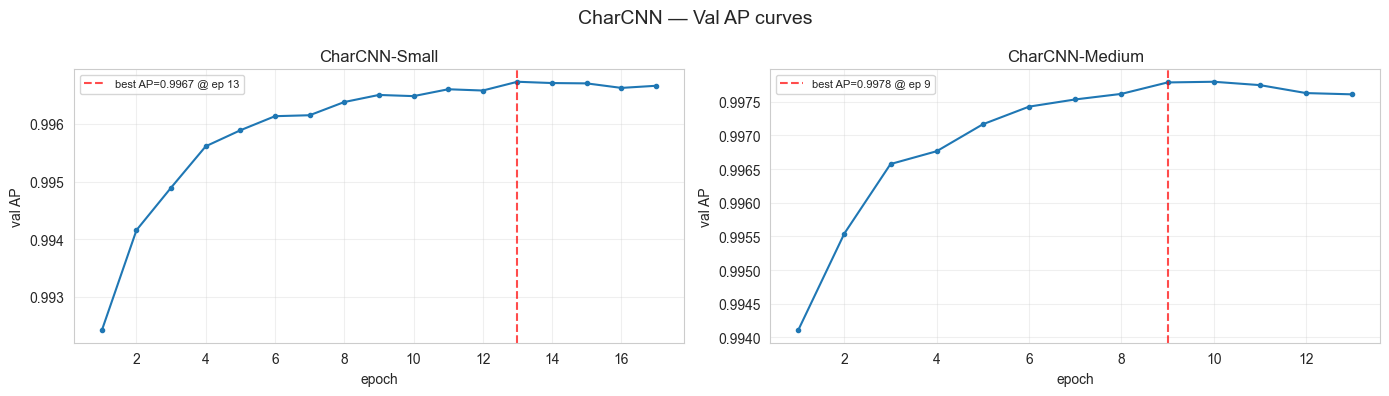

In [21]:
_fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (name, hist) in zip(
    axes, [("CharCNN-Small", hist_schar), ("CharCNN-Medium", hist_mchar)]
):
    ap = hist["val_ap"]
    best_i = best_state_epoch(hist["val_ap"])
    ax.plot(hist["epoch"], ap, marker="o", markersize=3, linewidth=1.5)
    ax.axvline(
        hist["epoch"][best_i],
        color="r",
        ls="--",
        alpha=0.7,
        label=f"best AP={ap[best_i]:.4f} @ ep {hist['epoch'][best_i]}",
    )
    ax.set_title(name)
    ax.set_xlabel("epoch")
    ax.set_ylabel("val AP")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.suptitle("CharCNN — Val AP curves", fontsize=14)
plt.tight_layout()
plt.savefig(f"{PATHS['plots_dir']}/charcnn_val_ap.png", dpi=140)
plt.show()

### Section 4 — CharBERT Training

In [22]:
class CharBERT(nn.Module):
    """
    Char-level Transformer с CLS-токеном и learnable positional encoding.

    - Pre-LN (norm_first=True) — стабильнее при from-scratch обучении.
    - Padding mask через src_key_padding_mask: CLS никогда не pad.
    - Attention доступен через hooks на encoder.layers[i].self_attn (шаг 8).
    """

    def __init__(
        self,
        vocab_size=130,
        d_model=64,
        nhead=4,
        num_layers=4,
        dim_feedforward=256,
        dropout=0.1,
        max_len=75,
    ):
        super().__init__()
        self.d_model = d_model
        self.max_len = max_len

        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
        # +1 позиция под CLS
        self.pos_embedding = nn.Parameter(torch.zeros(1, max_len + 1, d_model))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, 1)

        self._init_weights()

    def _init_weights(self):
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embedding, std=0.02)
        nn.init.normal_(self.embedding.weight, std=0.02)
        with torch.no_grad():
            self.embedding.weight[0].fill_(0.0)  # PAD остаётся нулевым
        nn.init.xavier_uniform_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def forward(self, x_long):
        # x_long: (B, L) int64, 0 = pad
        B, L = x_long.shape

        x = self.embedding(x_long)  # (B, L, D)

        # CLS prepend
        cls = self.cls_token.expand(B, -1, -1)  # (B, 1, D)
        x = torch.cat([cls, x], dim=1)  # (B, L+1, D)
        x = x + self.pos_embedding[:, : L + 1, :]

        # Padding mask: True = ignore
        mask_pad = x_long == 0  # (B, L)
        cls_mask = torch.zeros(B, 1, dtype=torch.bool, device=x_long.device)
        src_key_padding_mask = torch.cat([cls_mask, mask_pad], dim=1)

        encoded = self.encoder(x, src_key_padding_mask=src_key_padding_mask)
        cls_out = self.norm(encoded[:, 0, :])
        return self.head(cls_out).squeeze(-1)


CHARBERT_CONFIGS = {
    "CharBERT-Small": {
        "d_model": 64,
        "nhead": 4,
        "num_layers": 4,
        "dim_feedforward": 256,
        "dropout": 0.1,
        "max_len": MAX_LEN,
    },
    "CharBERT-Medium": {
        "d_model": 128,
        "nhead": 4,
        "num_layers": 6,
        "dim_feedforward": 512,
        "dropout": 0.1,
        "max_len": MAX_LEN,
    },
}

for name, cfg in CHARBERT_CONFIGS.items():
    m = CharBERT(**cfg)
    n = sum(p.numel() for p in m.parameters())
    print(f"{name:18s} | params={n:>9,d}")
    del m

CharBERT-Small     | params=  213,377
CharBERT-Medium    | params=1,216,513


In [23]:
NAME = "CharBERT-Small"
print(f"{'=' * 60}\n{NAME}\n{'=' * 60}")

loaded = load_deep_model(NAME, CharBERT, CHARBERT_CONFIGS[NAME])
if loaded is not None:
    charbert_small, hist_sbert, ap_sbert = loaded
else:
    charbert_small = CharBERT(**CHARBERT_CONFIGS[NAME])
    print(f"params: {sum(p.numel() for p in charbert_small.parameters()):,d}")
    t0 = time.perf_counter()
    charbert_small, ap_sbert, hist_sbert = train_deep_model(
        NAME,
        charbert_small,
        train_ds,
        val_ds,
        y_val_np=y_val,
        batch_size=512,
        lr=1e-3,
        weight_decay=0.01,
        pos_weight=POS_WEIGHT,
    )
    train_time_sbert = time.perf_counter() - t0
    save_deep_artifact(
        NAME,
        charbert_small,
        CHARBERT_CONFIGS[NAME],
        hist_sbert,
        ap_sbert,
        train_time_sbert,
    )
    print(f"\ndone in {train_time_sbert / 60:.1f} min | best val_ap={ap_sbert:.4f}\n")

assert ap_sbert > 0.99, f"{NAME}: val_ap={ap_sbert:.4f} — below threshold"

p_val_sbert = predict_deep(charbert_small, X_val_enc, batch_size=512)
p_test_id_sbert = predict_deep(charbert_small, X_test_id_enc, batch_size=512)
p_ood_sbert = predict_deep(charbert_small, X_test_ood_enc, batch_size=512)

charbert_small = release_gpu(charbert_small, "charbert_small")

CharBERT-Small
Loaded CharBERT-Small  (213,377 params, 36 epochs, val_ap=0.9973)

charbert_small      : cuda:0 → cpu
VRAM: 5.32 GB free


In [24]:
NAME = "CharBERT-Medium"
print(f"{'=' * 60}\n{NAME}\n{'=' * 60}")

loaded = load_deep_model(NAME, CharBERT, CHARBERT_CONFIGS[NAME])
if loaded is not None:
    charbert_medium, hist_mbert, ap_mbert = loaded
else:
    charbert_medium = CharBERT(**CHARBERT_CONFIGS[NAME])
    print(f"params: {sum(p.numel() for p in charbert_medium.parameters()):,d}")
    t0 = time.perf_counter()
    charbert_medium, ap_mbert, hist_mbert = train_deep_model(
        NAME,
        charbert_medium,
        train_ds,
        val_ds,
        y_val_np=y_val,
        batch_size=512,
        lr=1e-3,
        weight_decay=0.01,
        pos_weight=POS_WEIGHT,
    )
    train_time_mbert = time.perf_counter() - t0
    save_deep_artifact(
        NAME,
        charbert_medium,
        CHARBERT_CONFIGS[NAME],
        hist_mbert,
        ap_mbert,
        train_time_mbert,
    )
    print(f"\ndone in {train_time_mbert / 60:.1f} min | best val_ap={ap_mbert:.4f}\n")

assert ap_mbert > 0.99, f"{NAME}: val_ap={ap_mbert:.4f} — below threshold"

p_val_mbert = predict_deep(charbert_medium, X_val_enc, batch_size=512)
p_test_id_mbert = predict_deep(charbert_medium, X_test_id_enc, batch_size=512)
p_ood_mbert = predict_deep(charbert_medium, X_test_ood_enc, batch_size=512)

charbert_medium = release_gpu(charbert_medium, "charbert_medium")

CharBERT-Medium
Loaded CharBERT-Medium  (1,216,513 params, 36 epochs, val_ap=0.9979)

charbert_medium     : cuda:0 → cpu
VRAM: 5.32 GB free


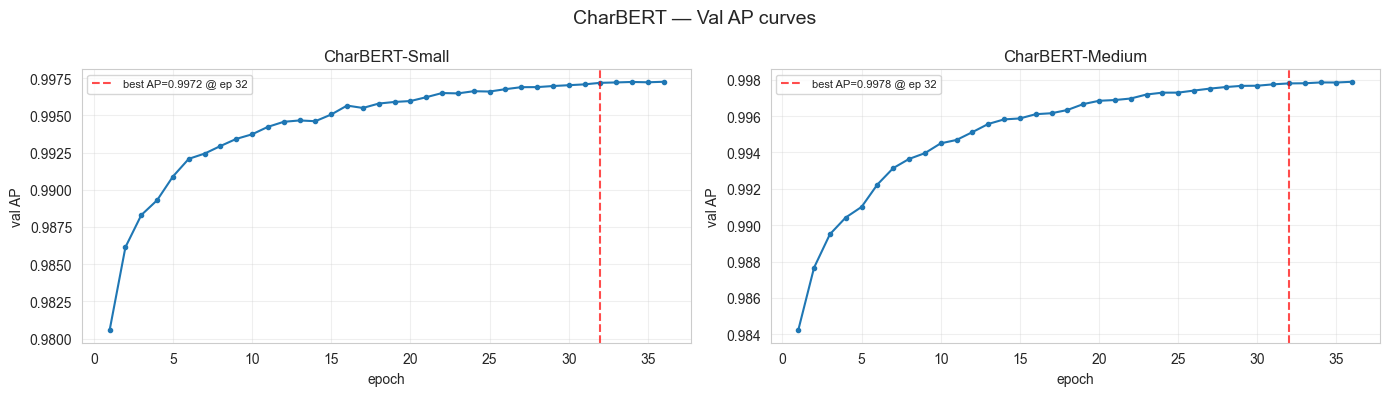

In [25]:
_fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (name, hist) in zip(
    axes, [("CharBERT-Small", hist_sbert), ("CharBERT-Medium", hist_mbert)]
):
    ap = hist["val_ap"]
    best_i = best_state_epoch(hist["val_ap"])
    ax.plot(hist["epoch"], ap, marker="o", markersize=3, linewidth=1.5)
    ax.axvline(
        hist["epoch"][best_i],
        color="r",
        ls="--",
        alpha=0.7,
        label=f"best AP={ap[best_i]:.4f} @ ep {hist['epoch'][best_i]}",
    )
    ax.set_title(name)
    ax.set_xlabel("epoch")
    ax.set_ylabel("val AP")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.suptitle("CharBERT — Val AP curves", fontsize=14)
plt.tight_layout()
plt.savefig(f"{PATHS['plots_dir']}/chatbert_val_ap.png", dpi=140)
plt.show()

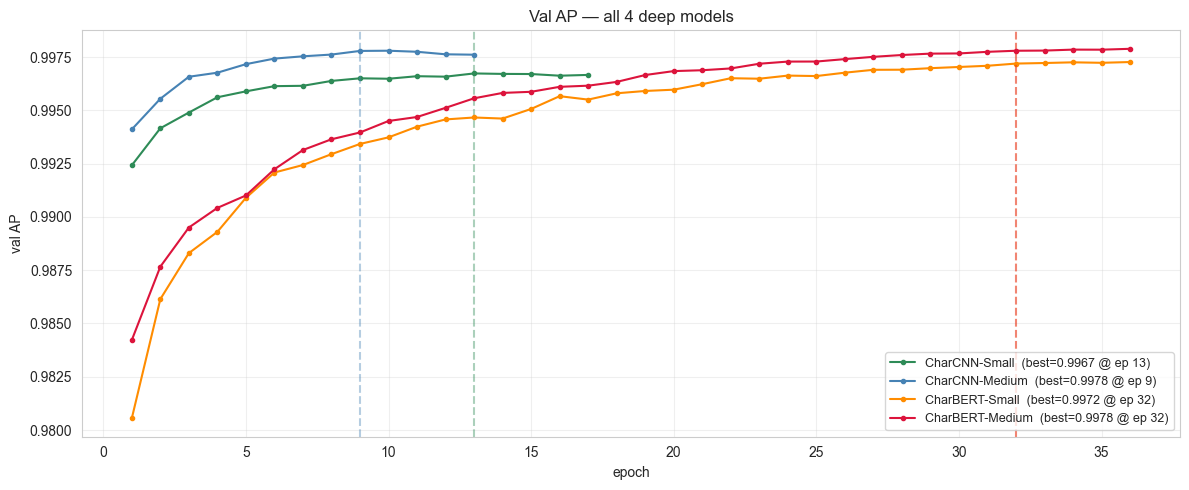

In [26]:
all_hist = {
    "CharCNN-Small": hist_schar,
    "CharCNN-Medium": hist_mchar,
    "CharBERT-Small": hist_sbert,
    "CharBERT-Medium": hist_mbert,
}
COLORS_DEEP = {
    "CharCNN-Small": "seagreen",
    "CharCNN-Medium": "steelblue",
    "CharBERT-Small": "darkorange",
    "CharBERT-Medium": "crimson",
}

_fig, ax = plt.subplots(figsize=(12, 5))
for name, hist in all_hist.items():
    ap = hist["val_ap"]
    best_i = best_state_epoch(hist["val_ap"])
    ax.plot(
        hist["epoch"],
        ap,
        marker="o",
        markersize=3,
        linewidth=1.5,
        color=COLORS_DEEP[name],
        label=f"{name}  (best={ap[best_i]:.4f} @ ep {hist['epoch'][best_i]})",
    )
    ax.axvline(hist["epoch"][best_i], color=COLORS_DEEP[name], ls="--", alpha=0.4)

ax.set_title("Val AP — all 4 deep models")
ax.set_xlabel("epoch")
ax.set_ylabel("val AP")
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout()
plt.savefig(f"{PATHS['plots_dir']}/deep_val_ap_all4.png", dpi=140)
plt.show()

### Step 4 — Metrics & Calibration

In [27]:
feature_probs = {"val": {}, "test_id": {}, "test_ood": {}}

X_val_raw = full_df.iloc[val_idx][PRETRAINED_FEAT].astype("float32")
X_id_raw = full_df.iloc[test_id_idx][PRETRAINED_FEAT].astype("float32")
X_ood_raw = full_df.iloc[test_ood_idx][PRETRAINED_FEAT].astype("float32")

for name, m in trained_models.items():
    for split, X_raw in [
        ("val", X_val_raw),
        ("test_id", X_id_raw),
        ("test_ood", X_ood_raw),
    ]:
        X_in = get_X_pretrained(name, X_raw)
        p = m.predict_proba(X_in)
        feature_probs[split][name] = p[:, 1] if p.ndim == 2 else p

print(f"Computed feature-model predictions: {len(trained_models)} models x 3 splits")

Computed feature-model predictions: 3 models x 3 splits


In [28]:
deep_val_probs = dict(
    zip(DEEP_MODEL_NAMES, [p_val_schar, p_val_mchar, p_val_sbert, p_val_mbert])
)

thresholds = dict(PRETRAINED_THRESHOLDS)
thresholds_recall = {}

print(f"{'model':18s} | FPR-thr | TPR@1e-3 | Recall-thr")
print("-" * 60)
for name in DEEP_MODEL_NAMES:
    thr, fpr_at, tpr_at = pick_threshold(y_val, deep_val_probs[name], TARGET_FPR)
    thresholds[name] = thr
    thresholds_recall[name] = pick_threshold_at_recall(
        y_val, deep_val_probs[name], 0.95
    )
    print(f"{name:18s} | {thr:7.4f} | {tpr_at:8.4f} | {thresholds_recall[name]:.4f}")

model              | FPR-thr | TPR@1e-3 | Recall-thr
------------------------------------------------------------
CharCNN-Small      |  0.9992 |   0.8205 | 0.9001
CharCNN-Medium     |  0.9408 |   0.8613 | 0.5640
CharBERT-Small     |  0.9944 |   0.8515 | 0.8800
CharBERT-Medium    |  0.9970 |   0.8651 | 0.9316


In [29]:
for name in trained_models:
    thresholds_recall[name] = pick_threshold_at_recall(
        y_val, feature_probs["val"][name], 0.95
    )
    print(f"{name:18s} | Recall-thr={thresholds_recall[name]:.4f}")

LightGBM           | Recall-thr=0.2863
XGBoost            | Recall-thr=0.2857
MLP                | Recall-thr=0.2469


In [30]:
deep_calibrators = {}
for name in DEEP_MODEL_NAMES:
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(deep_val_probs[name], y_val)
    deep_calibrators[name] = iso
    joblib.dump(iso, PATHS["models_dir"] / f"{name}_cal.pkl")
    print(f"{name:18s} | Isotonic saved")

CharCNN-Small      | Isotonic saved
CharCNN-Medium     | Isotonic saved
CharBERT-Small     | Isotonic saved
CharBERT-Medium    | Isotonic saved


In [31]:
test_id_probs = {
    **{n: feature_probs["test_id"][n] for n in FEATURE_MODEL_NAMES},
    "CharCNN-Small": p_test_id_schar,
    "CharCNN-Medium": p_test_id_mchar,
    "CharBERT-Small": p_test_id_sbert,
    "CharBERT-Medium": p_test_id_mbert,
}
test_ood_probs = {
    **{n: feature_probs["test_ood"][n] for n in FEATURE_MODEL_NAMES},
    "CharCNN-Small": p_ood_schar,
    "CharCNN-Medium": p_ood_mchar,
    "CharBERT-Small": p_ood_sbert,
    "CharBERT-Medium": p_ood_mbert,
}
assert set(test_id_probs) == set(MODEL_ORDER)
assert set(test_ood_probs) == set(MODEL_ORDER)
print(f"Probabilities ready for {len(MODEL_ORDER)} models")

Probabilities ready for 7 models


In [32]:
def build_metrics_table(probs_dict, y_true):
    """17-column metrics table using global thresholds + MODEL_ORDER."""
    rows = []
    for name in MODEL_ORDER:
        m = full_metrics_block(y_true, probs_dict[name], thresholds[name])
        m["model"] = name
        rows.append(m)
    return pd.DataFrame(rows).set_index("model")

In [33]:
metrics_id_df = build_metrics_table(test_id_probs, y_test_id)
metrics_id_df.to_csv(PATHS["models_dir"] / "reports" / "metrics_id.csv")
print(metrics_id_df.round(5).to_string())

                 accuracy  precision   recall       f1  roc_auc   pr_auc      tpr      fpr  fp_per_million    brier  tpr@fpr=1e-2  tpr@fpr=1e-3  tpr@fpr=1e-4  prec@rec=0.95  prec@rec=0.99  prec@prev=0.001  prec@prev=0.0001
model                                                                                                                                                                                                                         
LightGBM          0.84371    0.99821  0.65669  0.79221  0.98180  0.98066  0.65669  0.00098       980.05880  0.05176       0.79502       0.65761       0.47682        0.87656        0.73044          0.40146           0.06280
XGBoost           0.84481    0.99813  0.65917  0.79399  0.98189  0.98078  0.65917  0.00103      1026.72827  0.05150       0.79685       0.65860       0.48169        0.87676        0.72868          0.39123           0.06033
MLP               0.82501    0.99792  0.61558  0.76145  0.97684  0.97550  0.61558  0.00107      1066.73067  

In [34]:
metrics_ood_df = build_metrics_table(test_ood_probs, y_test_ood)
metrics_ood_df.to_csv(PATHS["models_dir"] / "reports" / "metrics_ood.csv")
print(metrics_ood_df.round(5).to_string())

                 accuracy  precision   recall       f1  roc_auc   pr_auc      tpr      fpr  fp_per_million    brier  tpr@fpr=1e-2  tpr@fpr=1e-3  tpr@fpr=1e-4  prec@rec=0.95  prec@rec=0.99  prec@prev=0.001  prec@prev=0.0001
model                                                                                                                                                                                                                         
LightGBM          0.77942    0.99852  0.58515  0.73789  0.94376  0.96117  0.58515  0.00098       980.05880  0.09107       0.71453       0.58625       0.31564        0.73239        0.56098          0.37408           0.05635
XGBoost           0.78076    0.99846  0.58773  0.73992  0.94206  0.96021  0.58773  0.00103      1026.72827  0.09231       0.71635       0.58715       0.32949        0.72194        0.55761          0.36427           0.05415
MLP               0.77799    0.99838  0.58253  0.73576  0.94671  0.96305  0.58253  0.00107      1066.73067  

In [35]:
def build_metrics_table_recall(probs_dict, y_true, split):
    rows = []
    for name in MODEL_ORDER:
        p = probs_dict[name]
        m = metrics_block(y_true, p, thresholds_recall[name])
        m["model"] = name
        m["split"] = split
        m["threshold_recall"] = thresholds_recall[name]
        rows.append(m)
    return pd.DataFrame(rows).set_index(["model", "split"])


recall_df = pd.concat(
    [
        build_metrics_table_recall(test_id_probs, y_test_id, "id"),
        build_metrics_table_recall(test_ood_probs, y_test_ood, "ood"),
    ]
)
recall_df.to_csv(PATHS["models_dir"] / "reports" / "metrics_recall_thr.csv")
print(recall_df.round(5).to_string())

                       accuracy  precision   recall       f1  roc_auc   pr_auc      tpr      fpr  fp_per_million    brier  threshold_recall
model           split                                                                                                                      
LightGBM        id      0.91599    0.87487  0.95084  0.91127  0.98180  0.98066  0.95084  0.11294    112940.10974  0.05176           0.28632
XGBoost         id      0.91641    0.87576  0.95062  0.91166  0.98189  0.98078  0.95062  0.11199    111993.38627  0.05150           0.28575
MLP             id      0.90044    0.84897  0.94946  0.89641  0.97684  0.97550  0.94946  0.14027    140268.41610  0.05857           0.24689
CharCNN-Small   id      0.97219    0.98796  0.95027  0.96875  0.99711  0.99672  0.95027  0.00961      9613.91017  0.01900           0.90011
CharCNN-Medium  id      0.97376    0.99229  0.94954  0.97044  0.99795  0.99766  0.94954  0.00613      6127.03429  0.01820           0.56397
CharBERT-Small  id  

In [36]:
brier_rows = []
for name in MODEL_ORDER:
    for split, y_true, probs in [
        ("id", y_test_id, test_id_probs),
        ("ood", y_test_ood, test_ood_probs),
    ]:
        p_raw = probs[name]
        if name in deep_calibrators:
            p_cal = deep_calibrators[name].predict(p_raw)
        elif name in calibrators:
            p_cal = calibrators[name].predict(p_raw)
        else:
            p_cal = None
        row = {
            "model": name,
            "split": split,
            "brier_raw": float(brier_score_loss(y_true, p_raw)),
        }
        if p_cal is not None:
            row["brier_cal"] = float(brier_score_loss(y_true, p_cal))
            row["delta"] = row["brier_cal"] - row["brier_raw"]
        brier_rows.append(row)

brier_df = pd.DataFrame(brier_rows).set_index(["model", "split"])
brier_df.to_csv(PATHS["models_dir"] / "reports" / "brier_comparison.csv")
print(brier_df.round(5).to_string())

                       brier_raw  brier_cal    delta
model           split                               
LightGBM        id       0.05176    0.05169 -0.00007
                ood      0.09107    0.09131  0.00025
XGBoost         id       0.05150    0.05145 -0.00005
                ood      0.09231    0.09243  0.00012
MLP             id       0.05857    0.05855 -0.00002
                ood      0.08677    0.08617 -0.00060
CharCNN-Small   id       0.01900    0.01822 -0.00078
                ood      0.06211    0.06164 -0.00047
CharCNN-Medium  id       0.01820    0.01510 -0.00310
                ood      0.07637    0.05776 -0.01861
CharBERT-Small  id       0.01864    0.01777 -0.00087
                ood      0.09390    0.09753  0.00363
CharBERT-Medium id       0.01616    0.01532 -0.00084
                ood      0.09971    0.10286  0.00315


### Step 5 — Visualizations

In [37]:
plot_order = metrics_ood_df.sort_values("pr_auc", ascending=False).index.tolist()
COLORS_BASE = {
    "LightGBM": "cadetblue",
    "XGBoost": "goldenrod",
    "MLP": "seagreen",
    "CharCNN-Small": "steelblue",
    "CharCNN-Medium": "crimson",
    "CharBERT-Small": "darkorange",
    "CharBERT-Medium": "rebeccapurple",
}
LINESTYLES = {
    "LightGBM": "-.",
    "XGBoost": "-.",
    "MLP": "-.",
    "CharCNN-Small": "-",
    "CharCNN-Medium": "-",
    "CharBERT-Small": "-",
    "CharBERT-Medium": "-",
}
print(f"Plot order: {plot_order}")

Plot order: ['CharCNN-Medium', 'CharCNN-Small', 'CharBERT-Small', 'MLP', 'CharBERT-Medium', 'LightGBM', 'XGBoost']


In [102]:
for name in DEEP_MODEL_NAMES:
    p_raw = test_ood_probs[name]
    p_cal = deep_calibrators[name].predict(p_raw)
    mp_raw, fp_raw = calibration_curve(y_test_ood, p_raw, n_bins=15, strategy="quantile")[1], calibration_curve(y_test_ood, p_raw, n_bins=15, strategy="quantile")[0]
    mp_cal, fp_cal = calibration_curve(y_test_ood, p_cal, n_bins=15, strategy="quantile")[1], calibration_curve(y_test_ood, p_cal, n_bins=15, strategy="quantile")[0]
    print(f"{name}:")
    print(f"  raw: n_bins={len(mp_raw)}, mean_pred[:3]={mp_raw[:3]}, frac_pos[:3]={fp_raw[:3]}")
    print(f"  cal: n_bins={len(mp_cal)}, mean_pred[:3]={mp_cal[:3]}, frac_pos[:3]={fp_cal[:3]}")
    print(f"  p_raw max/mean: {p_raw.max():.3f}/{p_raw.mean():.3f}")
    print(f"  p_cal max/mean: {p_cal.max():.3f}/{p_cal.mean():.3f}")
    print(f"  identical: {np.array_equal(p_raw, p_cal)}\n")

CharCNN-Small:
  raw: n_bins=13, mean_pred[:3]=[6.61107665e-10 1.42227052e-07 3.82369133e-06], frac_pos[:3]=[0.0002347  0.01234568 0.03290616]
  cal: n_bins=12, mean_pred[:3]=[0.         0.00015684 0.00115391], frac_pos[:3]=[0.01455175 0.03930131 0.0463303 ]
  p_raw max/mean: 1.000/0.479
  p_cal max/mean: 1.000/0.473
  identical: False

CharCNN-Medium:
  raw: n_bins=15, mean_pred[:3]=[6.48976976e-07 1.88693212e-05 1.28494378e-04], frac_pos[:3]=[0.00028164 0.0139417  0.04074543]
  cal: n_bins=13, mean_pred[:3]=[0.         0.00081314 0.00278439], frac_pos[:3]=[0.01957386 0.04343895 0.05594767]
  p_raw max/mean: 1.000/0.440
  p_cal max/mean: 1.000/0.473
  identical: False

CharBERT-Small:
  raw: n_bins=15, mean_pred[:3]=[1.26681321e-05 1.38751020e-05 1.62281860e-05], frac_pos[:3]=[0.03895982 0.09256478 0.08323162]
  cal: n_bins=11, mean_pred[:3]=[0.         0.00064195 0.00313638], frac_pos[:3]=[0.09552236 0.1807493  0.12809917]
  p_raw max/mean: 1.000/0.449
  p_cal max/mean: 1.000/0.436
 

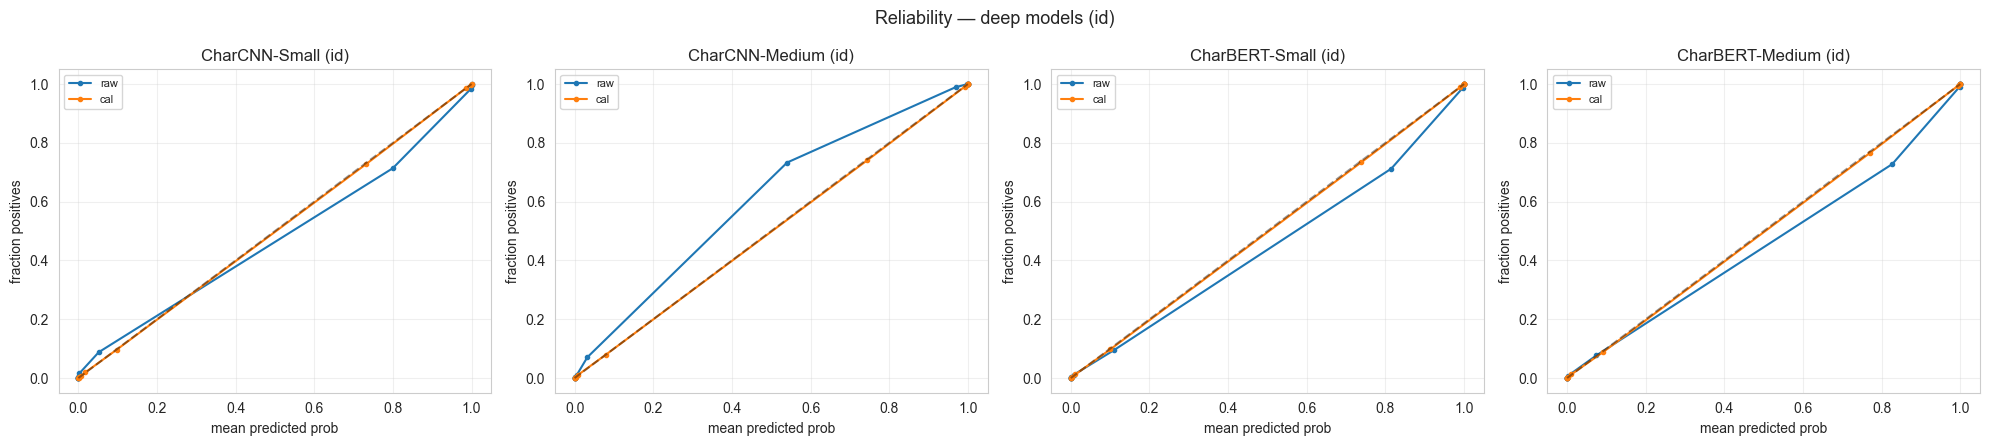

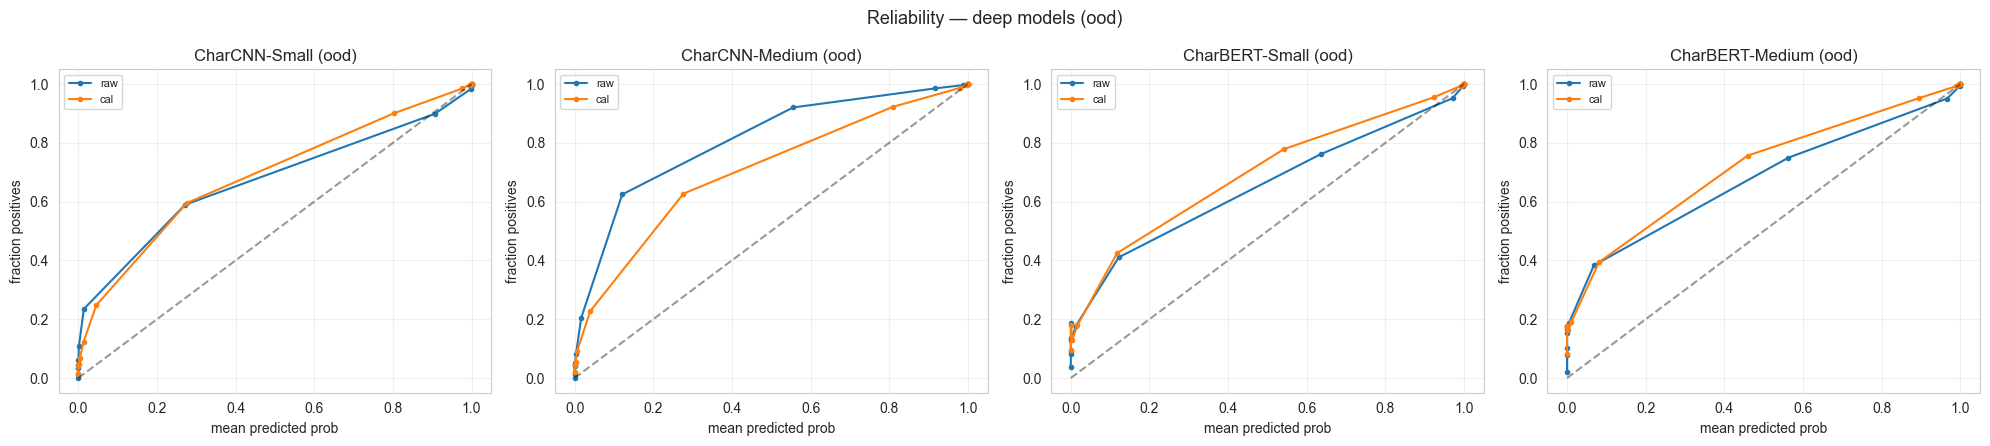

In [103]:
for split in ["id", "ood"]:
    y_true = y_test_id if split == "id" else y_test_ood
    probs = test_id_probs if split == "id" else test_ood_probs

    _fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    for ax, name in zip(axes, DEEP_MODEL_NAMES):
        p_raw = probs[name]
        p_cal = deep_calibrators[name].predict(p_raw)
        for label, p in [("raw", p_raw), ("cal", p_cal)]:
            frac_pos, mean_pred = calibration_curve(
                y_true, p, n_bins=15, strategy="quantile"
            )
            ax.plot(mean_pred, frac_pos, marker=".", label=label)
        ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
        ax.set_title(f"{name} ({split})")
        ax.set_xlabel("mean predicted prob")
        ax.set_ylabel("fraction positives")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
    plt.suptitle(f"Reliability — deep models ({split})", fontsize=13)
    plt.tight_layout()
    plt.savefig(f"{PATHS['plots_dir']}/reliability_deep_{split}.png", dpi=140)
    plt.show()

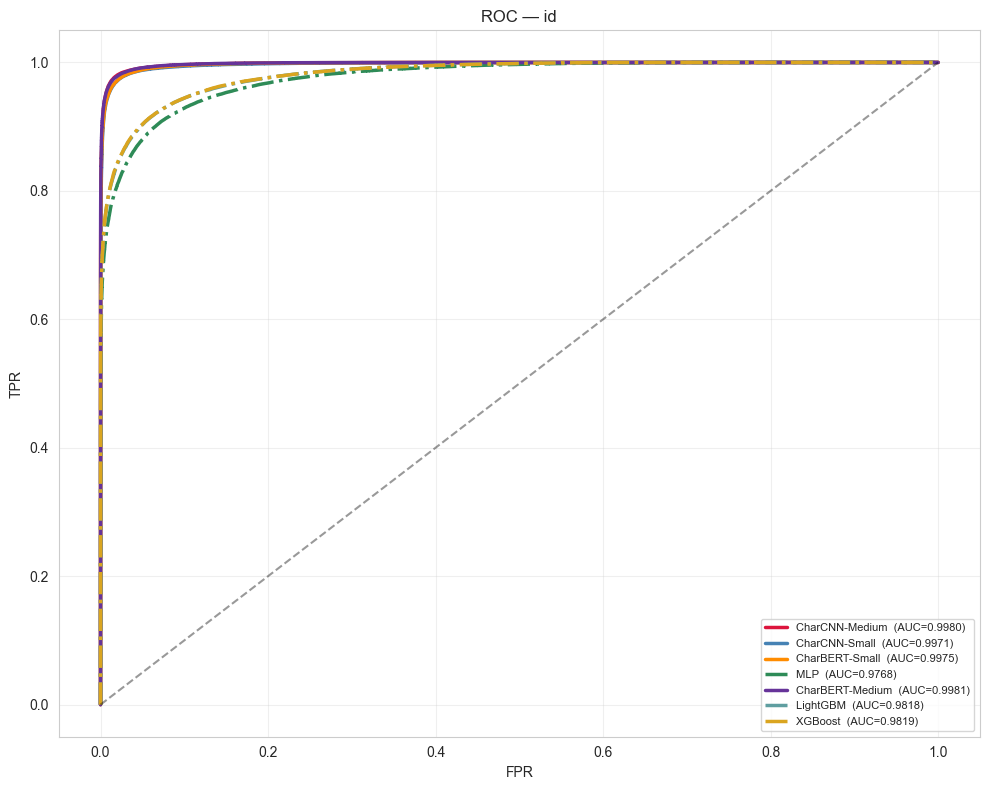

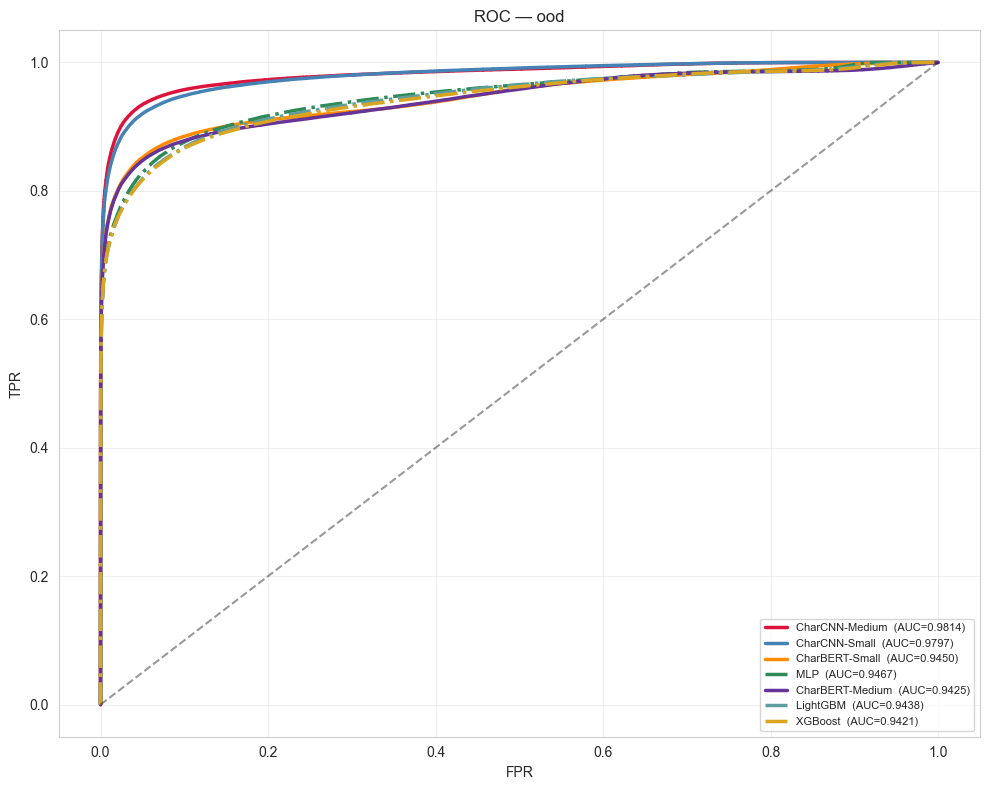

In [39]:
for split in ["id", "ood"]:
    y_true = y_test_id if split == "id" else y_test_ood
    probs = test_id_probs if split == "id" else test_ood_probs

    _fig, ax = plt.subplots(figsize=(10, 8))
    for name in plot_order:
        fpr, tpr, _ = roc_curve(y_true, probs[name])
        auc = roc_auc_score(y_true, probs[name])
        ax.plot(
            fpr,
            tpr,
            color=COLORS_BASE[name],
            linestyle=LINESTYLES[name],
            linewidth=2.5,
            label=f"{name}  (AUC={auc:.4f})",
        )
    ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
    ax.set_title(f"ROC — {split}")
    ax.set_xlabel("FPR")
    ax.set_ylabel("TPR")
    ax.legend(fontsize=8, loc="lower right")
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(f"{PATHS['plots_dir']}/roc_{split}.png", dpi=140)
    plt.show()

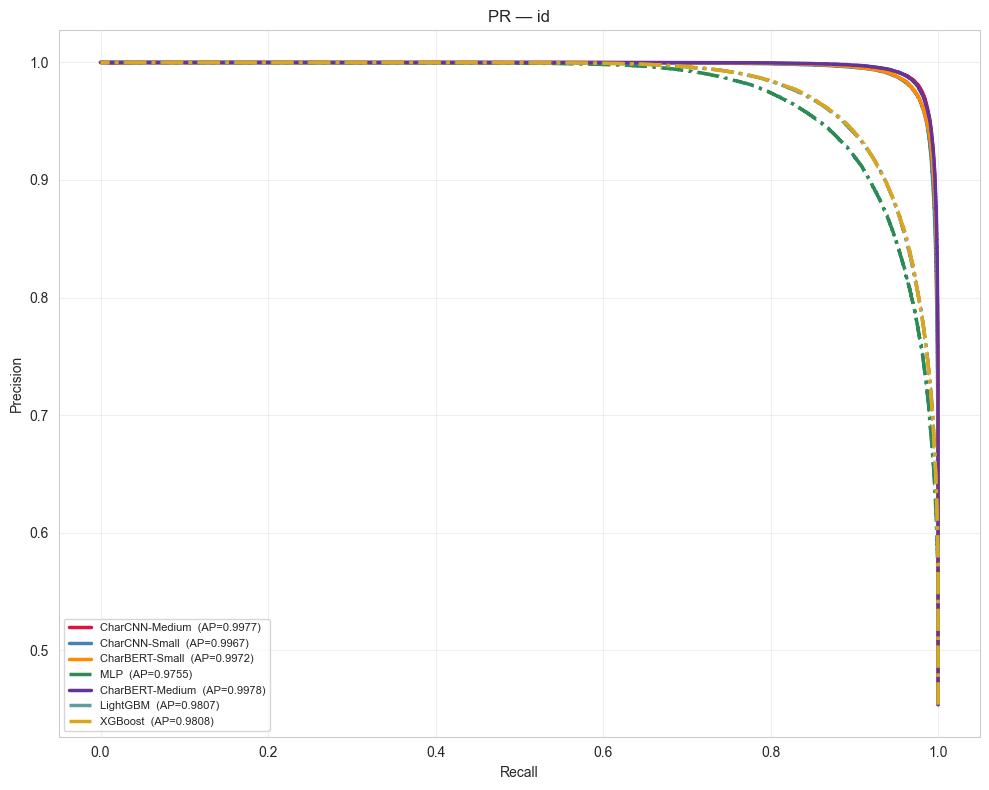

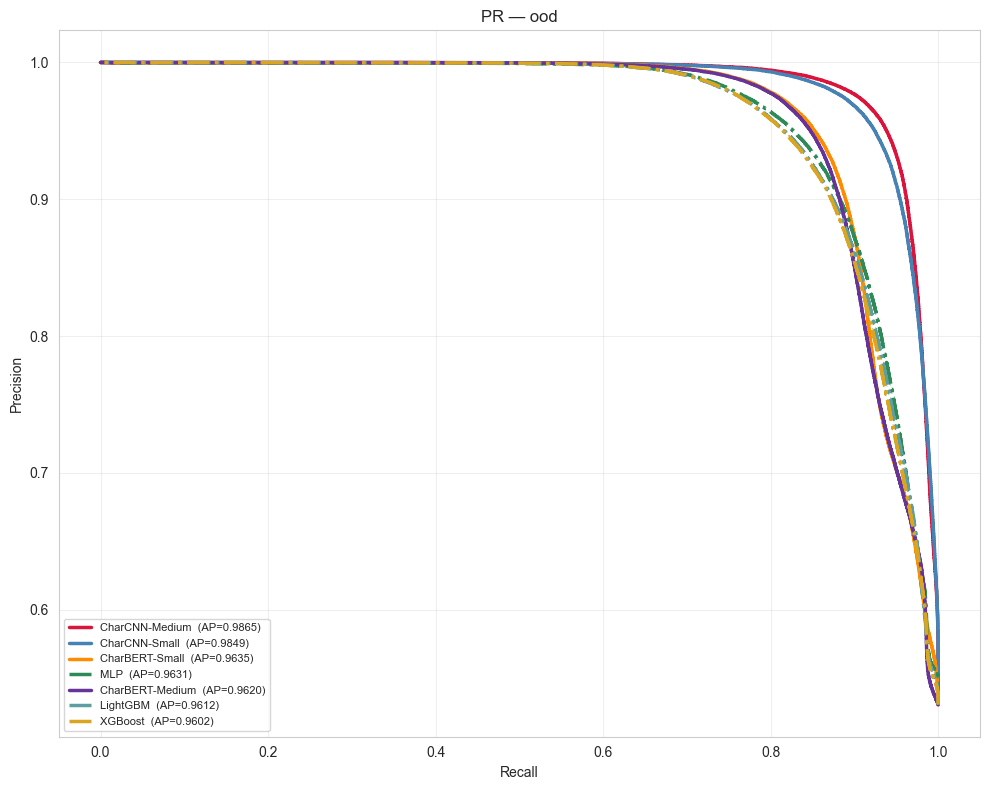

In [40]:
for split in ["id", "ood"]:
    y_true = y_test_id if split == "id" else y_test_ood
    probs = test_id_probs if split == "id" else test_ood_probs

    _fig, ax = plt.subplots(figsize=(10, 8))
    for name in plot_order:
        p, r, _ = precision_recall_curve(y_true, probs[name])
        ap = average_precision_score(y_true, probs[name])
        ax.plot(
            r,
            p,
            color=COLORS_BASE[name],
            linestyle=LINESTYLES[name],
            linewidth=2.5,
            label=f"{name}  (AP={ap:.4f})",
        )
    ax.set_title(f"PR — {split}")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend(fontsize=8, loc="lower left")
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(f"{PATHS['plots_dir']}/pr_{split}.png", dpi=140)
    plt.show()

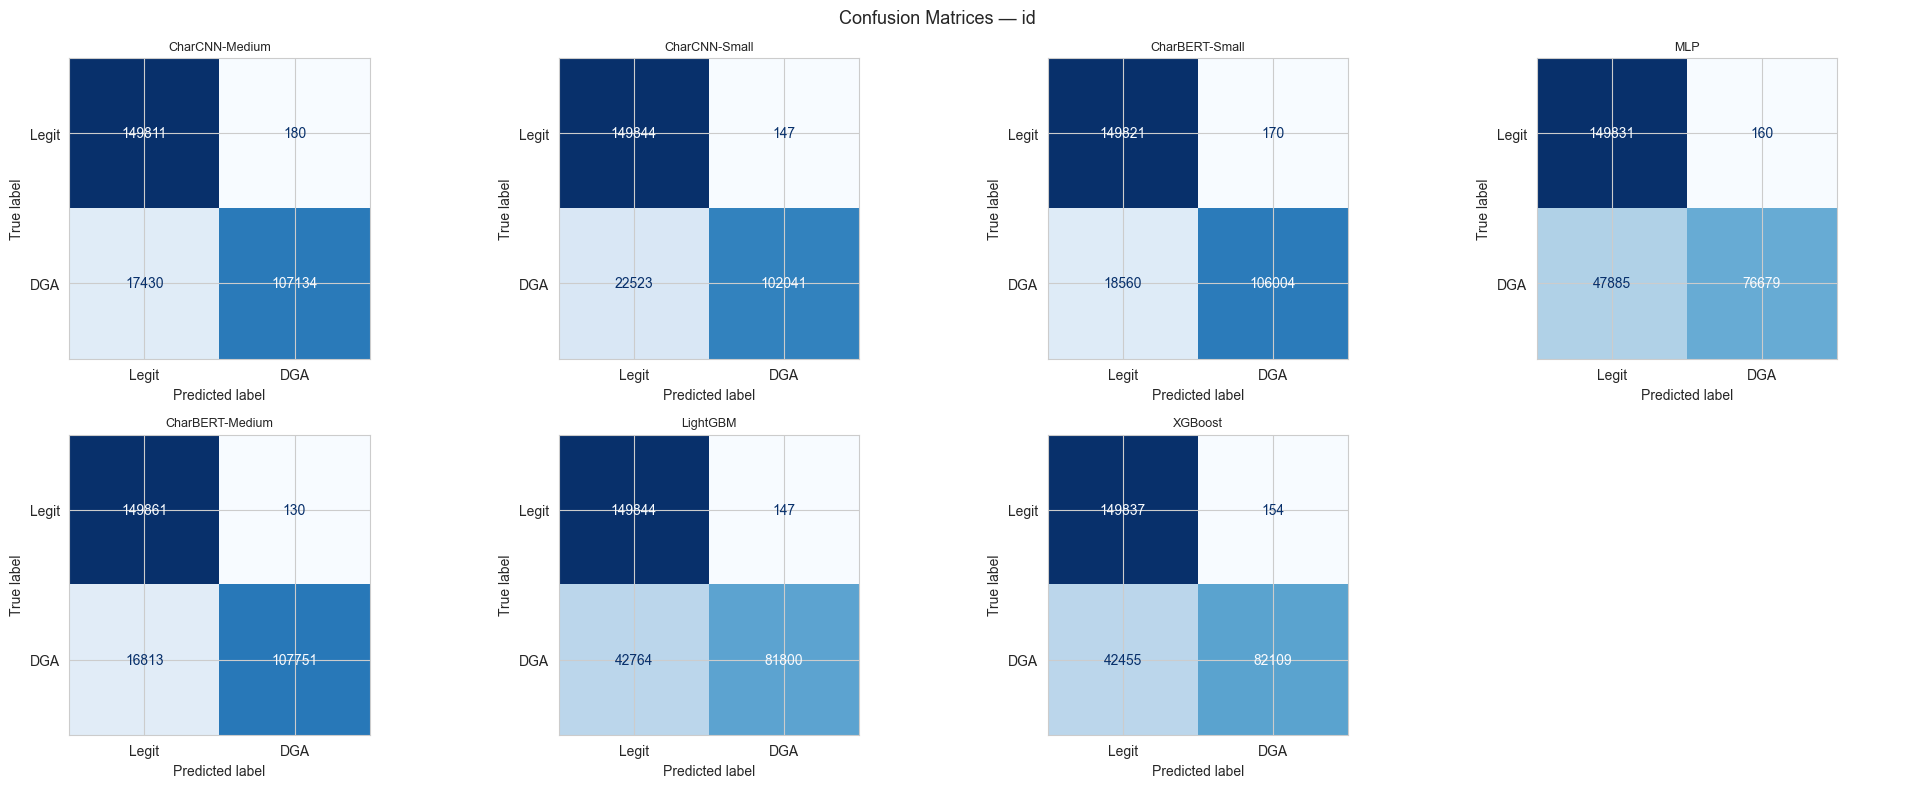

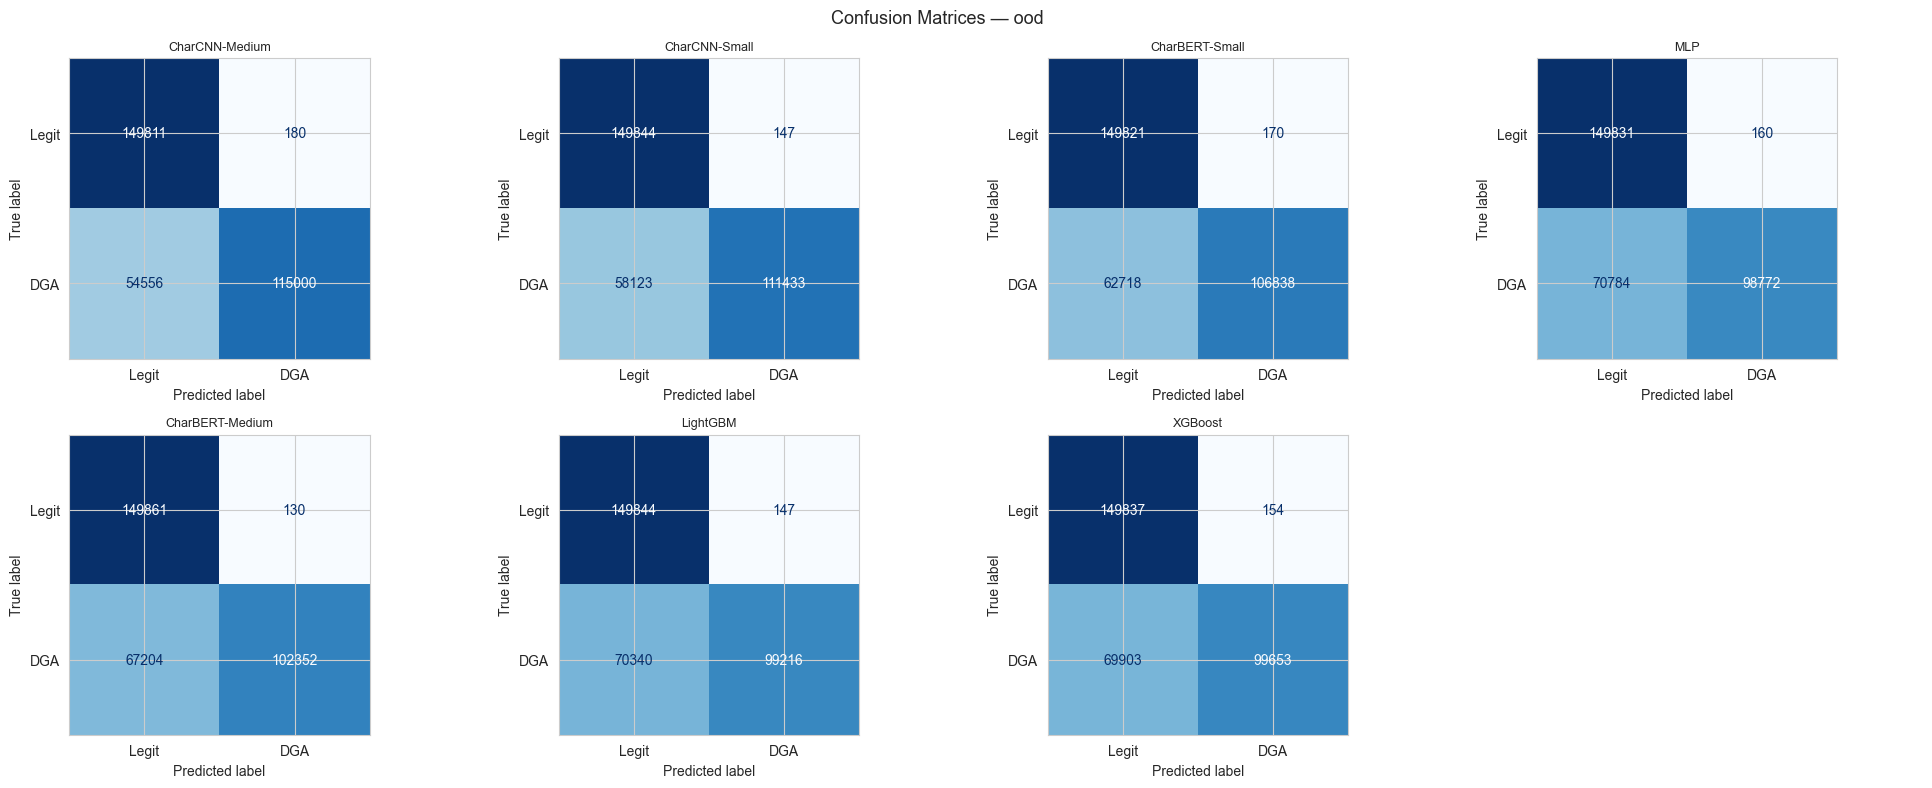

In [41]:
for split in ["id", "ood"]:
    y_true = y_test_id if split == "id" else y_test_ood
    probs = test_id_probs if split == "id" else test_ood_probs

    _fig, axes = plt.subplots(2, 4, figsize=(20, 8))
    axes_flat = axes.flatten()

    for ax, name in zip(axes.flatten(), plot_order):
        pred = (probs[name] >= thresholds[name]).astype(int)
        cm = confusion_matrix(y_true, pred, labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=["Legit", "DGA"]).plot(
            ax=ax, cmap="Blues", colorbar=False, values_format="d"
        )
        ax.set_title(name, fontsize=9)

    for ax in axes_flat[len(plot_order) :]:
        ax.axis("off")

    plt.suptitle(f"Confusion Matrices — {split}", fontsize=13)
    plt.tight_layout()
    plt.savefig(f"{PATHS['plots_dir']}/cm_{split}.png", dpi=140)
    plt.show()

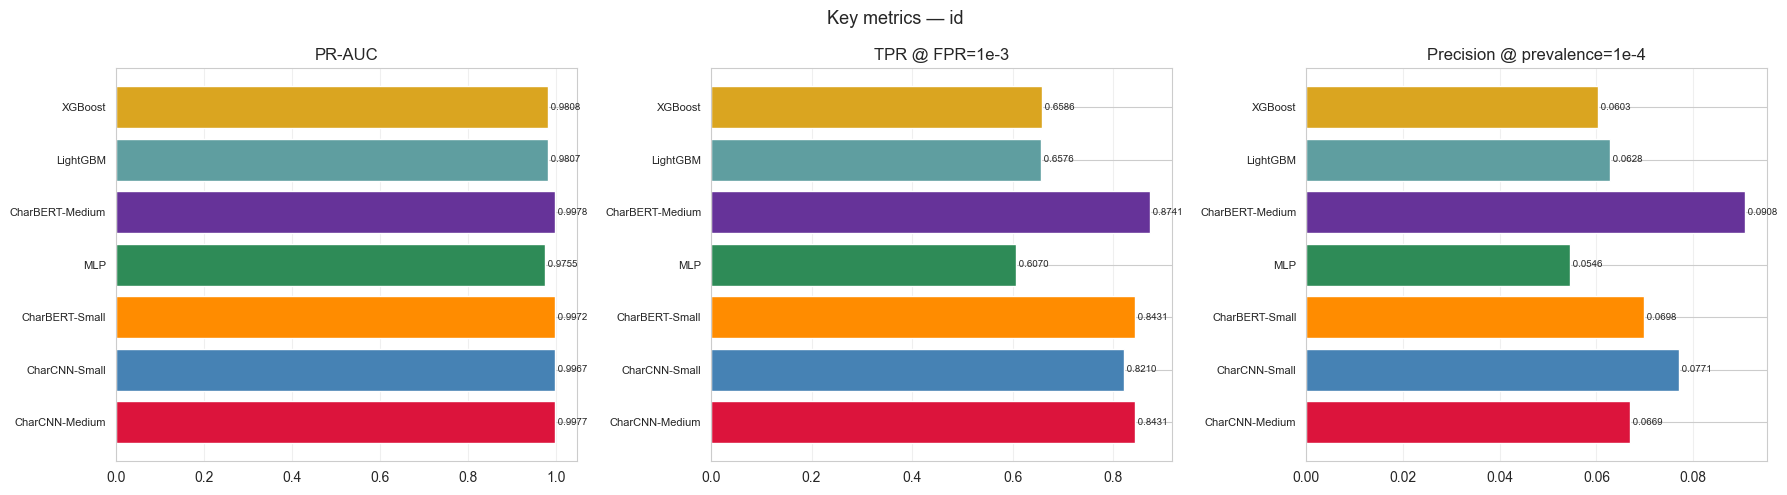

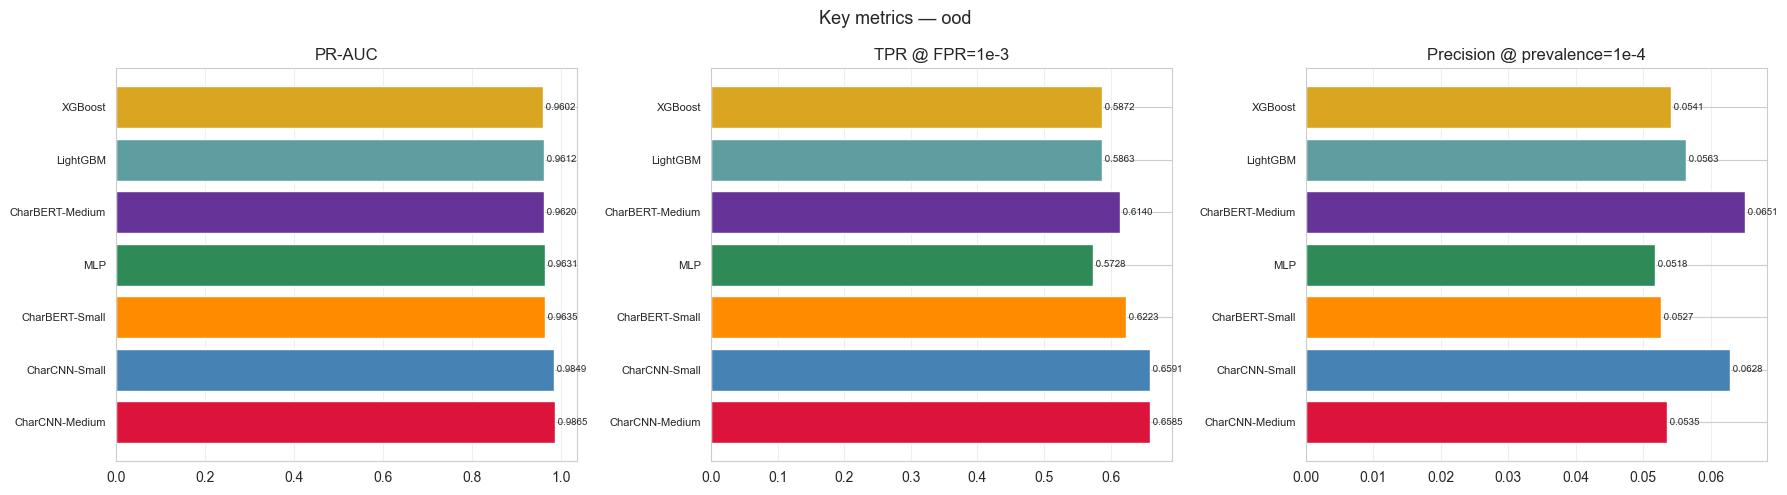

In [42]:
bar_metrics = [
    ("pr_auc", "PR-AUC"),
    ("tpr@fpr=1e-3", "TPR @ FPR=1e-3"),
    ("prec@prev=0.0001", "Precision @ prevalence=1e-4"),
]

for split, df in [("id", metrics_id_df), ("ood", metrics_ood_df)]:
    _fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, (metric, title) in zip(axes, bar_metrics):
        vals = df.loc[plot_order, metric]
        ax.barh(
            range(len(vals)), vals.values, color=[COLORS_BASE[n] for n in plot_order]
        )
        ax.set_yticks(range(len(vals)))
        ax.set_yticklabels(vals.index, fontsize=8)
        ax.set_title(title)
        ax.grid(axis="x", alpha=0.3)
        for i, v in enumerate(vals.values):
            ax.text(v, i, f" {v:.4f}", va="center", fontsize=7)

    plt.suptitle(f"Key metrics — {split}", fontsize=13)
    plt.tight_layout()
    plt.savefig(f"{PATHS['plots_dir']}/bar_metrics_{split}.png", dpi=140)
    plt.show()

### Step 6 — Per-Family & Error Analysis

In [43]:
fam_recalls = {}
for name in MODEL_ORDER:
    fam_recalls[name] = per_family_recall(
        df_test_ood, test_ood_probs[name], thresholds[name]
    )

fam_df = pd.DataFrame(fam_recalls)
fam_df["mean"] = fam_df.mean(axis=1)

WORDLIST_FAMILIES = {
    "gozi-gpl",
    "gozi-luther",
    "gozi-nasa",
    "gozi-rfc4343",
    "matsnu",
    "nymaim",
    "pizd",
    "suppobox-1",
    "suppobox-2",
    "suppobox-3",
    "rovnix",
}
fam_df["type"] = fam_df.index.map(
    lambda f: "wordlist" if f in WORDLIST_FAMILIES else "other"
)

fam_df = fam_df.sort_values("mean")
fam_df.to_csv(PATHS["models_dir"] / "reports" / "per_family_recall_ood.csv")

print("=== per-family recall on test_ood ===")
print(fam_df.round(3).to_string())

=== per-family recall on test_ood ===
              LightGBM  XGBoost    MLP  CharCNN-Small  CharCNN-Medium  CharBERT-Small  CharBERT-Medium   mean      type
suppobox-1       0.007    0.010  0.003          0.175           0.201           0.117            0.102  0.088  wordlist
simda            0.089    0.076  0.063          0.190           0.218           0.166            0.122  0.132     other
proslikefan      0.365    0.370  0.348          0.444           0.460           0.429            0.383  0.400     other
shiotob          0.591    0.606  0.728          0.778           0.743           0.560            0.464  0.639     other
pykspa           0.605    0.606  0.567          0.708           0.748           0.706            0.684  0.660     other
fobber-v2        0.755    0.755  0.606          0.658           0.707           0.817            0.805  0.729     other
dircrypt         0.768    0.771  0.759          0.825           0.848           0.802            0.796  0.795     other
cr

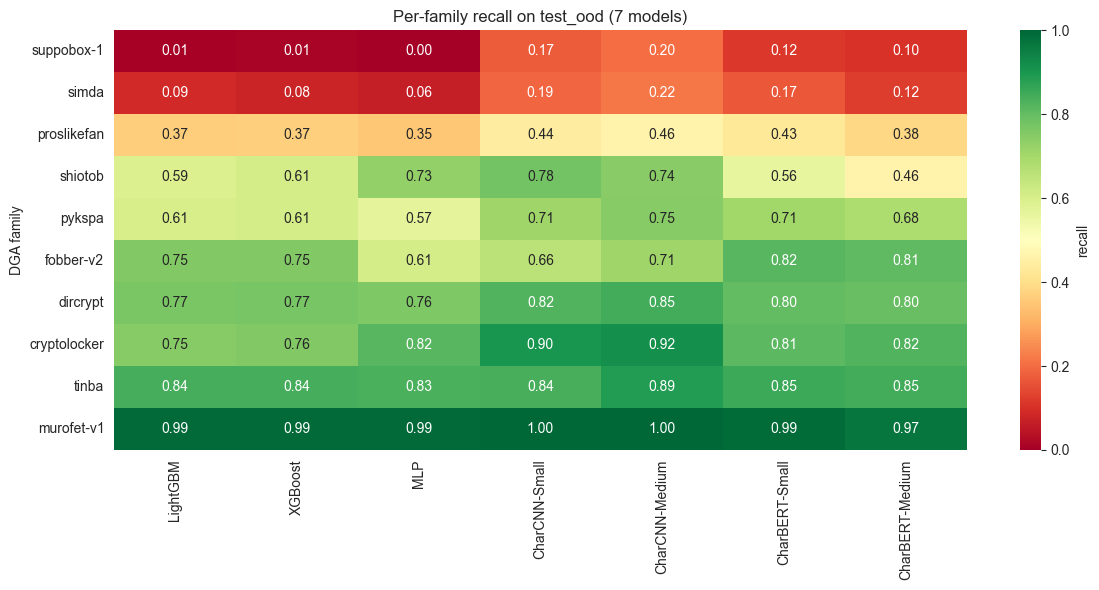

In [44]:
plot_cols = MODEL_ORDER

_fig, ax = plt.subplots(figsize=(12, max(6, len(fam_df) * 0.4)))
sns.heatmap(
    fam_df[plot_cols].astype(float),
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    cbar_kws={"label": "recall"},
    ax=ax,
)
ax.set_title("Per-family recall on test_ood (7 models)", fontsize=12)
ax.set_xlabel("")
ax.set_ylabel("DGA family")
plt.tight_layout()
plt.savefig(f"{PATHS['plots_dir']}/per_family_recall_heatmap.png", dpi=140)
plt.show()

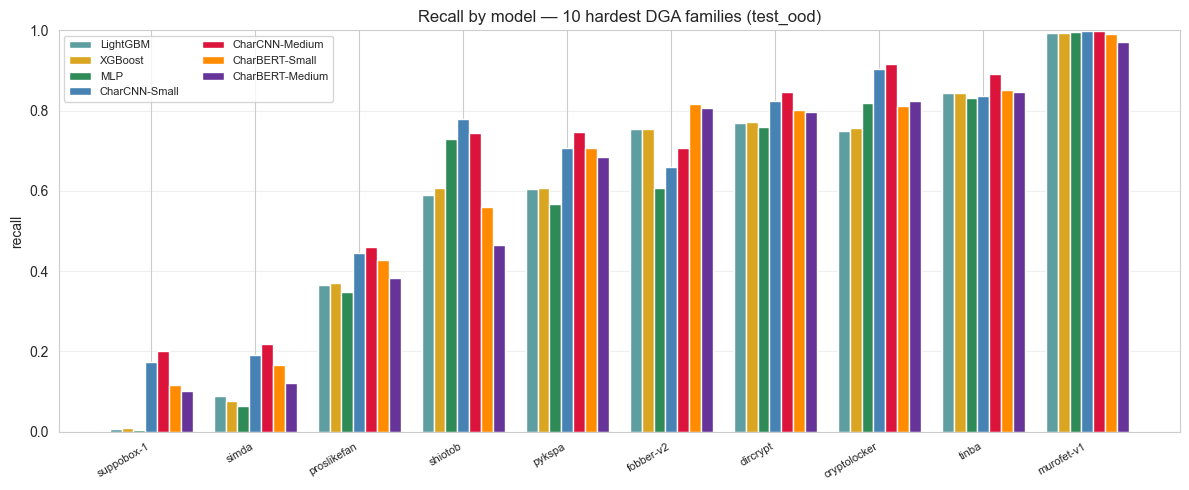

In [45]:
worst_n = min(10, len(fam_df))
worst = fam_df.head(worst_n)

_fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(worst))
w = 0.8 / len(plot_cols)
for i, name in enumerate(plot_cols):
    offset = (i - len(plot_cols) / 2 + 0.5) * w
    ax.bar(x + offset, worst[name].values, w, label=name, color=COLORS_BASE[name])

ax.set_xticks(x)
ax.set_xticklabels(worst.index, rotation=30, ha="right", fontsize=8)
ax.set_ylabel("recall")
ax.set_ylim(0, 1)
ax.set_title(f"Recall by model — {worst_n} hardest DGA families (test_ood)")
ax.legend(fontsize=8, ncol=2)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{PATHS['plots_dir']}/per_family_recall_worst.png", dpi=140)
plt.show()

In [46]:
all_errors = {}

for name in MODEL_ORDER:
    fp, fn = save_top_errors(
        name,
        y_test_ood,
        df_test_ood,
        test_ood_probs[name],
        thresholds[name],
        PATHS["models_dir"] / "errors",
        n=N_TOP_ERRORS,
    )
    all_errors[name] = {"FP": fp, "FN": fn}

    print(f"\n{'=' * 60}\n{name}\n{'=' * 60}")
    print(f"FP (top {len(fp)}):")
    print(fp.to_string(index=False))
    print(f"\nFN (top {len(fn)}):")
    print(fn.to_string(index=False))

print(f"\nAll per-model errors saved to {PATHS['models_dir'] / 'errors'}")


LightGBM
FP (top 10):
                              domain class     prob
             skdjht3eigjsfdgfddf.com legit 0.999994
        ojzs12ngwxrf3qfsusw578rl.com legit 0.999988
                   skrdnjsdirrnr.top legit 0.999732
                  qldkrmfkrnaocj.top legit 0.999651
                      shkmgmcnuh.org legit 0.999578
                jxpxkyjtyxzrgszyy.cn legit 0.999510
                      fxbkfrumxr.top legit 0.999497
nkbihfbeogaeaobhlefnkodbefgpgknn.com legit 0.999471
                    a20ad534e200.com legit 0.999278
                      luckyjetmd.top legit 0.999026

FN (top 10):
  domain class         prob
qexix.eu simda 2.615669e-09
gacif.eu simda 3.075677e-09
vopig.eu simda 3.236948e-09
ganiz.eu simda 3.598490e-09
gaduz.eu simda 3.716731e-09
pupeg.eu simda 4.547578e-09
vopaz.eu simda 4.962174e-09
vopib.eu simda 5.105313e-09
galic.eu simda 5.492576e-09
ganah.eu simda 5.546301e-09

XGBoost
FP (top 10):
                              domain class     prob
         

In [47]:
fn_summary = pd.DataFrame()

for name in MODEL_ORDER:
    pred = (test_ood_probs[name] >= thresholds[name]).astype(int)
    fn_mask = (df_test_ood["label"] == 1) & (pred == 0)
    fn_summary[name] = df_test_ood.loc[fn_mask, "class"].value_counts()

fn_summary = fn_summary.fillna(0).astype(int)
fn_summary["Total_FN"] = fn_summary.sum(axis=1)
fn_summary = fn_summary.sort_values("Total_FN", ascending=False)
fn_summary.to_csv(PATHS["models_dir"] / "reports" / "fn_by_family_ood.csv")

print("=== FN by family (test_ood) ===")
print(fn_summary.to_string())

# Примеры доменов из худшего семейства
max_fn_family = fn_summary.index[0]
fam_size = int((df_test_ood["class"] == max_fn_family).sum())
print(
    f"\nFamily with highest total FN: {max_fn_family} "
    f"({int(fn_summary.loc[max_fn_family, 'Total_FN'])}/{fam_size} missed, "
    f"recall={1 - fn_summary.loc[max_fn_family, 'Total_FN'] / fam_size:.3f})"
)
print("\nSample domains:")
for d in df_test_ood[df_test_ood["class"] == max_fn_family]["domain"].head(10):
    print(f"  {d}")

=== FN by family (test_ood) ===
              LightGBM  XGBoost    MLP  CharCNN-Small  CharCNN-Medium  CharBERT-Small  CharBERT-Medium  Total_FN
class                                                                                                           
simda            18227    18476  18735          16200           15650           16684            17558    121530
proslikefan      12697    12590  13034          11122           10800           11426            12336     84005
suppobox-1        9492     9465   9526           7887            7640            8441             8585     61036
shiotob           8189     7870   5431           4434            5136            8798            10722     50580
fobber-v2         4909     4906   7881           6830            5858            3657             3893     37934
dircrypt          4639     4577   4817           3506            3049            3961             4090     28639
cryptolocker      5037     4880   3616           1939           

In [48]:
error_masks = {}
for name in MODEL_ORDER:
    pred = (test_ood_probs[name] >= thresholds[name]).astype(int)
    error_masks[name] = pred != y_test_ood

# Домен ошибочен, если хотя бы у одной модели ошибка
any_error = np.logical_or.reduce([m for m in error_masks.values()])
# Домен ошибочен, если у ВСЕХ моделей ошибка
all_error = np.logical_and.reduce([m for m in error_masks.values()])

n_any = int(any_error.sum())
n_all = int(all_error.sum())
print(
    f"Domains with error in >=1 model:  {n_any} / {len(y_test_ood)} ({n_any / len(y_test_ood) * 100:.2f}%)"
)
print(
    f"Domains with error in ALL 7 models: {n_all} / {len(y_test_ood)} ({n_all / len(y_test_ood) * 100:.2f}%)"
)

# Примеры доменов
if n_all > 0:
    all_err_df = df_test_ood[all_error][["domain", "class"]].copy()
    print(f"\nПримеры (первые 15 из {n_all}):")
    print(all_err_df.head(15).to_string(index=False))
    all_err_df.to_csv(
        PATHS["models_dir"] / "errors" / "all_models_fail_ood.csv", index=False
    )

Domains with error in >=1 model:  96767 / 319547 (30.28%)
Domains with error in ALL 7 models: 35211 / 319547 (11.02%)

Примеры (первые 15 из 35211):
                      domain       class
        jemqorlyqpenkures.kz       legit
            n0hy9e41ygev.com       legit
              shkmgmcnuh.org       legit
ojzs12ngwxrf3qfsusw578rl.com       legit
                 cktehley.in proslikefan
              ozeddzassc.com   fobber-v2
                    lymew.eu       simda
                jelogyr.info       simda
          thoughtperfect.net  suppobox-1
              mqosnorhir.com   fobber-v2
                 xcyfosr.com proslikefan
               cunewlkc.name proslikefan
                punulel.info       simda
           prettymillion.net  suppobox-1
                  ejvkji.net      pykspa


In [49]:
fam_compare = pd.DataFrame(
    {
        "deep_mean": fam_df[DEEP_MODEL_NAMES].mean(axis=1),
        "feature_mean": fam_df[FEATURE_MODEL_NAMES].mean(axis=1),
        "best_deep": fam_df[DEEP_MODEL_NAMES].max(axis=1),
        "best_feature": fam_df[FEATURE_MODEL_NAMES].max(axis=1),
    }
)
fam_compare["deep_minus_feature"] = (
    fam_compare["deep_mean"] - fam_compare["feature_mean"]
)
fam_compare = fam_compare.sort_values("deep_minus_feature")

fam_compare.to_csv(PATHS["models_dir"] / "reports" / "family_deep_vs_feature.csv")
print("=== Deep vs Feature — per family ===")
print(fam_compare.round(3).to_string())

=== Deep vs Feature — per family ===
              deep_mean  feature_mean  best_deep  best_feature  deep_minus_feature
shiotob           0.636         0.642      0.778         0.728              -0.005
murofet-v1        0.990         0.994      1.000         0.995              -0.004
tinba             0.856         0.839      0.890         0.843               0.017
fobber-v2         0.747         0.705      0.817         0.755               0.042
dircrypt          0.817         0.766      0.848         0.771               0.051
proslikefan       0.429         0.361      0.460         0.370               0.068
cryptolocker      0.864         0.774      0.915         0.819               0.089
simda             0.174         0.076      0.218         0.089               0.098
pykspa            0.711         0.593      0.748         0.606               0.118
suppobox-1        0.148         0.006      0.201         0.010               0.142


### Step 7 — Latency

In [50]:
def _benchmark_loop(step_fn, n_warm, n, device):
    """Runs n_warm + n forward passes via step_fn(). Returns mean time in seconds."""
    for _ in range(n_warm):
        step_fn()
    if device is not None and device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(n):
        step_fn()
    if device is not None and device.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n


def benchmark_single(model, X_one, n_warm=20, n=200, device=None):
    """Single-input latency (ms) for tensor-input model (CharCNN / CharBERT)."""
    model.eval()
    if device is not None:
        model = model.to(device)
        X_one = X_one.to(device)
    with torch.no_grad():
        sec = _benchmark_loop(lambda: model(X_one), n_warm, n, device)
    return sec * 1000


def benchmark_batch(model, X_batch, n_warm=5, n=20, device=None):
    """Batch latency (s) for tensor-input model."""
    model.eval()
    if device is not None:
        model = model.to(device)
        X_batch = X_batch.to(device)
    with torch.no_grad():
        return _benchmark_loop(lambda: model(X_batch), n_warm, n, device)

In [51]:
feature_latency = {}
for name, value in trained_models.items():
    m = value
    X_one = get_X_pretrained(
        name, full_df.iloc[test_ood_idx[:1]][PRETRAINED_FEAT].astype("float32")
    )
    X_batch = get_X_pretrained(
        name, full_df.iloc[test_ood_idx[:1024]][PRETRAINED_FEAT].astype("float32")
    )

    # sklearn predict_proba: single-item loop, batch
    t0 = time.perf_counter()
    for _ in range(200):
        _ = m.predict_proba(X_one)
    single_ms = (time.perf_counter() - t0) / 200 * 1000

    t0 = time.perf_counter()
    for _ in range(20):
        _ = m.predict_proba(X_batch)
    batch_s = (time.perf_counter() - t0) / 20

    _buf = io.BytesIO()
    joblib.dump(m, _buf)
    size_mb = _buf.tell() / 1e6
    del _buf
    feature_latency[name] = {
        "single_ms": single_ms,
        "batch_1024_s": batch_s,
        "throughput_domains_s": 1024 / batch_s,
        "model_size_mb": size_mb,
    }
    print(
        f"{name:12s} | single={single_ms:7.3f} ms | batch={batch_s:6.3f} s | "
        f"throughput={1024 / batch_s:8.0f} dom/s | size={size_mb:.2f} MB"
    )

LightGBM     | single=  1.439 ms | batch= 0.019 s | throughput=   53709 dom/s | size=10.48 MB
XGBoost      | single=  4.474 ms | batch= 0.013 s | throughput=   80424 dom/s | size=10.41 MB
MLP          | single=  0.865 ms | batch= 0.001 s | throughput=  763313 dom/s | size=0.28 MB


In [52]:
deep_models = {
    "CharCNN-Small": char_cnn_small,
    "CharCNN-Medium": char_cnn_medium,
    "CharBERT-Small": charbert_small,
    "CharBERT-Medium": charbert_medium,
}

deep_latency_cpu = {}
X_one_ood = X_test_ood_enc[:1]
X_batch_ood = X_test_ood_enc[:1024]

for name, value in deep_models.items():
    model = value.cpu()
    ms = benchmark_single(model, X_one_ood, device=torch.device("cpu"))
    s_batch = benchmark_batch(model, X_batch_ood, device=torch.device("cpu"))
    # Размер .pt
    size_mb = (PATHS["models_dir"] / f"{name}.pt").stat().st_size / 1e6
    deep_latency_cpu[name] = {
        "single_ms": ms,
        "batch_1024_s": s_batch,
        "throughput_domains_s": 1024 / s_batch,
        "model_size_mb": size_mb,
    }
    print(
        f"{name:18s} (cpu) | single={ms:7.2f} ms | batch={s_batch:6.2f} s | "
        f"throughput={1024 / s_batch:7.0f} dom/s | size={size_mb:.2f} MB"
    )

CharCNN-Small      (cpu) | single=   0.76 ms | batch=  0.12 s | throughput=   8256 dom/s | size=0.74 MB
CharCNN-Medium     (cpu) | single=   1.88 ms | batch=  0.44 s | throughput=   2322 dom/s | size=5.05 MB
CharBERT-Small     (cpu) | single=   1.48 ms | batch=  0.47 s | throughput=   2162 dom/s | size=0.87 MB
CharBERT-Medium    (cpu) | single=   2.85 ms | batch=  1.38 s | throughput=    740 dom/s | size=4.90 MB


In [53]:
deep_latency_gpu = {}
if torch.cuda.is_available():
    for name, value in deep_models.items():
        model = value.to(DEVICE)
        ms = benchmark_single(model, X_one_ood, device=DEVICE)
        s_batch = benchmark_batch(model, X_batch_ood, device=DEVICE)
        deep_latency_gpu[name] = {
            "single_ms": ms,
            "batch_1024_s": s_batch,
            "throughput_domains_s": 1024 / s_batch,
            "model_size_mb": deep_latency_cpu[name]["model_size_mb"],
        }
        print(
            f"{name:18s} (gpu) | single={ms:7.2f} ms | batch={s_batch:6.3f} s | "
            f"throughput={1024 / s_batch:7.0f} dom/s"
        )
        model = release_gpu(model, name)
else:
    print("CUDA unavailable — GPU latency skipped")

CharCNN-Small      (gpu) | single=   1.49 ms | batch= 0.011 s | throughput=  91566 dom/s
CharCNN-Small       : cuda:0 → cpu
VRAM: 5.32 GB free
CharCNN-Medium     (gpu) | single=   1.57 ms | batch= 0.030 s | throughput=  34300 dom/s
CharCNN-Medium      : cuda:0 → cpu
VRAM: 5.32 GB free
CharBERT-Small     (gpu) | single=   2.16 ms | batch= 0.033 s | throughput=  31199 dom/s
CharBERT-Small      : cuda:0 → cpu
VRAM: 5.32 GB free
CharBERT-Medium    (gpu) | single=   3.63 ms | batch= 0.080 s | throughput=  12744 dom/s
CharBERT-Medium     : cuda:0 → cpu
VRAM: 5.32 GB free


In [54]:
lat_rows = []
for name in MODEL_ORDER:
    if name in feature_latency:
        r = feature_latency[name].copy()
        r["device"] = "cpu"
        r["model"] = name
        lat_rows.append(r)
    else:
        r = deep_latency_cpu[name].copy()
        r["device"] = "cpu"
        r["model"] = name
        lat_rows.append(r)
        if name in deep_latency_gpu:
            r_g = deep_latency_gpu[name].copy()
            r_g["device"] = "gpu"
            r_g["model"] = name
            lat_rows.append(r_g)

latency_df = pd.DataFrame(lat_rows).set_index(["model", "device"])
latency_df = latency_df[
    ["single_ms", "batch_1024_s", "throughput_domains_s", "model_size_mb"]
]

# Средний single_ms по моделям — но для GPU/CPU deep два значения, поэтому среднее по всем
latency_df.to_csv(PATHS["models_dir"] / "reports" / "latency_all.csv")
print("=== Latency summary ===")
print(latency_df.round(3).to_string())

=== Latency summary ===
                        single_ms  batch_1024_s  throughput_domains_s  model_size_mb
model           device                                                              
LightGBM        cpu         1.439         0.019             53708.707         10.483
XGBoost         cpu         4.474         0.013             80424.301         10.411
MLP             cpu         0.865         0.001            763313.260          0.281
CharCNN-Small   cpu         0.760         0.124              8255.692          0.739
                gpu         1.492         0.011             91565.838          0.739
CharCNN-Medium  cpu         1.877         0.441              2322.069          5.048
                gpu         1.572         0.030             34300.175          5.048
CharBERT-Small  cpu         1.480         0.474              2161.544          0.875
                gpu         2.159         0.033             31199.176          0.875
CharBERT-Medium cpu         2.846        

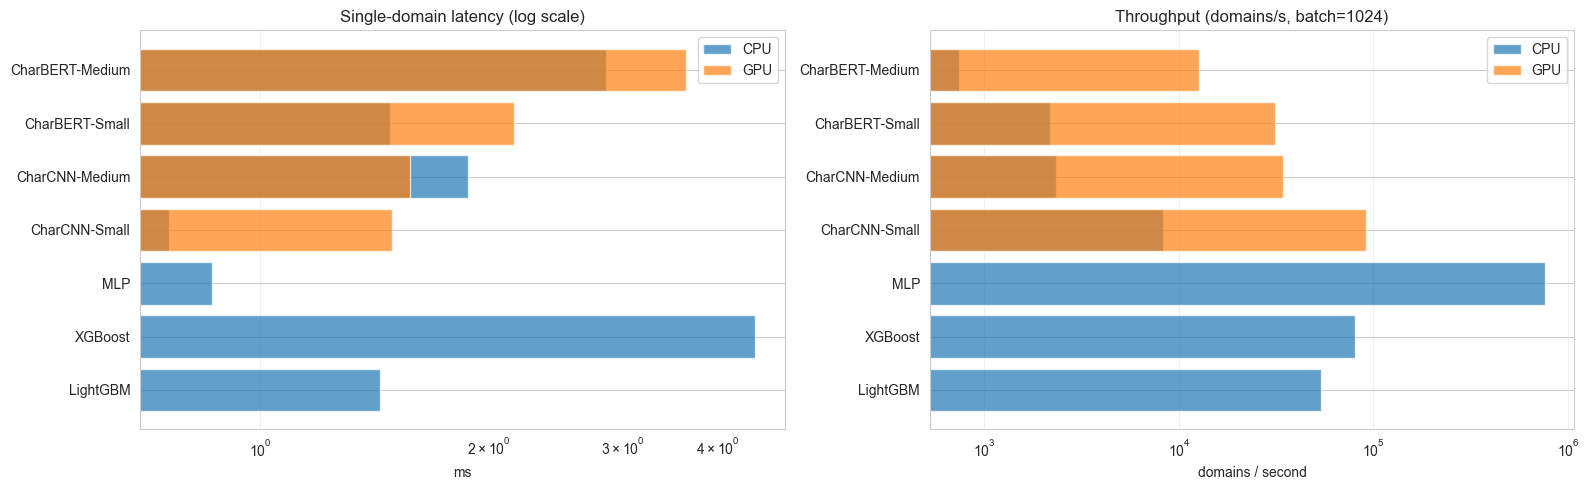

In [55]:
_fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Single latency
ax = axes[0]
lat_df = latency_df.reset_index()
for dev in ["cpu", "gpu"]:
    sub = lat_df[lat_df["device"] == dev]
    if len(sub):
        ax.barh(sub["model"], sub["single_ms"], alpha=0.7, label=dev.upper())
ax.set_xscale("log")
ax.set_title("Single-domain latency (log scale)")
ax.set_xlabel("ms")
ax.legend()
ax.grid(axis="x", alpha=0.3)

# Throughput (batch)
ax = axes[1]
for dev in ["cpu", "gpu"]:
    sub = lat_df[lat_df["device"] == dev]
    if len(sub):
        ax.barh(sub["model"], sub["throughput_domains_s"], alpha=0.7, label=dev.upper())
ax.set_xscale("log")
ax.set_title("Throughput (domains/s, batch=1024)")
ax.set_xlabel("domains / second")
ax.legend()
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(f"{PATHS['plots_dir']}/latency_comparison.png", dpi=140)
plt.show()

### Step 8 — Interpretation (Occlusion + Attention)

In [56]:
rng = np.random.RandomState(SEED)
N_PER_CLASS = 20

dga_idx_local = np.where(y_test_ood == 1)[0]
legit_idx_local = np.where(y_test_ood == 0)[0]

sample_dga = rng.choice(dga_idx_local, N_PER_CLASS, replace=False)
sample_legit = rng.choice(legit_idx_local, N_PER_CLASS, replace=False)

sample_idx = np.concatenate([sample_dga, sample_legit])
sample_domains = X_domain[test_ood_idx[sample_idx]]

np.savez(
    PATHS["models_dir"] / "interpretability_samples.npz",
    sample_idx=sample_idx,
    sample_domains=sample_domains.astype(str),
    n_per_class=np.array([N_PER_CLASS]),
)

print(
    f"Samples: {N_PER_CLASS} DGA + {N_PER_CLASS} legit, saved to interpretability_samples.npz"
)
print("- DGA examples:", sample_domains[:3])
print("- Legit examples:", sample_domains[N_PER_CLASS : N_PER_CLASS + 3])

Samples: 20 DGA + 20 legit, saved to interpretability_samples.npz
- DGA examples: ['uwwhuokkmndd.ru' 'wfyoielioami.org' 'bxiyhftzth.com']
- Legit examples: ['essexsteamtrain.com' 'az888a.casa' 'free-cams.ca']


In [57]:
def occlusion_sensitivity(model, X_enc_sample, pad_token=0, batch_size=256):
    """
    Для каждого примера и каждой позиции:
    заменяет токен на pad_token, измеряет Δprob.
    Возвращает (n_samples, max_len) абсолютных важностей.
    """
    model.eval()
    n_samples, L = X_enc_sample.shape
    # Формируем батч всех вариантов: (n_samples × L, L)
    variants = []
    for s in range(n_samples):
        for pos in range(L):
            v = X_enc_sample[s].clone()
            v[pos] = pad_token
            variants.append(v)
    X_all = torch.stack(variants)  # (n*L, L)

    probs = []
    with torch.no_grad():
        for i in range(0, len(X_all), batch_size):
            x_b = X_all[i : i + batch_size].to(DEVICE)
            p = torch.sigmoid(model(x_b)).cpu().numpy()
            probs.append(p)
    probs = np.concatenate(probs).reshape(n_samples, L)  # (n_samples, L)

    # Baseline (без occlusion)
    with torch.no_grad():
        x_b = X_enc_sample.to(DEVICE)
        baseline = torch.sigmoid(model(x_b)).cpu().numpy()  # (n_samples,)

    # Δprob = baseline - occluded (positive = позиция важна для исходного предсказания)
    importance = baseline[:, None] - probs
    return importance, baseline

In [58]:
X_sample_enc = X_test_ood_enc[sample_idx]  # (40, 75)

occlusion_results = {}
for name, value in deep_models.items():
    model = value.to(DEVICE)
    imp, base_prob = occlusion_sensitivity(model, X_sample_enc)
    occlusion_results[name] = {
        "importance": imp,
        "baseline": base_prob,
    }
    model = release_gpu(model, name)
    print(f"{name}: shape={imp.shape}, mean |imp|={np.abs(imp).mean():.4f}")

CharCNN-Small       : cuda:0 → cpu
VRAM: 5.32 GB free
CharCNN-Small: shape=(40, 75), mean |imp|=0.0178
CharCNN-Medium      : cuda:0 → cpu
VRAM: 5.32 GB free
CharCNN-Medium: shape=(40, 75), mean |imp|=0.0154
CharBERT-Small      : cuda:0 → cpu
VRAM: 5.32 GB free
CharBERT-Small: shape=(40, 75), mean |imp|=0.0061
CharBERT-Medium     : cuda:0 → cpu
VRAM: 5.32 GB free
CharBERT-Medium: shape=(40, 75), mean |imp|=0.0081


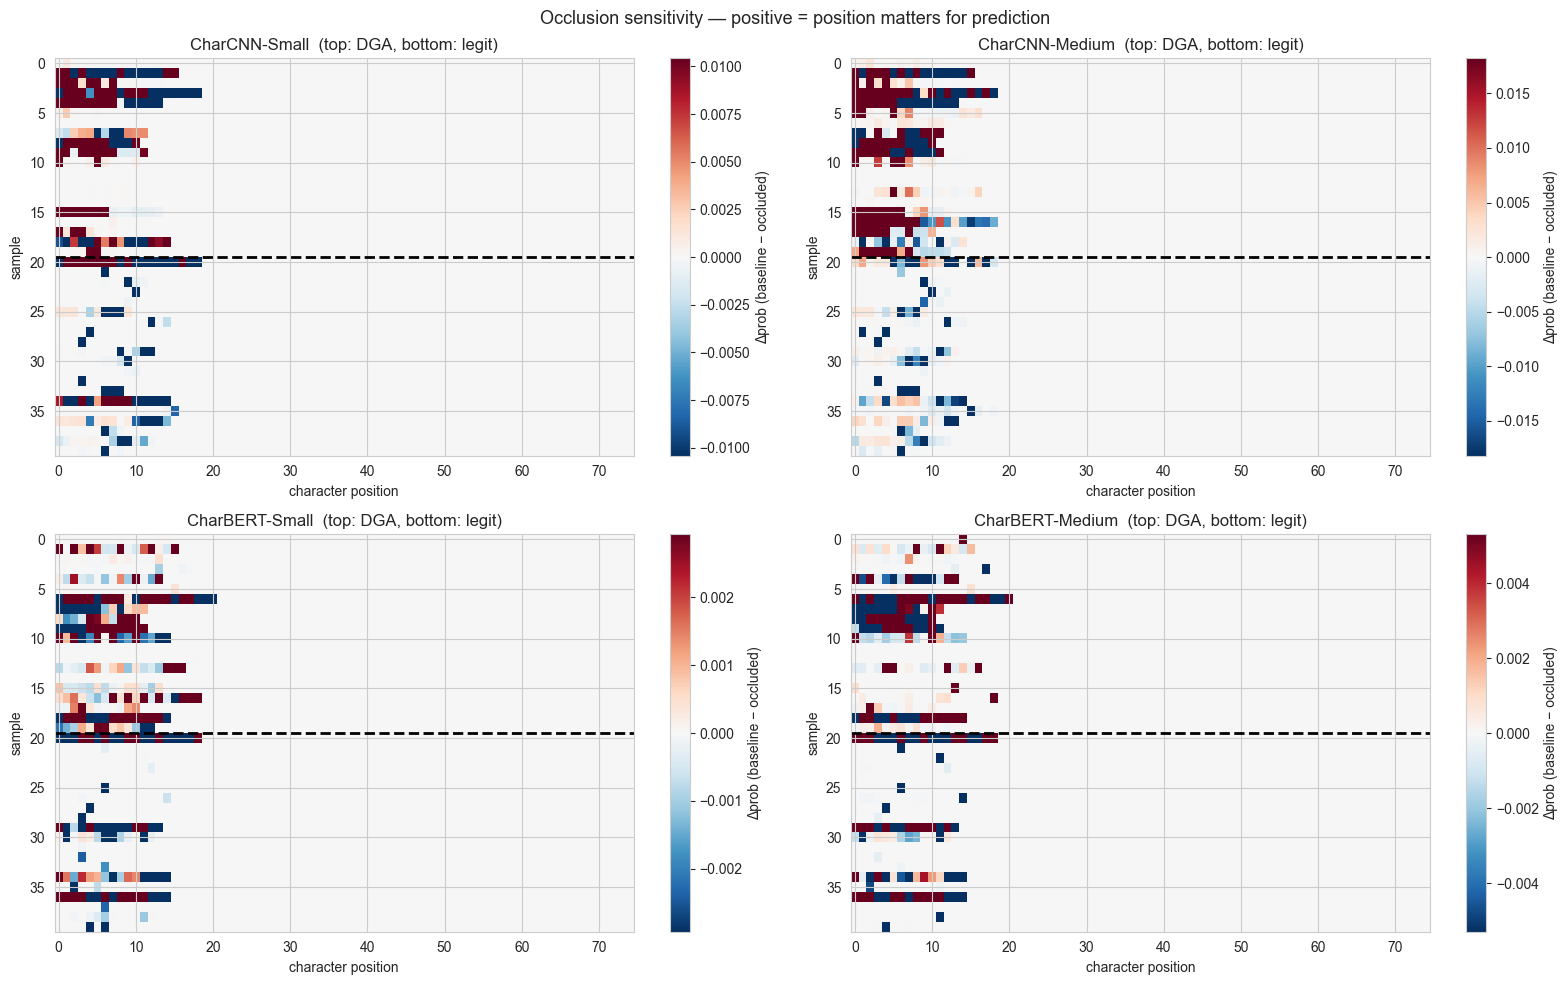

In [59]:
_fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes_flat = axes.flatten()

for ax, name in zip(axes_flat, deep_models):
    imp = occlusion_results[name]["importance"]  # (40, 75)
    # Разделяем DGA (0..19) и legit (20..39)
    vmax = np.percentile(np.abs(imp), 95)

    im = ax.imshow(imp, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.axhline(N_PER_CLASS - 0.5, color="black", lw=2, ls="--")
    ax.set_title(f"{name}  (top: DGA, bottom: legit)")
    ax.set_xlabel("character position")
    ax.set_ylabel("sample")
    plt.colorbar(im, ax=ax, label="Δprob (baseline − occluded)")

plt.suptitle(
    "Occlusion sensitivity — positive = position matters for prediction", fontsize=13
)
plt.tight_layout()
plt.savefig(f"{PATHS['plots_dir']}/occlusion_heatmap_all.png", dpi=140)
plt.show()

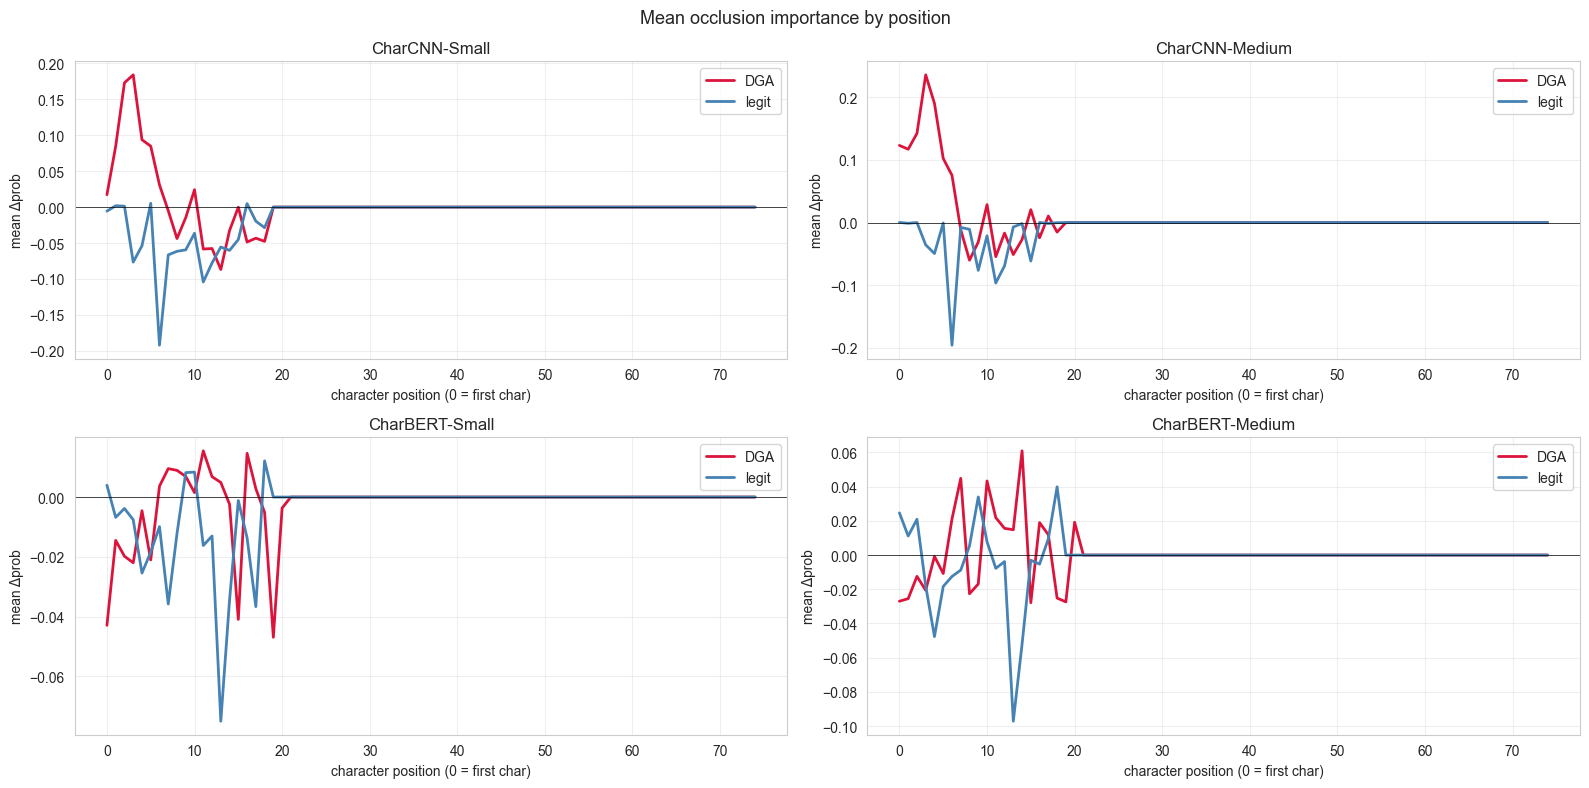

In [60]:
_fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for ax, name in zip(axes.flatten(), deep_models):
    imp = occlusion_results[name]["importance"]
    imp_dga = imp[:N_PER_CLASS].mean(axis=0)
    imp_legit = imp[N_PER_CLASS:].mean(axis=0)
    positions = np.arange(len(imp_dga))

    ax.plot(positions, imp_dga, label="DGA", color="crimson", lw=2)
    ax.plot(positions, imp_legit, label="legit", color="steelblue", lw=2)
    ax.axhline(0, color="black", lw=0.5)
    ax.set_title(name)
    ax.set_xlabel("character position (0 = first char)")
    ax.set_ylabel("mean Δprob")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Mean occlusion importance by position", fontsize=13)
plt.tight_layout()
plt.savefig(f"{PATHS['plots_dir']}/occlusion_by_position.png", dpi=140)
plt.show()

In [61]:
def get_attention_weights(model, x_batch):
    """
    Вручную вычисляет attention веса для всех слоёв энкодера.
    Возвращает (n_layers, B, L+1, L+1) или None.
    """
    model.eval()
    B, L = x_batch.shape
    attn_weights = []

    # 1. Получаем эмбеддинги + CLS + pos (как в forward)
    with torch.no_grad():
        x = model.embedding(x_batch)
        cls = model.cls_token.expand(B, -1, -1)
        x = torch.cat([cls, x], dim=1)
        x = x + model.pos_embedding[:, : L + 1, :]

        mask_pad = x_batch == 0
        cls_mask = torch.zeros(B, 1, dtype=torch.bool, device=x_batch.device)
        src_key_padding_mask = torch.cat([cls_mask, mask_pad], dim=1)

    # 2. Проходим по слоям, но для каждого self_attn вызываем с need_weights=True
    for layer in model.encoder.layers:
        # Стандартный forward слоя, но с переопределённым self_attn
        # Проще: вручную вызвать self_attn, затем FFN
        with torch.no_grad():
            # self-attention
            attn_out, attn_w = layer.self_attn(
                x,
                x,
                x,
                key_padding_mask=src_key_padding_mask,
                need_weights=True,
                average_attn_weights=False,  # (B, nheads, L, L)
            )
            # сохраняем усреднённые по головам
            attn_weights.append(attn_w.mean(dim=1).cpu())  # (B, L, L)

            # residual + norm
            x = layer.norm1(x + layer.dropout1(attn_out))

            # FFN
            ffn_out = layer.linear2(layer.dropout(layer.activation(layer.linear1(x))))
            x = layer.norm2(x + layer.dropout2(ffn_out))

    return torch.stack(attn_weights)  # (n_layers, B, L, L)

In [62]:
bert_names = ["CharBERT-Small", "CharBERT-Medium"]
attention_results = {}

for name in bert_names:
    model = deep_models[name].to(DEVICE)
    x_b = X_sample_enc.to(DEVICE)
    attn = get_attention_weights(model, x_b)
    if attn is not None:
        attention_results[name] = attn.numpy()  # (n_layers, B, L+1, L+1)
        print(f"{name}: attn shape={attn.shape}")
    else:
        print(f"{name}: attention weights not available (need_weights=False)")
    model = release_gpu(model, name)

CharBERT-Small: attn shape=torch.Size([4, 40, 76, 76])
CharBERT-Small      : cuda:0 → cpu
VRAM: 5.31 GB free
CharBERT-Medium: attn shape=torch.Size([6, 40, 76, 76])
CharBERT-Medium     : cuda:0 → cpu
VRAM: 5.31 GB free


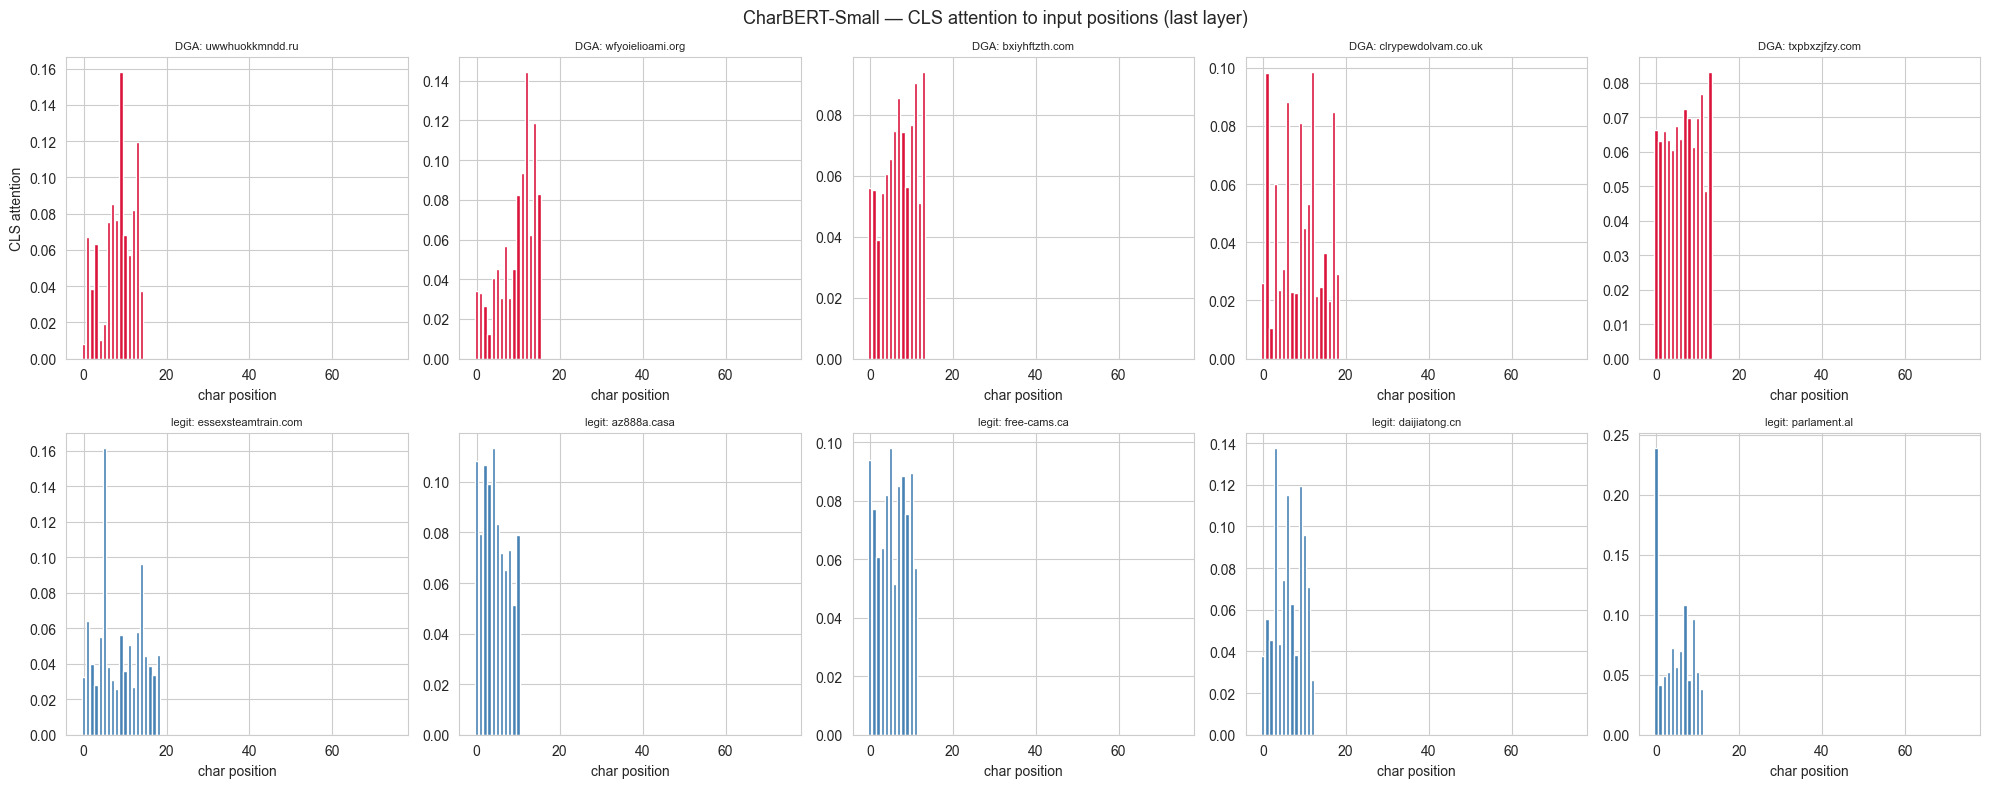

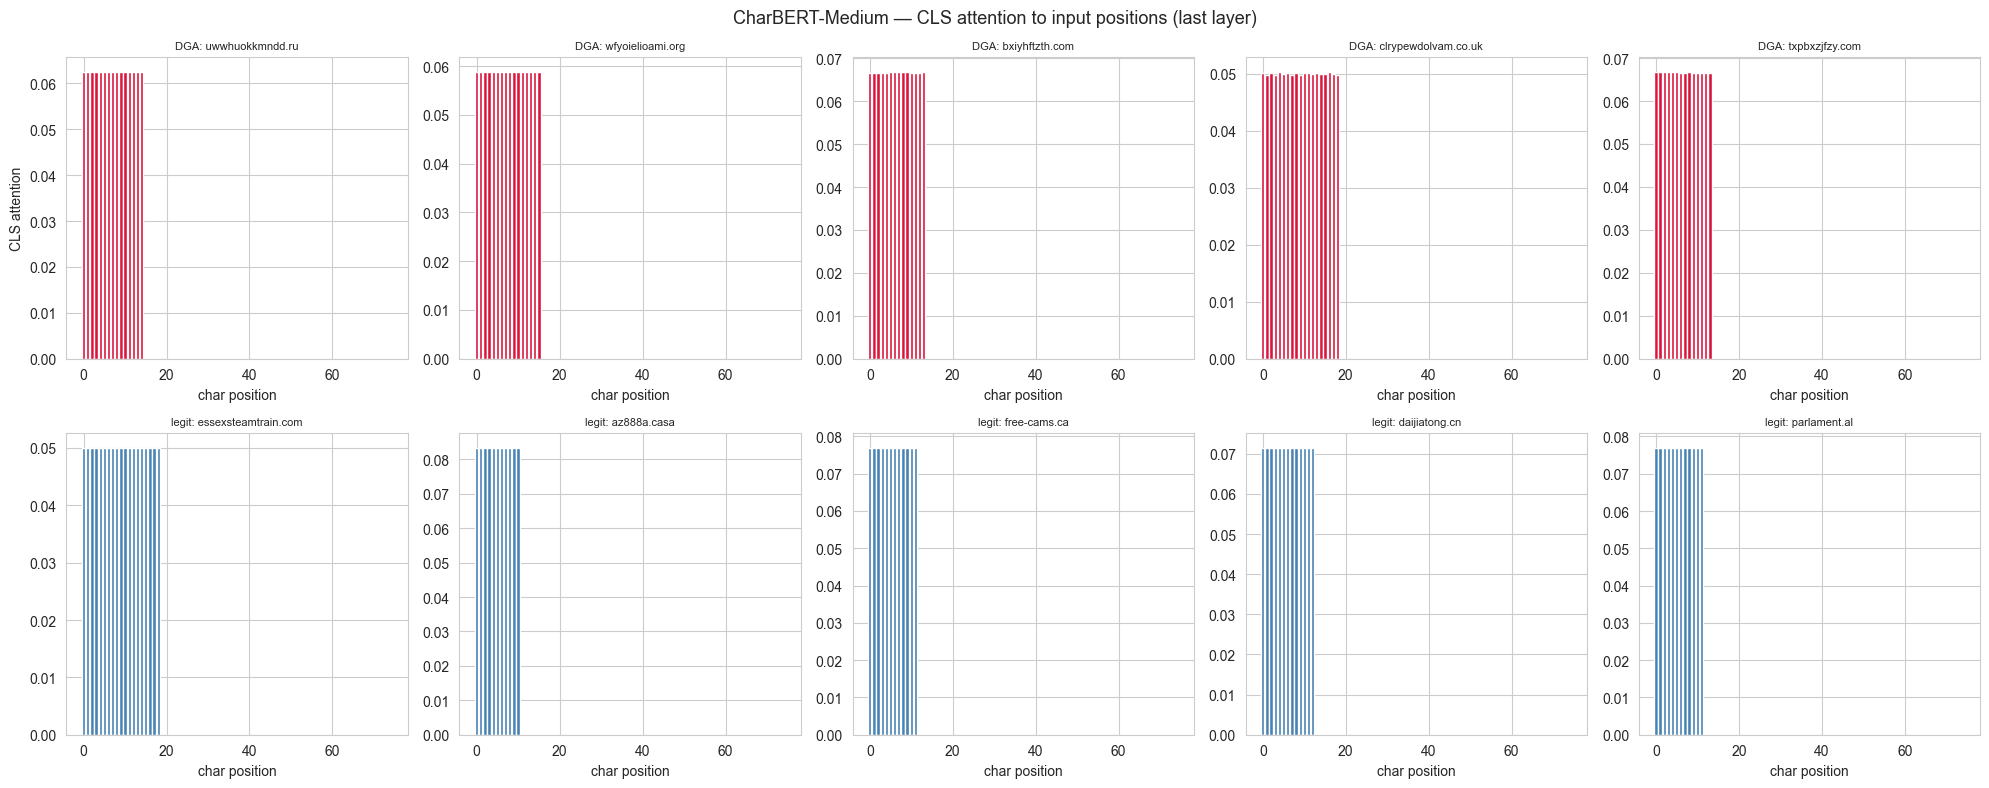

In [63]:
for name, attn in attention_results.items():
    last_layer = attn[-1]  # (B, L+1, L+1)

    _fig, axes = plt.subplots(2, 5, figsize=(20, 8))
    # 5 DGA + 5 legit для компактности
    picks = list(range(5)) + list(range(N_PER_CLASS, N_PER_CLASS + 5))

    for ax, idx in zip(axes.flatten(), picks):
        # CLS-токен в позиции 0, дальше — символы
        # Берём attention от CLS к токенам (строка 0, столбцы 1..L+1)
        cls_attn = last_layer[idx, 0, 1:]  # (L,)
        label = "DGA" if idx < N_PER_CLASS else "legit"
        domain = sample_domains[idx][:MAX_LEN]

        ax.bar(
            range(len(cls_attn)),
            cls_attn,
            color="crimson" if label == "DGA" else "steelblue",
        )
        ax.set_title(f"{label}: {domain}", fontsize=8)
        ax.set_xlabel("char position")
        if ax is axes.flatten()[0]:
            ax.set_ylabel("CLS attention")

    plt.suptitle(f"{name} — CLS attention to input positions (last layer)", fontsize=13)
    plt.tight_layout()
    plt.savefig(f"{PATHS['plots_dir']}/attention_{name.replace('-', '_')}.png", dpi=140)
    plt.show()

In [64]:
def run_cv_deep(
    model_name,
    model_class,
    arch_config,
    lr,
    weight_decay,
    cv_dataset,
    folds_full,
    pos_map,
    y_cv_np,
    X_cv_enc,
    batch_size=512,
    save_dir=None,
    resume=True,
):
    """
    5-fold family-aware CV for a deep model. Returns DataFrame with per-fold metrics.

    resume=True: if fold{k}.json exists, load metrics from it and skip training.
    """
    if save_dir is None:
        save_dir = PATHS["models_dir"] / "cv_deep" / model_name
    save_dir.mkdir(parents=True, exist_ok=True)

    results = []
    for k, (tr_full, va_full) in enumerate(folds_full):
        fold_json = save_dir / f"fold{k}.json"
        fold_pt = save_dir / f"fold{k}.pt"

        if resume and fold_json.exists() and fold_pt.exists():
            with open(fold_json, encoding="utf-8") as f:
                row = json.load(f)
            results.append(row)
            print(
                f"  [{model_name} fold {k}] cached  AP={row['val_ap']:.4f} "
                f"| TPR@FPR=1e-3={row['val_tpr@fpr=1e-3']:.4f}"
            )
            continue

        print(
            f"\n{'=' * 60}\n{model_name} — Fold {k + 1}/{len(folds_full)}\n{'=' * 60}"
        )
        tr_pos, va_pos = pos_map[tr_full], pos_map[va_full]
        train_ds_cv = Subset(cv_dataset, tr_pos)
        val_ds_cv = Subset(cv_dataset, va_pos)

        model = model_class(**arch_config)
        t0 = time.perf_counter()
        model, _, hist = train_deep_model(
            f"{model_name}_fold{k}",
            model,
            train_ds_cv,
            val_ds_cv,
            y_val_np=y_cv_np[va_pos],
            batch_size=batch_size,
            lr=lr,
            weight_decay=weight_decay,
            pos_weight=POS_WEIGHT,
            epochs=MAX_EPOCHS_DEEP,
            patience=PATIENCE_DEEP,
        )
        train_s = time.perf_counter() - t0

        p_val_fold = predict_deep(model, X_cv_enc[va_pos], batch_size=batch_size)
        y_val_fold = y_cv_np[va_pos]

        row = {
            "fold": k,
            "val_ap": float(average_precision_score(y_val_fold, p_val_fold)),
            "val_roc_auc": float(roc_auc_score(y_val_fold, p_val_fold)),
            "val_tpr@fpr=1e-3": tpr_at_fpr(y_val_fold, p_val_fold, 1e-3),
            "train_s": train_s,
            "epochs_run": hist["epoch"][-1],
        }
        results.append(row)
        print(
            f"Fold {k}: AP={row['val_ap']:.4f} | AUC={row['val_roc_auc']:.4f} | "
            f"TPR@FPR=1e-3={row['val_tpr@fpr=1e-3']:.4f} | {train_s / 60:.1f} min"
        )

        torch.save(model.state_dict(), fold_pt)
        with open(fold_json, "w", encoding="utf-8") as f:
            json.dump(row, f, indent=2)

        model = release_gpu(model, f"{model_name}_fold{k}")

    cv_df = pd.DataFrame(results).set_index("fold")
    cv_df.to_csv(save_dir / "summary.csv")
    print(f"\n{'=' * 60}\n{model_name} CV Summary\n{'=' * 60}")
    for col in ["val_ap", "val_roc_auc", "val_tpr@fpr=1e-3"]:
        print(f"  {col:20s} = {cv_df[col].mean():.4f} ± {cv_df[col].std():.4f}")
    print(f"  total train time     = {cv_df['train_s'].sum() / 60:.1f} min")
    return cv_df

In [65]:
def plot_cv_results(cv_df, model_name, save_dir=None):
    if save_dir is None:
        save_dir = PATHS["plots_dir"]
    _fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, metric, title in zip(
        axes,
        ["val_ap", "val_roc_auc", "val_tpr@fpr=1e-3"],
        ["Val AP", "Val ROC-AUC", "Val TPR @ FPR=1e-3"],
    ):
        ax.bar(cv_df.index, cv_df[metric], color="steelblue")
        ax.axhline(
            cv_df[metric].mean(),
            color="red",
            ls="--",
            label=f"mean={cv_df[metric].mean():.4f} ± {cv_df[metric].std():.4f}",
        )
        ax.set_title(title)
        ax.set_xlabel("fold")
        ax.set_ylabel(metric)
        ax.legend(fontsize=8)
        ax.grid(axis="y", alpha=0.3)
    plt.suptitle(
        f"{model_name} — CV across {len(cv_df)} folds (family-aware)", fontsize=13
    )
    plt.tight_layout()
    plt.savefig(save_dir / f"cv_{model_name.replace('-', '_')}.png", dpi=140)
    plt.show()

In [66]:
def run_cv_deep_cached(
    model_name,
    model_class,
    arch_config,
    lr,
    weight_decay,
    cv_dataset,
    folds_full,
    pos_map,
    y_cv_np,
    X_cv_enc,
    batch_size=512,
):
    """Wrapper: if summary.csv exists - load; else run_cv_deep with fold-level resume."""
    summary_path = PATHS["models_dir"] / "cv_deep" / model_name / "summary.csv"

    if CV_USE_SUMMARY_CACHE and summary_path.exists():
        cv_df = pd.read_csv(summary_path, index_col="fold")
        print(
            f"Loaded {model_name} CV from {summary_path.name} "
            f"({len(cv_df)} folds, {cv_df['train_s'].sum() / 60:.1f} min cached)"
        )
        return cv_df

    return run_cv_deep(
        model_name,
        model_class,
        arch_config,
        lr,
        weight_decay,
        cv_dataset=cv_dataset,
        folds_full=folds_full,
        pos_map=pos_map,
        y_cv_np=y_cv_np,
        X_cv_enc=X_cv_enc,
        batch_size=batch_size,
        resume=CV_FOLD_RESUME,
    )

### Section 9 — Cross-Validation

In [67]:
X_cv_enc = torch.cat([X_train_enc, X_val_enc, X_test_id_enc], dim=0)  # (N, 75)
y_cv_np = y_all[cv_idx]
y_cv_t = torch.from_numpy(y_cv_np).float()

pos_map = np.full(len(full_df), -1, dtype=np.int64)
pos_map[cv_idx] = np.arange(len(cv_idx))

cv_dataset = PreEncodedDataset(X_cv_enc, y_cv_t)
print(f"CV dataset: {len(cv_dataset)} samples | {N_CV_SPLITS} folds")

CV dataset: 1830364 samples | 5 folds


Loaded CharCNN-Small CV from summary.csv (5 folds, 46.5 min cached)


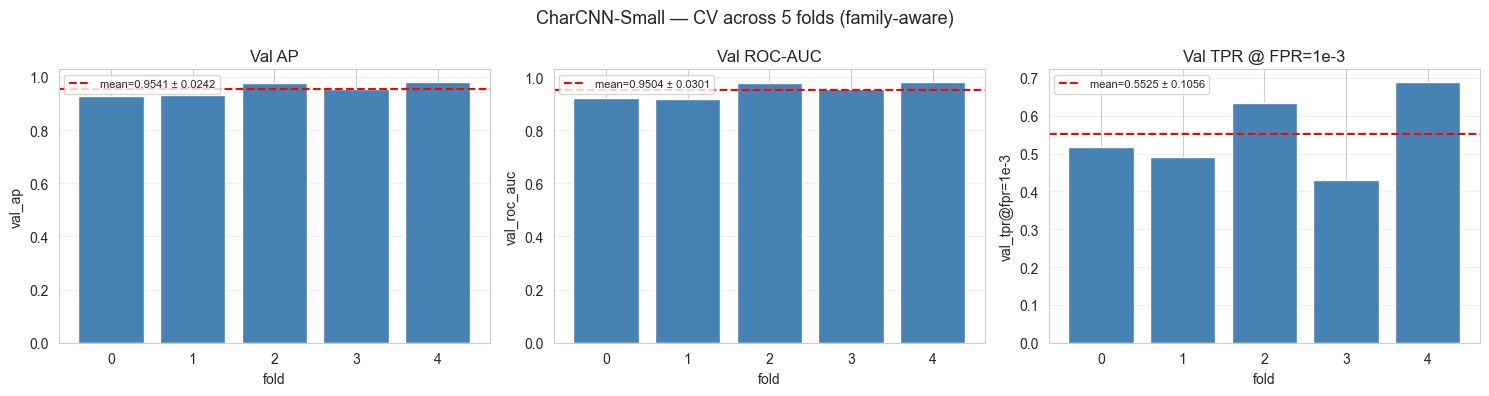

In [68]:
cv_df_schar = run_cv_deep_cached(
    "CharCNN-Small",
    CharCNN,
    CHARCNN_CONFIGS["CharCNN-Small"],
    lr=1e-3,
    weight_decay=1e-4,
    cv_dataset=cv_dataset,
    folds_full=folds_full,
    pos_map=pos_map,
    y_cv_np=y_cv_np,
    X_cv_enc=X_cv_enc,
)
plot_cv_results(cv_df_schar, "CharCNN-Small")

Loaded CharCNN-Medium CV from summary.csv (5 folds, 97.0 min cached)


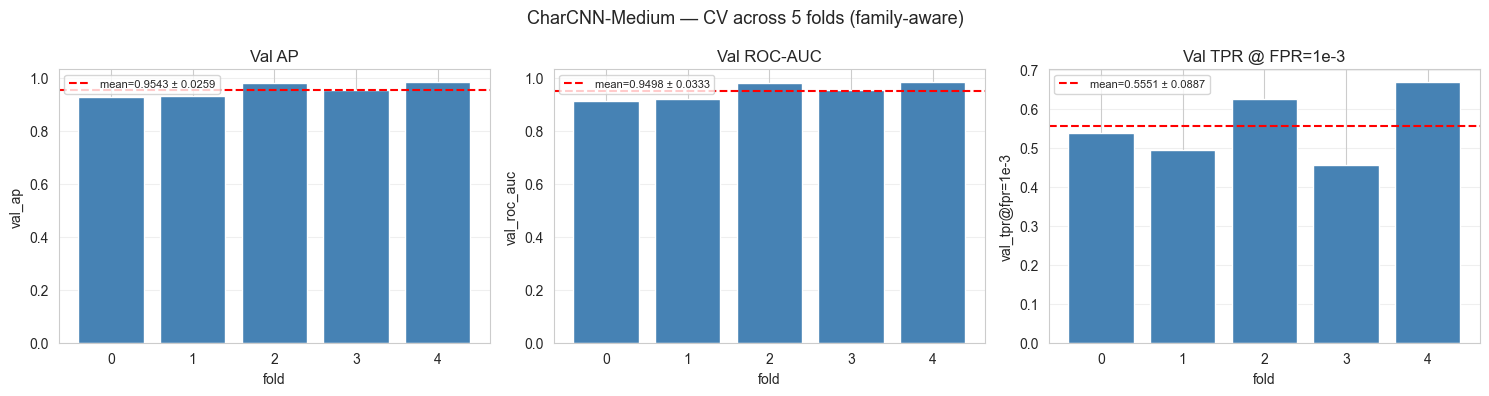

In [69]:
cv_df_mchar = run_cv_deep_cached(
    "CharCNN-Medium",
    CharCNN,
    CHARCNN_CONFIGS["CharCNN-Medium"],
    lr=1e-3,
    weight_decay=1e-4,
    cv_dataset=cv_dataset,
    folds_full=folds_full,
    pos_map=pos_map,
    y_cv_np=y_cv_np,
    X_cv_enc=X_cv_enc,
)
plot_cv_results(cv_df_mchar, "CharCNN-Medium")

Loaded CharBERT-Small CV from summary.csv (5 folds, 252.9 min cached)


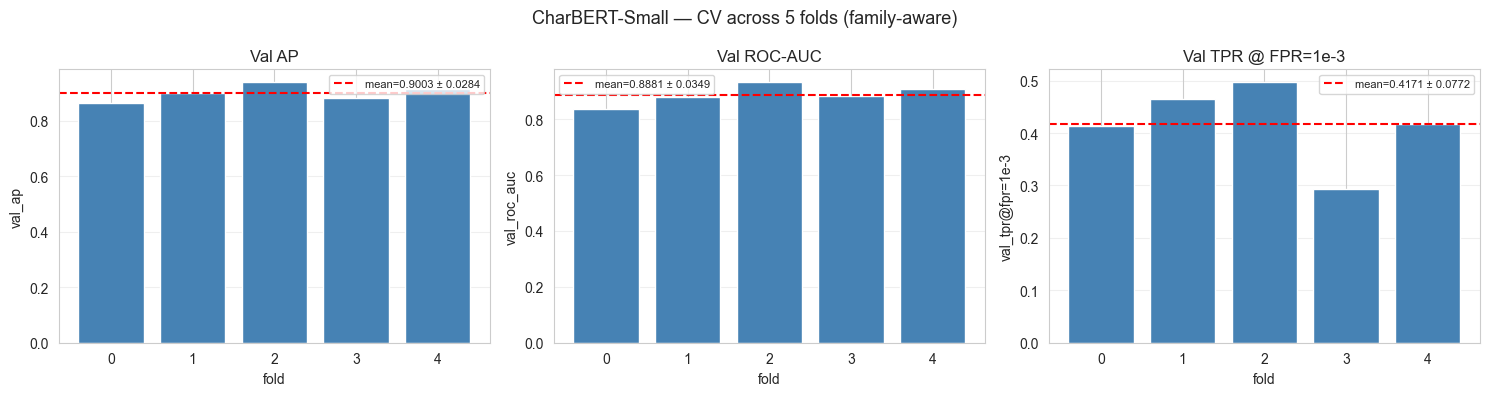

In [70]:
cv_df_sbert = run_cv_deep_cached(
    "CharBERT-Small",
    CharBERT,
    CHARBERT_CONFIGS["CharBERT-Small"],
    lr=1e-3,
    weight_decay=0.01,
    cv_dataset=cv_dataset,
    folds_full=folds_full,
    pos_map=pos_map,
    y_cv_np=y_cv_np,
    X_cv_enc=X_cv_enc,
)
plot_cv_results(cv_df_sbert, "CharBERT-Small")

Loaded CharBERT-Medium CV from summary.csv (5 folds, 450.2 min cached)


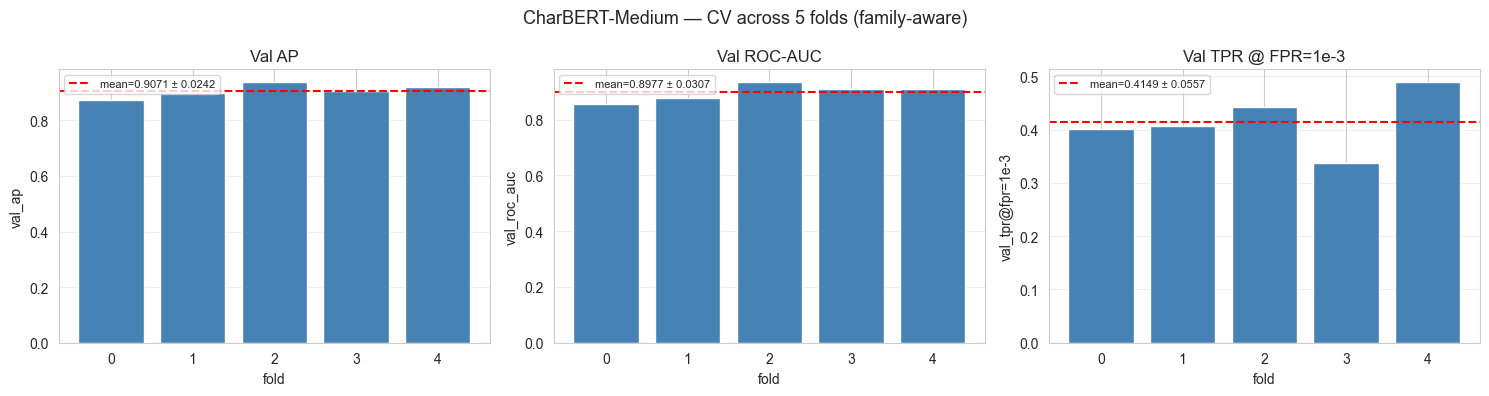

In [71]:
cv_df_mbert = run_cv_deep_cached(
    "CharBERT-Medium",
    CharBERT,
    CHARBERT_CONFIGS["CharBERT-Medium"],
    lr=1e-3,
    weight_decay=0.01,
    cv_dataset=cv_dataset,
    folds_full=folds_full,
    pos_map=pos_map,
    y_cv_np=y_cv_np,
    X_cv_enc=X_cv_enc,
)
plot_cv_results(cv_df_mbert, "CharBERT-Medium")

In [72]:
cv_summary = pd.DataFrame(
    {
        "CharCNN-Small": [
            cv_df_schar["val_ap"].mean(),
            cv_df_schar["val_ap"].std(),
            cv_df_schar["val_tpr@fpr=1e-3"].mean(),
            cv_df_schar["val_tpr@fpr=1e-3"].std(),
        ],
        "CharCNN-Medium": [
            cv_df_mchar["val_ap"].mean(),
            cv_df_mchar["val_ap"].std(),
            cv_df_mchar["val_tpr@fpr=1e-3"].mean(),
            cv_df_mchar["val_tpr@fpr=1e-3"].std(),
        ],
        "CharBERT-Small": [
            cv_df_sbert["val_ap"].mean(),
            cv_df_sbert["val_ap"].std(),
            cv_df_sbert["val_tpr@fpr=1e-3"].mean(),
            cv_df_sbert["val_tpr@fpr=1e-3"].std(),
        ],
        "CharBERT-Medium": [
            cv_df_mbert["val_ap"].mean(),
            cv_df_mbert["val_ap"].std(),
            cv_df_mbert["val_tpr@fpr=1e-3"].mean(),
            cv_df_mbert["val_tpr@fpr=1e-3"].std(),
        ],
    },
    index=["AP mean", "AP std", "TPR@1e-3 mean", "TPR@1e-3 std"],
)
cv_summary.to_csv(PATHS["models_dir"] / "cv_deep" / "summary_all.csv")
print("=== CV summary (all 4 deep models) ===")
print(cv_summary.round(4).to_string())

=== CV summary (all 4 deep models) ===
               CharCNN-Small  CharCNN-Medium  CharBERT-Small  CharBERT-Medium
AP mean               0.9541          0.9543          0.9003           0.9071
AP std                0.0242          0.0259          0.0284           0.0242
TPR@1e-3 mean         0.5525          0.5551          0.4171           0.4149
TPR@1e-3 std          0.1056          0.0887          0.0772           0.0557


### Section 10 — DomURLs_BERT

In [ ]:
DOMURLS_MODEL = "amahdaouy/DomURLs_BERT"
DOMURLS_MAX_LEN = 75
DOMURLS_BATCH_SIZE = 16
DOMURLS_LR = 2e-5
DOMURLS_EPOCHS = 5
DOMURLS_PATIENCE = 2

DOMURLS_DIR = PATHS["models_dir"] / "DomURLs_BERT"
DOMURLS_DIR.mkdir(parents=True, exist_ok=True)

BERT_COLORS = {
    "CharBERT-Small": "steelblue",
    "CharBERT-Medium": "seagreen",
    "DomURLs_BERT": "darkorange",
}

In [ ]:
try:
    tokenizer_domurls = AutoTokenizer.from_pretrained(DOMURLS_DIR)
    print(f"Tokenizer loaded from disk: {DOMURLS_DIR}")
except Exception:
    tokenizer_domurls = AutoTokenizer.from_pretrained(DOMURLS_MODEL)
    print(f"Tokenizer loaded: {DOMURLS_MODEL}")

Tokenizer loaded: amahdaouy/DomURLs_BERT


In [75]:
def tokenize_domains(domains, tokenizer, max_len=DOMURLS_MAX_LEN):
    enc = tokenizer(
        list(domains),
        truncation=True,
        padding="max_length",
        max_length=max_len,
        return_tensors="pt",
    )
    return enc["input_ids"], enc["attention_mask"]

In [76]:
X_train_ids, X_train_mask = tokenize_domains(X_domain[train_idx], tokenizer_domurls)
X_val_ids, X_val_mask = tokenize_domains(X_domain[val_idx], tokenizer_domurls)
X_id_ids, X_id_mask = tokenize_domains(X_domain[test_id_idx], tokenizer_domurls)
X_ood_ids, X_ood_mask = tokenize_domains(X_domain[test_ood_idx], tokenizer_domurls)
print(f"Tokens: train={tuple(X_train_ids.shape)} | val={tuple(X_val_ids.shape)}")

Tokens: train=(1281254, 75) | val=(274555, 75)


In [77]:
class DomURLsDataset(Dataset):
    def __init__(self, input_ids, attention_mask, labels):
        self.input_ids, self.attention_mask, self.labels = (
            input_ids,
            attention_mask,
            labels,
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.input_ids[idx],
            "attention_mask": self.attention_mask[idx],
            "labels": self.labels[idx],
        }


def train_domurls(
    model,
    train_ds,
    val_ds,
    y_val_np,
    epochs=DOMURLS_EPOCHS,
    patience=DOMURLS_PATIENCE,
    batch_size=DOMURLS_BATCH_SIZE,
    lr=DOMURLS_LR,
):
    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
    )
    val_loader = DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
    )
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    criterion = nn.BCEWithLogitsLoss()
    best_ap, best_state, patience_counter = 0.0, None, 0
    history = {"epoch": [], "train_loss": [], "val_ap": []}

    for epoch in range(epochs):
        model.train()
        loss_sum, n_batches = 0.0, 0
        for batch in train_loader:
            input_ids = batch["input_ids"].to(DEVICE, non_blocking=True)
            attention_mask = batch["attention_mask"].to(DEVICE, non_blocking=True)
            labels = batch["labels"].to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(
                input_ids=input_ids, attention_mask=attention_mask
            ).logits.squeeze(-1)
            loss = criterion(logits, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()
            loss_sum += loss.item()
            n_batches += 1
        model.eval()
        val_logits = []
        with torch.no_grad():
            for batch in val_loader:
                logits = model(
                    input_ids=batch["input_ids"].to(DEVICE, non_blocking=True),
                    attention_mask=batch["attention_mask"].to(
                        DEVICE, non_blocking=True
                    ),
                ).logits.squeeze(-1)
                val_logits.append(logits.float().cpu())
        val_probs = torch.sigmoid(torch.cat(val_logits)).numpy()
        val_ap = average_precision_score(y_val_np, val_probs)
        train_loss = loss_sum / n_batches
        history["epoch"].append(epoch + 1)
        history["train_loss"].append(train_loss)
        history["val_ap"].append(val_ap)
        print(f"  epoch {epoch + 1:2d} | train {train_loss:.4f} | val_ap {val_ap:.4f}")
        if val_ap > best_ap + 1e-4:
            best_ap = val_ap
            best_state = {
                k: v.detach().cpu().clone() for k, v in model.state_dict().items()
            }
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"  ⏹ early stop at epoch {epoch + 1}")
                break
    model.load_state_dict(best_state)
    return model, best_ap, history


def predict_domurls(model, input_ids, attention_mask, batch_size=64):
    model.eval()
    model_device = next(model.parameters()).device
    probs = []
    with torch.no_grad():
        for i in range(0, len(input_ids), batch_size):
            ids = input_ids[i : i + batch_size].to(model_device, non_blocking=True)
            mask = attention_mask[i : i + batch_size].to(
                model_device, non_blocking=True
            )
            logits = model(input_ids=ids, attention_mask=mask).logits.squeeze(-1)
            probs.append(torch.sigmoid(logits).cpu().numpy())
    return np.concatenate(probs)

In [ ]:
def _domurls_checkpoint_exists():
    return (DOMURLS_DIR / "config.json").exists() and (
        (DOMURLS_DIR / "model.safetensors").exists()
        or (DOMURLS_DIR / "pytorch_model.bin").exists()
    )


def load_or_train_domurls():
    """Load from disk if checkpoint exists; else train from HF checkpoint and save immediately."""
    if _domurls_checkpoint_exists():
        print(f"Loading DomURLs_BERT from {DOMURLS_DIR}")
        model = AutoModelForSequenceClassification.from_pretrained(DOMURLS_DIR)
        model = model.to(DEVICE)
        tokenizer = AutoTokenizer.from_pretrained(DOMURLS_DIR)
        with open(DOMURLS_DIR / "meta.json", encoding="utf-8") as f:
            meta = json.load(f)
        print(
            f"  best_val_ap={meta['best_val_ap']:.4f} | "
            f"train_time={meta['train_time_s'] / 60:.1f} min"
        )
        return (
            model,
            tokenizer,
            meta["history"],
            meta["best_val_ap"],
            meta["train_time_s"],
        )

    print("Training DomURLs_BERT...")
    model = AutoModelForSequenceClassification.from_pretrained(
        DOMURLS_MODEL, num_labels=1
    )
    train_ds_dom = DomURLsDataset(
        X_train_ids, X_train_mask, torch.from_numpy(y_all[train_idx]).float()
    )
    val_ds_dom = DomURLsDataset(
        X_val_ids, X_val_mask, torch.from_numpy(y_all[val_idx]).float()
    )

    t0 = time.perf_counter()
    model, best_ap, hist = train_domurls(model, train_ds_dom, val_ds_dom, y_val)
    train_s = time.perf_counter() - t0
    print(
        f"\nDomURLs_BERT fine-tuned in {train_s / 60:.1f} min | best val_ap={best_ap:.4f}"
    )

    # save model to protect training result
    model.save_pretrained(DOMURLS_DIR)
    tokenizer_domurls.save_pretrained(DOMURLS_DIR)

    meta = {
        "base_model": DOMURLS_MODEL,
        "n_params": sum(p.numel() for p in model.parameters()),
        "best_val_ap": float(best_ap),
        "train_time_s": float(train_s),
        "history": hist,
        "training": {
            "max_epochs": DOMURLS_EPOCHS,
            "patience": DOMURLS_PATIENCE,
            "batch_size": DOMURLS_BATCH_SIZE,
            "lr": DOMURLS_LR,
            "max_len": DOMURLS_MAX_LEN,
            "criterion": "val_average_precision",
        },
        # thresholds filled later
        "thresholds": {"fpr_1e-3": None, "recall_0.95": None},
    }
    with open(DOMURLS_DIR / "meta.json", "w", encoding="utf-8") as f:
        json.dump(meta, f, ensure_ascii=False, indent=2, default=float)
    print(f"\nSaved checkpoint to {DOMURLS_DIR}")
    for f in sorted(DOMURLS_DIR.iterdir()):
        print(f"  {f.name:35s} {f.stat().st_size / 1e6:8.2f} MB")

    return model, tokenizer_domurls, hist, best_ap, train_s


domurls_model, tokenizer_domurls, domurls_hist, domurls_best_ap, domurls_train_s = (
    load_or_train_domurls()
)

Loading DomURLs_BERT from d:\Data\Scripts\models\DomURLs_BERT


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  best_val_ap=0.9973 | train_time=767.0 min


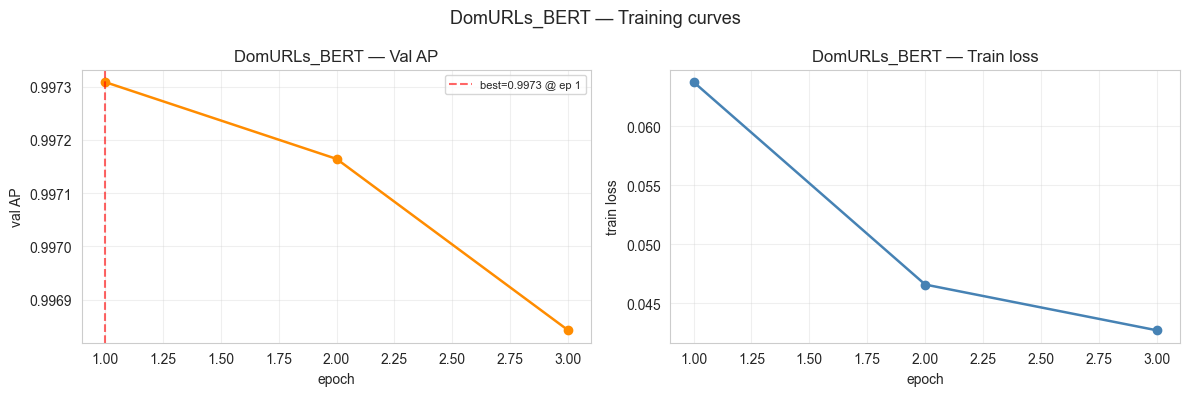

In [79]:
_fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Val AP
ax = axes[0]
ap = domurls_hist["val_ap"]
best_i = best_state_epoch(ap)
ax.plot(domurls_hist["epoch"], ap, marker="o", color="darkorange", linewidth=1.8)
ax.axvline(
    domurls_hist["epoch"][best_i],
    color="red",
    ls="--",
    alpha=0.6,
    label=f"best={ap[best_i]:.4f} @ ep {domurls_hist['epoch'][best_i]}",
)
ax.set_title("DomURLs_BERT — Val AP")
ax.set_xlabel("epoch")
ax.set_ylabel("val AP")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)

# Train loss
ax = axes[1]
ax.plot(
    domurls_hist["epoch"],
    domurls_hist["train_loss"],
    marker="o",
    color="steelblue",
    linewidth=1.8,
)
ax.set_title("DomURLs_BERT — Train loss")
ax.set_xlabel("epoch")
ax.set_ylabel("train loss")
ax.grid(alpha=0.3)

plt.suptitle("DomURLs_BERT — Training curves", fontsize=13)
plt.tight_layout()
plt.savefig(PATHS["plots_dir"] / "domurls_training_curves.png", dpi=140)
plt.show()

In [80]:
p_val_dom = predict_domurls(domurls_model, X_val_ids, X_val_mask, batch_size=256)
p_test_id_dom = predict_domurls(domurls_model, X_id_ids, X_id_mask, batch_size=256)
p_ood_dom = predict_domurls(domurls_model, X_ood_ids, X_ood_mask, batch_size=256)

thr_dom, _, _ = pick_threshold(y_val, p_val_dom, TARGET_FPR)
thr_rec_dom = pick_threshold_at_recall(y_val, p_val_dom, 0.95)

iso_dom = IsotonicRegression(out_of_bounds="clip")
iso_dom.fit(p_val_dom, y_val)
joblib.dump(iso_dom, PATHS["models_dir"] / "DomURLs_BERT_cal.pkl")
print(f"thresholds: FPR-thr={thr_dom:.4f} | recall-thr={thr_rec_dom:.4f}")

with open(DOMURLS_DIR / "meta.json", encoding="utf-8") as f:
    _meta = json.load(f)
_meta["thresholds"] = {"fpr_1e-3": float(thr_dom), "recall_0.95": float(thr_rec_dom)}
with open(DOMURLS_DIR / "meta.json", "w", encoding="utf-8") as f:
    json.dump(_meta, f, ensure_ascii=False, indent=2, default=float)
print("Saved thresholds to meta.json")

thresholds: FPR-thr=0.9981 | recall-thr=0.9588
Saved thresholds to meta.json


In [81]:
metrics_id_dom = full_metrics_block(y_test_id, p_test_id_dom, thr_dom)
print("=== DomURLs_BERT — test_id ===")
print(pd.Series(metrics_id_dom).round(5).to_string())

=== DomURLs_BERT — test_id ===
accuracy               0.90945
precision              0.99836
recall                 0.80174
f1                     0.88931
roc_auc                0.99769
pr_auc                 0.99705
tpr                    0.80174
fpr                    0.00109
fp_per_million      1093.39894
brier                  0.01302
tpr@fpr=1e-2           0.97507
tpr@fpr=1e-3           0.79737
tpr@fpr=1e-4           0.55689
prec@rec=0.95          0.99044
prec@rec=0.99          0.96862
prec@prev=0.001        0.42330
prec@prev=0.0001       0.06832


In [82]:
metrics_ood_dom = full_metrics_block(y_test_ood, p_ood_dom, thr_dom)
print("=== DomURLs_BERT — test_ood ===")
print(pd.Series(metrics_ood_dom).round(5).to_string())

=== DomURLs_BERT — test_ood ===
accuracy               0.85414
precision              0.99867
recall                 0.72607
f1                     0.84083
roc_auc                0.98782
pr_auc                 0.99097
tpr                    0.72607
fpr                    0.00109
fp_per_million      1093.39894
brier                  0.03751
tpr@fpr=1e-2           0.91408
tpr@fpr=1e-3           0.71762
tpr@fpr=1e-4           0.35713
prec@rec=0.95          0.97100
prec@rec=0.99          0.75177
prec@prev=0.001        0.39930
prec@prev=0.0001       0.06228


In [83]:
pd.Series(metrics_id_dom).to_csv(
    PATHS["models_dir"] / "reports" / "metrics_id_dom.csv", header=["value"]
)
pd.Series(metrics_ood_dom).to_csv(
    PATHS["models_dir"] / "reports" / "metrics_ood_dom.csv", header=["value"]
)
print("Saved metrics_id_dom.csv, metrics_ood_dom.csv")

recall_dom = pd.DataFrame(
    [
        {
            "split": "id",
            "threshold_recall": float(thr_rec_dom),
            **metrics_block(y_test_id, p_test_id_dom, thr_rec_dom),
        },
        {
            "split": "ood",
            "threshold_recall": float(thr_rec_dom),
            **metrics_block(y_test_ood, p_ood_dom, thr_rec_dom),
        },
    ]
).set_index("split")

recall_dom.to_csv(PATHS["models_dir"] / "reports" / "metrics_recall_dom.csv")
print(f"\n=== DomURLs_BERT @ recall-threshold ({thr_rec_dom:.4f}) ===")
print(recall_dom.round(4).to_string())

Saved metrics_id_dom.csv, metrics_ood_dom.csv

=== DomURLs_BERT @ recall-threshold (0.9588) ===
       threshold_recall  accuracy  precision  recall      f1  roc_auc  pr_auc     tpr     fpr  fp_per_million   brier
split                                                                                                                
id               0.9588    0.9736     0.9904  0.9511  0.9703   0.9977   0.997  0.9511  0.0076       7620.4572  0.0130
ood              0.9588    0.9447     0.9926  0.9026  0.9455   0.9878   0.991  0.9026  0.0076       7620.4572  0.0375


In [84]:
compare_models = ["CharBERT-Small", "CharBERT-Medium"]
compare_cols = [
    "pr_auc",
    "tpr@fpr=1e-3",
    "prec@prev=0.0001",
    "f1",
    "brier",
    "fp_per_million",
]

cmp_id = metrics_id_df.loc[compare_models, compare_cols].copy()
cmp_id.loc["DomURLs_BERT"] = {c: metrics_id_dom[c] for c in compare_cols}

cmp_ood = metrics_ood_df.loc[compare_models, compare_cols].copy()
cmp_ood.loc["DomURLs_BERT"] = {c: metrics_ood_dom[c] for c in compare_cols}

print("=== test_id: CharBERT vs DomURLs_BERT ===")
print(cmp_id.round(4).to_string())
print("\n=== test_ood: CharBERT vs DomURLs_BERT ===")
print(cmp_ood.round(4).to_string())

cmp_id.to_csv(PATHS["models_dir"] / "reports" / "compare_bert_vs_domurls_id.csv")
cmp_ood.to_csv(PATHS["models_dir"] / "reports" / "compare_bert_vs_domurls_ood.csv")

=== test_id: CharBERT vs DomURLs_BERT ===
                 pr_auc  tpr@fpr=1e-3  prec@prev=0.0001      f1   brier  fp_per_million
model                                                                                  
CharBERT-Small   0.9972        0.8431            0.0698  0.9188  0.0186       1133.4013
CharBERT-Medium  0.9978        0.8741            0.0908  0.9271  0.0162        866.7187
DomURLs_BERT     0.9970        0.7974            0.0683  0.8893  0.0130       1093.3989

=== test_ood: CharBERT vs DomURLs_BERT ===
                 pr_auc  tpr@fpr=1e-3  prec@prev=0.0001      f1   brier  fp_per_million
model                                                                                  
CharBERT-Small   0.9635        0.6223            0.0527  0.7726  0.0939       1133.4013
CharBERT-Medium  0.9620        0.6140            0.0651  0.7525  0.0997        866.7187
DomURLs_BERT     0.9910        0.7176            0.0623  0.8408  0.0375       1093.3989


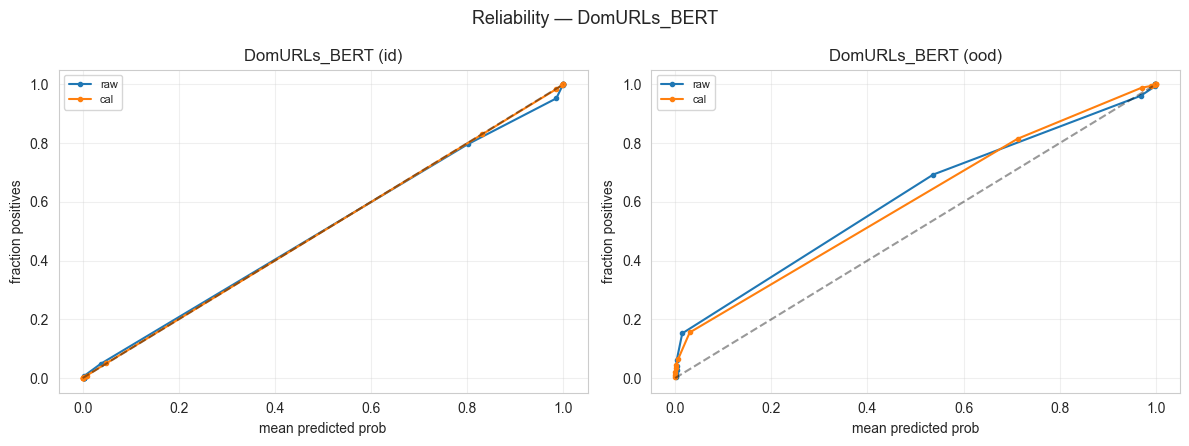

In [85]:
_fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, split in zip(axes, ["id", "ood"]):
    y_true = y_test_id if split == "id" else y_test_ood
    p_raw = p_test_id_dom if split == "id" else p_ood_dom
    p_cal = iso_dom.predict(p_raw)
    for label, p in [("raw", p_raw), ("cal", p_cal)]:
        frac, mean = calibration_curve(y_true, p, n_bins=15, strategy="quantile")
        ax.plot(mean, frac, marker=".", label=label)
    ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
    ax.set_title(f"DomURLs_BERT ({split})")
    ax.set_xlabel("mean predicted prob")
    ax.set_ylabel("fraction positives")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.suptitle("Reliability — DomURLs_BERT", fontsize=13)
plt.tight_layout()
plt.savefig(PATHS["plots_dir"] / "reliability_domurls.png", dpi=140)
plt.show()

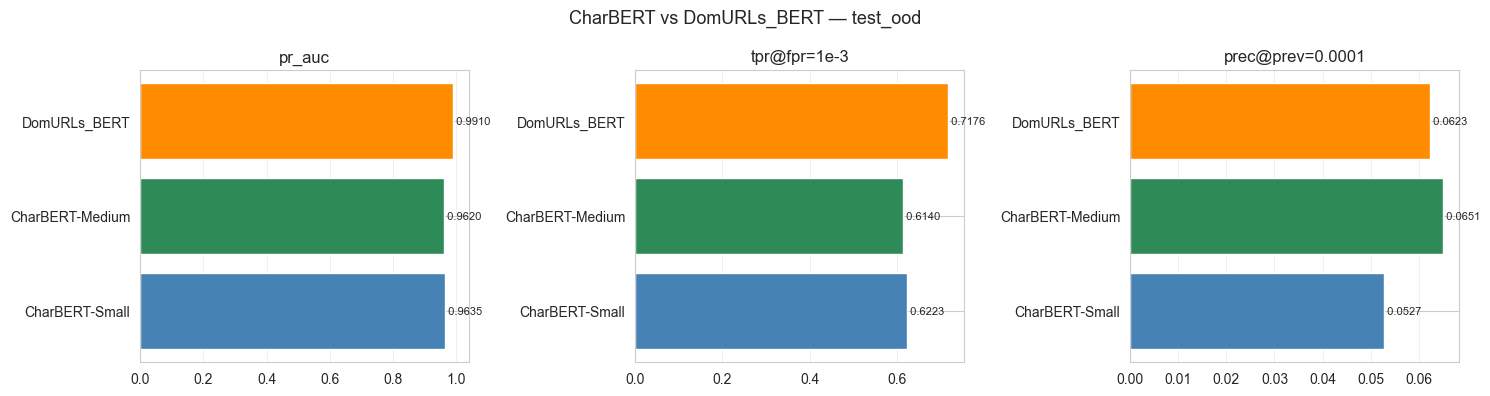

In [86]:
_fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["pr_auc", "tpr@fpr=1e-3", "prec@prev=0.0001"]):
    vals = cmp_ood[metric]
    ax.barh(vals.index, vals.values, color=list(BERT_COLORS.values()))
    ax.set_title(metric)
    ax.grid(axis="x", alpha=0.3)
    for i, v in enumerate(vals.values):
        ax.text(v, i, f" {v:.4f}", va="center", fontsize=8)
plt.suptitle("CharBERT vs DomURLs_BERT — test_ood", fontsize=13)
plt.tight_layout()
plt.savefig(PATHS["plots_dir"] / "compare_bert_vs_domurls_ood.png", dpi=140)
plt.show()

In [87]:
def benchmark_domurls_single(
    model, input_ids, attention_mask, n_warm=20, n=200, device=None
):
    """Single-input latency (ms) for DomURLs_BERT. Pure forward, no tokenization."""
    model.eval()
    x_ids = input_ids[:1]
    x_mask = attention_mask[:1]
    if device is not None:
        model = model.to(device)
        x_ids = x_ids.to(device)
        x_mask = x_mask.to(device)
    with torch.no_grad():
        sec = _benchmark_loop(
            lambda: model(input_ids=x_ids, attention_mask=x_mask),
            n_warm,
            n,
            device,
        )
    return sec * 1000


def benchmark_domurls_batch(
    model, input_ids, attention_mask, batch_size=1024, n_warm=5, n=20, device=None
):
    """Batch latency (s) for DomURLs_BERT. Pure forward, no tokenization."""
    model.eval()
    x_ids = input_ids[:batch_size]
    x_mask = attention_mask[:batch_size]
    if device is not None:
        model = model.to(device)
        x_ids = x_ids.to(device)
        x_mask = x_mask.to(device)
    with torch.no_grad():
        return _benchmark_loop(
            lambda: model(input_ids=x_ids, attention_mask=x_mask),
            n_warm,
            n,
            device,
        )

In [88]:
# Использует готовые X_ood_ids / X_ood_mask
domurls_latency_cpu = {}
domurls_latency_gpu = {}

# Размер модели
domurls_size_mb = sum(p.numel() for p in domurls_model.parameters()) * 4 / 1e6

# CPU
domurls_model_cpu = domurls_model.cpu()
ms_cpu = benchmark_domurls_single(
    domurls_model_cpu, X_ood_ids, X_ood_mask, device=torch.device("cpu")
)
s_batch_cpu = benchmark_domurls_batch(
    domurls_model_cpu, X_ood_ids, X_ood_mask, device=torch.device("cpu")
)
domurls_latency_cpu = {
    "single_ms": ms_cpu,
    "batch_1024_s": s_batch_cpu,
    "throughput_domains_s": 1024 / s_batch_cpu,
    "model_size_mb": domurls_size_mb,
}
print(
    f"DomURLs_BERT (cpu) | single={ms_cpu:7.2f} ms | batch={s_batch_cpu:6.3f} s | "
    f"throughput={1024 / s_batch_cpu:7.0f} dom/s | size={domurls_size_mb:.1f} MB"
)

DomURLs_BERT (cpu) | single=  70.57 ms | batch=42.033 s | throughput=     24 dom/s | size=442.5 MB


In [89]:
# GPU
if torch.cuda.is_available():
    domurls_model_gpu = domurls_model.to(DEVICE)
    ms_gpu = benchmark_domurls_single(
        domurls_model_gpu, X_ood_ids, X_ood_mask, device=DEVICE
    )
    s_batch_gpu = benchmark_domurls_batch(
        domurls_model_gpu, X_ood_ids, X_ood_mask, device=DEVICE
    )
    domurls_latency_gpu = {
        "single_ms": ms_gpu,
        "batch_1024_s": s_batch_gpu,
        "throughput_domains_s": 1024 / s_batch_gpu,
        "model_size_mb": domurls_size_mb,
    }
    print(
        f"DomURLs_BERT (gpu) | single={ms_gpu:7.2f} ms | batch={s_batch_gpu:6.3f} s | "
        f"throughput={1024 / s_batch_gpu:7.0f} dom/s"
    )

    domurls_model = release_gpu(domurls_model_gpu, "DomURLs_BERT_gpu")
else:
    domurls_model = domurls_model_cpu

DomURLs_BERT (gpu) | single=  11.48 ms | batch= 2.690 s | throughput=    381 dom/s
DomURLs_BERT_gpu    : cuda:0 → cpu
VRAM: 5.31 GB free


In [90]:
lat_dom_rows = [
    {"model": "DomURLs_BERT", "device": "cpu", **domurls_latency_cpu},
]
if domurls_latency_gpu:
    lat_dom_rows.append(
        {"model": "DomURLs_BERT", "device": "gpu", **domurls_latency_gpu}
    )

lat_dom_df = pd.DataFrame(lat_dom_rows).set_index(["model", "device"])
lat_dom_df = lat_dom_df[
    ["single_ms", "batch_1024_s", "throughput_domains_s", "model_size_mb"]
]

existing = pd.read_csv(
    PATHS["models_dir"] / "reports" / "latency_all.csv", index_col=["model", "device"]
)
merged = pd.concat([existing, lat_dom_df])
merged = merged[~merged.index.duplicated(keep="last")]
merged.to_csv(PATHS["models_dir"] / "reports" / "latency_all.csv")
print("=== latency_all.csv (updated) ===")
print(merged.round(2).to_string())

=== latency_all.csv (updated) ===
                        single_ms  batch_1024_s  throughput_domains_s  model_size_mb
model           device                                                              
LightGBM        cpu          1.44          0.02              53708.71          10.48
XGBoost         cpu          4.47          0.01              80424.30          10.41
MLP             cpu          0.86          0.00             763313.26           0.28
CharCNN-Small   cpu          0.76          0.12               8255.69           0.74
                gpu          1.49          0.01              91565.84           0.74
CharCNN-Medium  cpu          1.88          0.44               2322.07           5.05
                gpu          1.57          0.03              34300.18           5.05
CharBERT-Small  cpu          1.48          0.47               2161.54           0.87
                gpu          2.16          0.03              31199.18           0.87
CharBERT-Medium cpu          2.

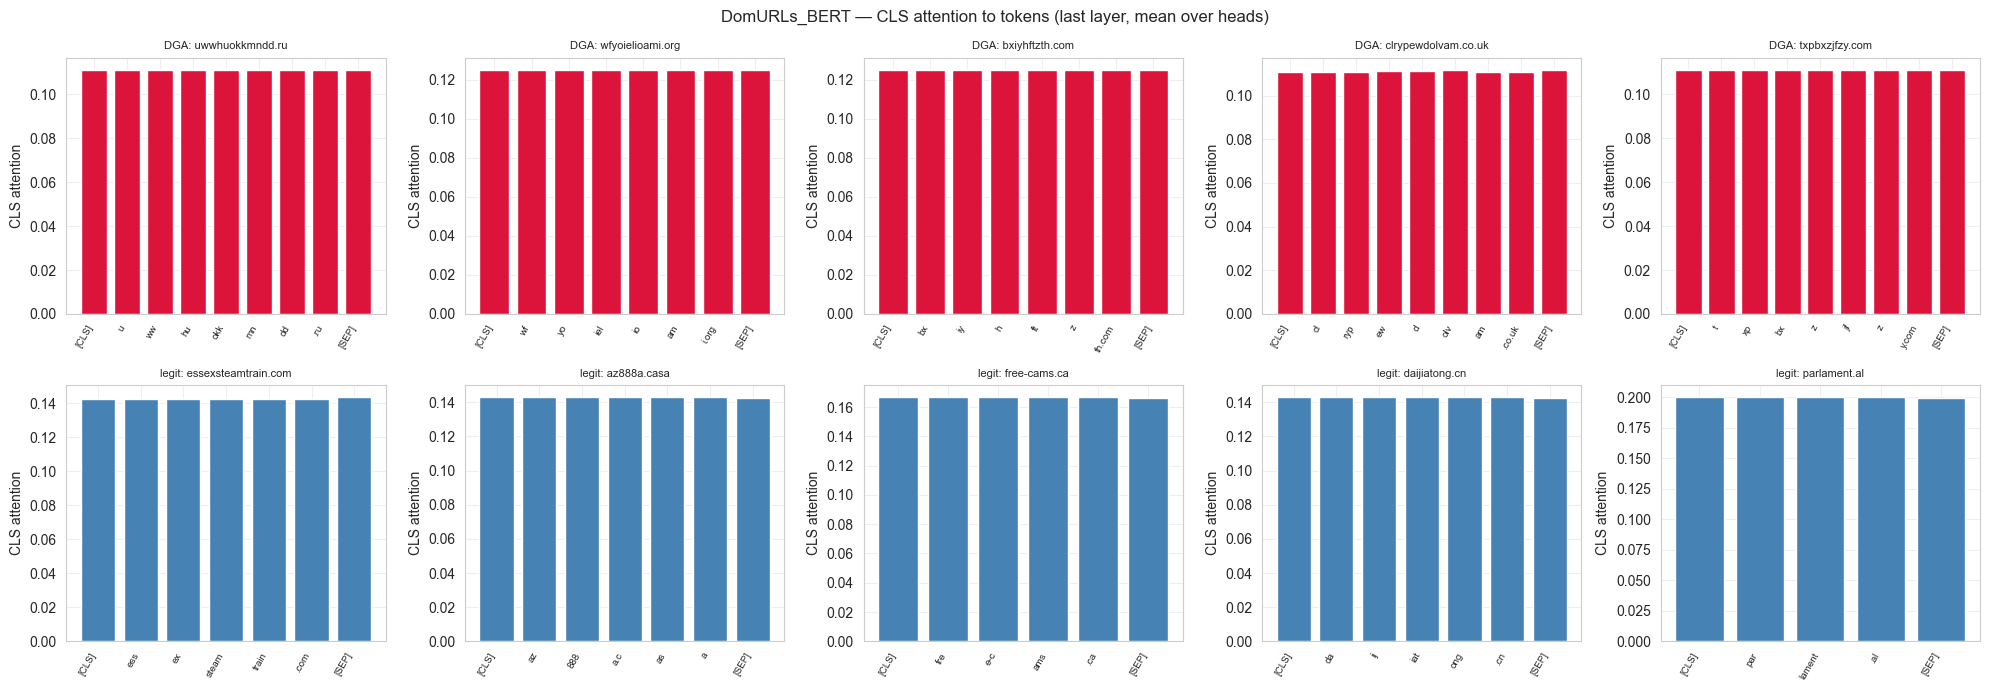

In [91]:
@torch.no_grad()
def extract_domurls_attention(model, input_ids, attention_mask):
    model.eval()
    model_device = next(model.parameters()).device

    # SDPA/Flash не поддерживают output_attentions. Временно переключаем на eager.
    original_impl = model.config._attn_implementation
    if original_impl != "eager":
        model.config._attn_implementation = "eager"
        # Для BERT нужно применить это к слоям
        for layer in model.bert.encoder.layer:
            layer.attention.self.config._attn_implementation = "eager"
    try:
        out = model(
            input_ids=input_ids.to(model_device),
            attention_mask=attention_mask.to(model_device),
            output_attentions=True,
        )
        last_layer = out.attentions[-1].mean(dim=1)  # усредняем по головам
        cls_attn = last_layer[:, 0, :].cpu().numpy()  # CLS-токен (позиция 0)
    finally:
        # Восстанавливаем оригинальную реализацию
        model.config._attn_implementation = original_impl
        for layer in model.bert.encoder.layer:
            layer.attention.self.config._attn_implementation = original_impl

    return cls_attn


# 5 DGA + 5 legit examples из test_ood
N_VIS = 5
rng = np.random.RandomState(SEED)
dga_idx = np.where(y_test_ood == 1)[0]
legit_idx = np.where(y_test_ood == 0)[0]
vis_idx = np.concatenate(
    [
        rng.choice(dga_idx, N_VIS, replace=False),
        rng.choice(legit_idx, N_VIS, replace=False),
    ]
)

attn_vis = extract_domurls_attention(
    domurls_model, X_ood_ids[vis_idx], X_ood_mask[vis_idx]
)

# Plot: bar per example
_fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for i, ax in enumerate(axes.flatten()):
    idx = vis_idx[i]
    domain = X_domain[test_ood_idx[idx]][:60]
    label = "DGA" if y_test_ood[idx] == 1 else "legit"
    tokens = tokenizer_domurls.convert_ids_to_tokens(X_ood_ids[idx])
    # Отрезаем по [SEP] (первый)
    try:
        sep_pos = tokens.index("[SEP]") + 1
    except ValueError:
        sep_pos = len(tokens)
    tokens = tokens[:sep_pos]
    attn = attn_vis[i][:sep_pos]

    ax.bar(range(len(tokens)), attn, color="crimson" if label == "DGA" else "steelblue")
    ax.set_xticks(range(len(tokens)))
    ax.set_xticklabels(tokens, rotation=60, ha="right", fontsize=7)
    ax.set_title(f"{label}: {domain}", fontsize=8)
    ax.set_ylabel("CLS attention")
    ax.grid(alpha=0.3)

plt.suptitle(
    "DomURLs_BERT — CLS attention to tokens (last layer, mean over heads)", fontsize=12
)
plt.tight_layout()
plt.savefig(PATHS["plots_dir"] / "domurls_attention.png", dpi=140)
plt.show()

Occlusion done in 29.6s | shape=(40, 75)


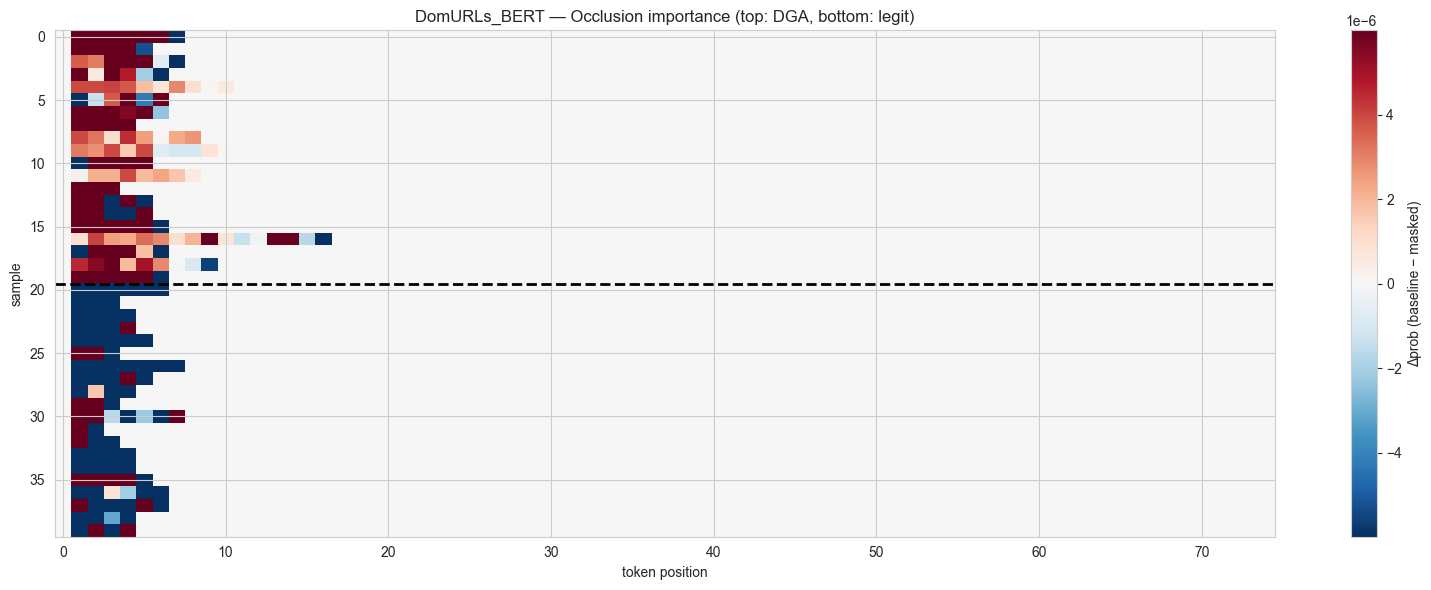

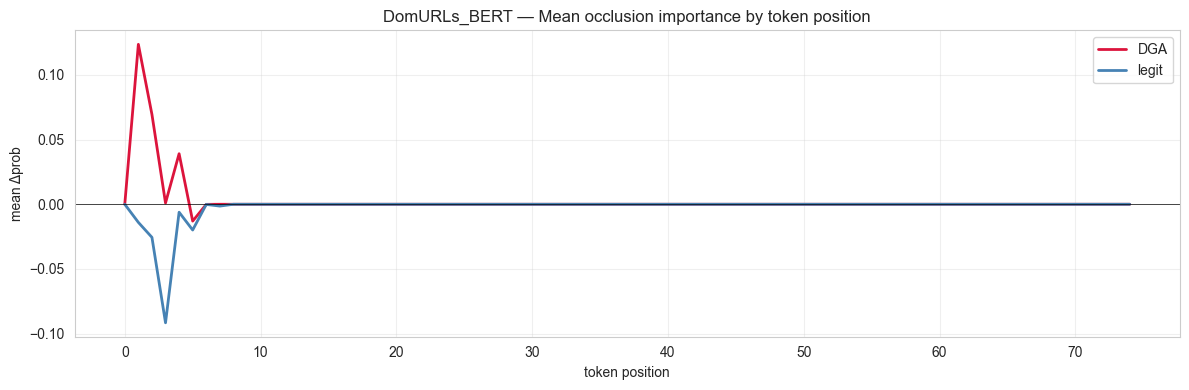

In [92]:
@torch.no_grad()
def occlusion_domurls(
    model, input_ids, attention_mask, n_samples=20, tokenizer=None, mask_token_id=None
):
    """Заменяет каждый токен на [MASK] и меряет Δprob. Token-level."""
    model.eval()
    model_device = next(model.parameters()).device  # ← device из модели

    if mask_token_id is None:
        mask_token_id = tokenizer.mask_token_id
    input_ids = input_ids[:n_samples]
    attention_mask = attention_mask[:n_samples]
    B, L = input_ids.shape

    # Baseline
    base = (
        torch.sigmoid(
            model(
                input_ids=input_ids.to(model_device),
                attention_mask=attention_mask.to(model_device),
            ).logits.squeeze(-1)
        )
        .cpu()
        .numpy()
    )

    importance = np.zeros((B, L))
    pad_id = tokenizer.pad_token_id
    cls_id = tokenizer.cls_token_id
    sep_id = tokenizer.sep_token_id

    for pos in range(L):
        col_ids = input_ids[:, pos]
        skip_mask = (col_ids == pad_id) | (col_ids == cls_id) | (col_ids == sep_id)
        if skip_mask.all():
            continue
        perturbed = input_ids.clone()
        perturbed[:, pos] = torch.where(
            skip_mask, col_ids, torch.tensor(mask_token_id, dtype=col_ids.dtype)
        )
        p = (
            torch.sigmoid(
                model(
                    input_ids=perturbed.to(model_device),
                    attention_mask=attention_mask.to(model_device),
                ).logits.squeeze(-1)
            )
            .cpu()
            .numpy()
        )
        importance[:, pos] = base - p

    return importance, base


# 20 DGA + 20 legit из test_ood
occl_idx = np.concatenate(
    [
        rng.choice(dga_idx, 20, replace=False),
        rng.choice(legit_idx, 20, replace=False),
    ]
)
t0 = time.perf_counter()
occl_imp, occl_base = occlusion_domurls(
    domurls_model,
    X_ood_ids[occl_idx],
    X_ood_mask[occl_idx],
    n_samples=40,
    tokenizer=tokenizer_domurls,
)
print(f"Occlusion done in {time.perf_counter() - t0:.1f}s | shape={occl_imp.shape}")

# Heatmap
_fig, ax = plt.subplots(figsize=(16, 6))
vmax = np.percentile(np.abs(occl_imp), 95)
im = ax.imshow(occl_imp, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
ax.axhline(19.5, color="black", lw=2, ls="--")
ax.set_title("DomURLs_BERT — Occlusion importance (top: DGA, bottom: legit)")
ax.set_xlabel("token position")
ax.set_ylabel("sample")
plt.colorbar(im, ax=ax, label="Δprob (baseline − masked)")
plt.tight_layout()
plt.savefig(PATHS["plots_dir"] / "domurls_occlusion_heatmap.png", dpi=140)
plt.show()

# Средний профиль по DGA vs legit
_fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(occl_imp[:20].mean(axis=0), color="crimson", label="DGA", linewidth=2)
ax.plot(occl_imp[20:].mean(axis=0), color="steelblue", label="legit", linewidth=2)
ax.axhline(0, color="black", lw=0.5)
ax.set_title("DomURLs_BERT — Mean occlusion importance by token position")
ax.set_xlabel("token position")
ax.set_ylabel("mean Δprob")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PATHS["plots_dir"] / "domurls_occlusion_by_position.png", dpi=140)
plt.show()

In [93]:
conv_dom = pd.DataFrame(
    [
        {
            "model": "DomURLs_BERT",
            "epochs_run": len(domurls_hist["epoch"]),
            "cap": DOMURLS_EPOCHS,
            "status": "early_stop"
            if len(domurls_hist["epoch"]) < DOMURLS_EPOCHS
            else "hit_cap",
            "best_val_ap": domurls_best_ap,
            "train_time_min": domurls_train_s / 60,
        }
    ]
).set_index("model")
conv_dom.to_csv(PATHS["models_dir"] / "reports" / "convergence_dom.csv")
print(conv_dom.round(4).to_string())

              epochs_run  cap      status  best_val_ap  train_time_min
model                                                                 
DomURLs_BERT           3    5  early_stop       0.9973        766.9768


In [94]:
ALL_MODELS_ORDERED = list(trained_models) + list(deep_models) + ["DomURLs_BERT"]
ALL_MODELS_ORDERED = [
    m for m in ALL_MODELS_ORDERED if m in set(metrics_id_df.index) | {"DomURLs_BERT"}
]

# full_metrics_* — VIEW (memory only). Not written to model_artifact.json.
# The artifact gets per-model entries in the final artifact-update cell.
full_metrics_id = metrics_id_df.copy()
full_metrics_ood = metrics_ood_df.copy()
full_metrics_id.loc["DomURLs_BERT"] = metrics_id_dom
full_metrics_ood.loc["DomURLs_BERT"] = metrics_ood_dom

common_cols = [c for c in metrics_id_df.columns if c in metrics_id_dom]
full_metrics_id = full_metrics_id[common_cols]
full_metrics_ood = full_metrics_ood[common_cols]

full_metrics_id.to_csv(PATHS["models_dir"] / "reports" / "metrics_id_full.csv")
full_metrics_ood.to_csv(PATHS["models_dir"] / "reports" / "metrics_ood_full.csv")

print("=== ALL models — test_id ===")
print(
    full_metrics_id.loc[
        ALL_MODELS_ORDERED, ["pr_auc", "tpr@fpr=1e-3", "prec@prev=0.0001", "brier"]
    ]
    .round(4)
    .to_string()
)
print("\n=== ALL models — test_ood ===")
print(
    full_metrics_ood.loc[
        ALL_MODELS_ORDERED, ["pr_auc", "tpr@fpr=1e-3", "prec@prev=0.0001", "brier"]
    ]
    .round(4)
    .to_string()
)

=== ALL models — test_id ===
                 pr_auc  tpr@fpr=1e-3  prec@prev=0.0001   brier
model                                                          
LightGBM         0.9807        0.6576            0.0628  0.0518
XGBoost          0.9808        0.6586            0.0603  0.0515
MLP              0.9755        0.6070            0.0546  0.0586
CharCNN-Small    0.9967        0.8210            0.0771  0.0190
CharCNN-Medium   0.9977        0.8431            0.0669  0.0182
CharBERT-Small   0.9972        0.8431            0.0698  0.0186
CharBERT-Medium  0.9978        0.8741            0.0908  0.0162
DomURLs_BERT     0.9970        0.7974            0.0683  0.0130

=== ALL models — test_ood ===
                 pr_auc  tpr@fpr=1e-3  prec@prev=0.0001   brier
model                                                          
LightGBM         0.9612        0.5863            0.0563  0.0911
XGBoost          0.9602        0.5872            0.0541  0.0923
MLP              0.9631        0.5728       

In [95]:
# Per-family recall для DomURLs
fam_recall_dom = per_family_recall(df_test_ood, p_ood_dom, thr_dom)
fam_df_dom = pd.DataFrame([fam_recall_dom], index=["DomURLs_BERT"]).T
fam_df_dom.columns = ["DomURLs_BERT"]

# Merge с существующим fam_df (7 моделей)
fam_df_full = fam_df.join(fam_df_dom, how="left")
fam_df_full.to_csv(PATHS["models_dir"] / "reports" / "per_family_recall_ood_full.csv")

print("=== Per-family recall — ALL models (test_ood) ===")
print(fam_df_full[[*MODEL_ORDER, "DomURLs_BERT"]].round(3).to_string())

# FN by family для DomURLs
pred_dom = (p_ood_dom >= thr_dom).astype(int)
fn_mask_dom = (y_test_ood == 1) & (pred_dom == 0)
fn_fams_dom = df_test_ood.loc[fn_mask_dom, "class"].value_counts()
fn_fams_dom.name = "DomURLs_BERT"

# Merge
fn_full = fn_summary.join(fn_fams_dom, how="left").fillna(0).astype(int)
fn_full["Total_FN_with_dom"] = fn_full[
    [c for c in fn_full.columns if c != "Total_FN"]
].sum(axis=1)
fn_full.to_csv(PATHS["models_dir"] / "reports" / "fn_by_family_ood_full.csv")
print("\n=== FN by family — extended (with DomURLs_BERT) ===")
print(fn_full[[*MODEL_ORDER, "DomURLs_BERT"]].to_string())

=== Per-family recall — ALL models (test_ood) ===
              LightGBM  XGBoost    MLP  CharCNN-Small  CharCNN-Medium  CharBERT-Small  CharBERT-Medium  DomURLs_BERT
suppobox-1       0.007    0.010  0.003          0.175           0.201           0.117            0.102         0.006
simda            0.089    0.076  0.063          0.190           0.218           0.166            0.122         0.345
proslikefan      0.365    0.370  0.348          0.444           0.460           0.429            0.383         0.480
shiotob          0.591    0.606  0.728          0.778           0.743           0.560            0.464         0.897
pykspa           0.605    0.606  0.567          0.708           0.748           0.706            0.684         0.793
fobber-v2        0.755    0.755  0.606          0.658           0.707           0.817            0.805         0.780
dircrypt         0.768    0.771  0.759          0.825           0.848           0.802            0.796         0.865
cryptolocker  

In [96]:
fp_dom, fn_dom = save_top_errors(
    "DomURLs_BERT",
    y_test_ood,
    df_test_ood,
    p_ood_dom,
    thr_dom,
    PATHS["models_dir"] / "errors",
    n=N_TOP_ERRORS,
)

print(f"{'=' * 60}\nDomURLs_BERT (test_ood)\n{'=' * 60}")
print(
    f"FP: {len(fp_dom)} shown (total FP = {int(((y_test_ood == 0) & (p_ood_dom >= thr_dom)).sum())})"
)
print(fp_dom.to_string(index=False))
print(
    f"\nFN: {len(fn_dom)} shown (total FN = {int(((y_test_ood == 1) & (p_ood_dom < thr_dom)).sum())})"
)
print(fn_dom.to_string(index=False))

print("\nSaved DomURLs_BERT_ood_FP.csv, DomURLs_BERT_ood_FN.csv")

DomURLs_BERT (test_ood)
FP: 10 shown (total FP = 164)
                                                      domain class     prob
                                     ecouterradioenligne.com legit 0.998650
                                       drgolbargmehrpoor.com legit 0.998639
                        nkbihfbeogaeaobhlefnkodbefgpgknn.com legit 0.998638
omgomgomg5j4yrr4mjdv3h5c5xfvxtqqs2in7smi65mjps7wvkmqmtqd.com legit 0.998638
                                ojzs12ngwxrf3qfsusw578rl.com legit 0.998631
                                        jemqorlyqpenkures.kz legit 0.998628
                                     skdjht3eigjsfdgfddf.com legit 0.998624
                                          qldkrmfkrnaocj.top legit 0.998623
                                             domohozyaika.kz legit 0.998622
                                       sdvjegbb5dsf6dfb2d.cc legit 0.998621

FN: 10 shown (total FN = 46446)
      domain       class     prob
 momziedz.se proslikefan 0.002598
 omosvrzz

In [97]:
# Худшее семейство по абсолютному числу FN
worst_fam_dom = fn_fams_dom.idxmax()
worst_count = int(fn_fams_dom.max())
fam_total = int((df_test_ood["class"] == worst_fam_dom).sum())
worst_recall = 1 - worst_count / fam_total

print(f"Худшее семейство для DomURLs_BERT: {worst_fam_dom}")
print(f"  FN: {worst_count} / {fam_total} ({worst_recall * 100:.1f}% recall)")
print("  Другие модели (из Section 6.5):")
for name in MODEL_ORDER:
    n_fn = int(fn_summary.loc[worst_fam_dom, name])
    print(f"    {name:18s}: {n_fn} FN")

# Примеры ошибочно классифицированных доменов этого семейства
worst_mask = (
    (df_test_ood["class"] == worst_fam_dom) & (y_test_ood == 1) & (p_ood_dom < thr_dom)
)
worst_samples = (
    df_test_ood.loc[worst_mask, ["domain", "class"]]
    .assign(prob=p_ood_dom[worst_mask])
    .sort_values("prob")
    .head(10)
)
print("\nПримеры (10 наиболее уверенных FN):")
print(worst_samples.to_string(index=False))

# Распределение длин FN-доменов vs среднее по test_ood
fn_lens = df_test_ood.loc[worst_mask, "domain"].str.len()
print(
    f"\nДлины доменов в FN (worst family): median={fn_lens.median():.0f}, "
    f"max={fn_lens.max()}"
)

Худшее семейство для DomURLs_BERT: simda
  FN: 13101 / 20000 (34.5% recall)
  Другие модели (из Section 6.5):
    LightGBM          : 18227 FN
    XGBoost           : 18476 FN
    MLP               : 18735 FN
    CharCNN-Small     : 16200 FN
    CharCNN-Medium    : 15650 FN
    CharBERT-Small    : 16684 FN
    CharBERT-Medium   : 17558 FN

Примеры (10 наиболее уверенных FN):
        domain class     prob
      galar.eu simda 0.002646
      galov.eu simda 0.002649
      galaz.eu simda 0.002649
      galik.eu simda 0.002650
      galoz.eu simda 0.002651
      galor.eu simda 0.002654
makijikeris.eu simda 0.002658
      galak.eu simda 0.002659
      galap.eu simda 0.002661
      gatov.eu simda 0.002661

Длины доменов в FN (worst family): median=12, max=14


In [98]:
BERT_ERR = {
    name: (
        (p_ood_dom if name == "DomURLs_BERT" else test_ood_probs[name])
        >= (thr_dom if name == "DomURLs_BERT" else thresholds[name])
    )
    != y_test_ood
    for name in ["CharBERT-Small", "CharBERT-Medium", "DomURLs_BERT"]
}
_err_names = list(BERT_ERR.keys())
_all_shared = np.logical_and.reduce([BERT_ERR[n] for n in _err_names])

err_summary = pd.DataFrame(
    {
        "total_errors": {n: int(BERT_ERR[n].sum()) for n in _err_names},
        "unique_to_model": {
            n: int(
                (
                    BERT_ERR[n]
                    & ~np.logical_or.reduce([BERT_ERR[m] for m in _err_names if m != n])
                ).sum()
            )
            for n in _err_names
        },
        "shared_by_all3": {n: int(_all_shared.sum()) for n in _err_names},
    }
)
print("=== Error overlap — BERT family (test_ood) ===")
print(err_summary.to_string())
print(f"\nTotal OOD samples: {len(y_test_ood)}")

print("\n=== Per-family: DomURLs vs CharBERT (FN counts) ===")
fam_compare_bert = pd.DataFrame(
    {
        "CharBERT-Small": fn_summary["CharBERT-Small"],
        "CharBERT-Medium": fn_summary["CharBERT-Medium"],
        "DomURLs_BERT": fn_fams_dom.reindex(fn_summary.index, fill_value=0).astype(int),
    }
)
fam_compare_bert["Δ Dom − CB-M"] = (
    fam_compare_bert["DomURLs_BERT"] - fam_compare_bert["CharBERT-Medium"]
)
fam_compare_bert = fam_compare_bert.sort_values("DomURLs_BERT", ascending=False)
fam_compare_bert.to_csv(
    PATHS["models_dir"] / "reports" / "fn_bert_family_comparison.csv"
)
print(fam_compare_bert.to_string())

=== Error overlap — BERT family (test_ood) ===
                 total_errors  unique_to_model  shared_by_all3
CharBERT-Small          62888             3827           38820
CharBERT-Medium         67334             7724           38820
DomURLs_BERT            46610             4357           38820

Total OOD samples: 319547

=== Per-family: DomURLs vs CharBERT (FN counts) ===
              CharBERT-Small  CharBERT-Medium  DomURLs_BERT  Δ Dom − CB-M
class                                                                    
simda                  16684            17558         13101         -4457
proslikefan            11426            12336         10401         -1935
suppobox-1              8441             8585          9496           911
fobber-v2               3657             3893          4391           498
dircrypt                3961             4090          2693         -1397
pykspa                  2943             3164          2067         -1097
shiotob                 8798 

In [99]:
dom_brier_rows = []
for split, y_true, p_raw in [
    ("id", y_test_id, p_test_id_dom),
    ("ood", y_test_ood, p_ood_dom),
]:
    p_cal = iso_dom.predict(p_raw)
    dom_brier_rows.append(
        {
            "model": "DomURLs_BERT",
            "split": split,
            "brier_raw": float(brier_score_loss(y_true, p_raw)),
            "brier_cal": float(brier_score_loss(y_true, p_cal)),
            "delta": float(
                brier_score_loss(y_true, p_cal) - brier_score_loss(y_true, p_raw)
            ),
        }
    )

dom_brier_df = pd.DataFrame(dom_brier_rows).set_index(["model", "split"])

# Concat с 7-модельной таблицей
brier_ext = pd.concat([brier_df, dom_brier_df])
brier_ext.to_csv(PATHS["models_dir"] / "reports" / "brier_comparison_full.csv")

print("=== Brier comparison (all 8 models) ===")
print(brier_ext.round(5).to_string())

=== Brier comparison (all 8 models) ===
                       brier_raw  brier_cal    delta
model           split                               
LightGBM        id       0.05176    0.05169 -0.00007
                ood      0.09107    0.09131  0.00025
XGBoost         id       0.05150    0.05145 -0.00005
                ood      0.09231    0.09243  0.00012
MLP             id       0.05857    0.05855 -0.00002
                ood      0.08677    0.08617 -0.00060
CharCNN-Small   id       0.01900    0.01822 -0.00078
                ood      0.06211    0.06164 -0.00047
CharCNN-Medium  id       0.01820    0.01510 -0.00310
                ood      0.07637    0.05776 -0.01861
CharBERT-Small  id       0.01864    0.01777 -0.00087
                ood      0.09390    0.09753  0.00363
CharBERT-Medium id       0.01616    0.01532 -0.00084
                ood      0.09971    0.10286  0.00315
DomURLs_BERT    id       0.01302    0.01274 -0.00028
                ood      0.03751    0.03752  0.00001


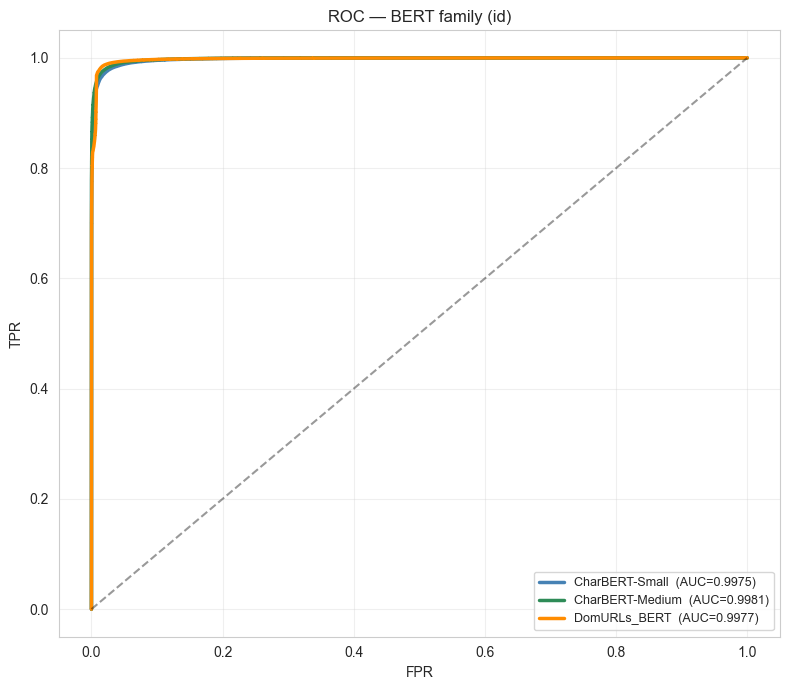

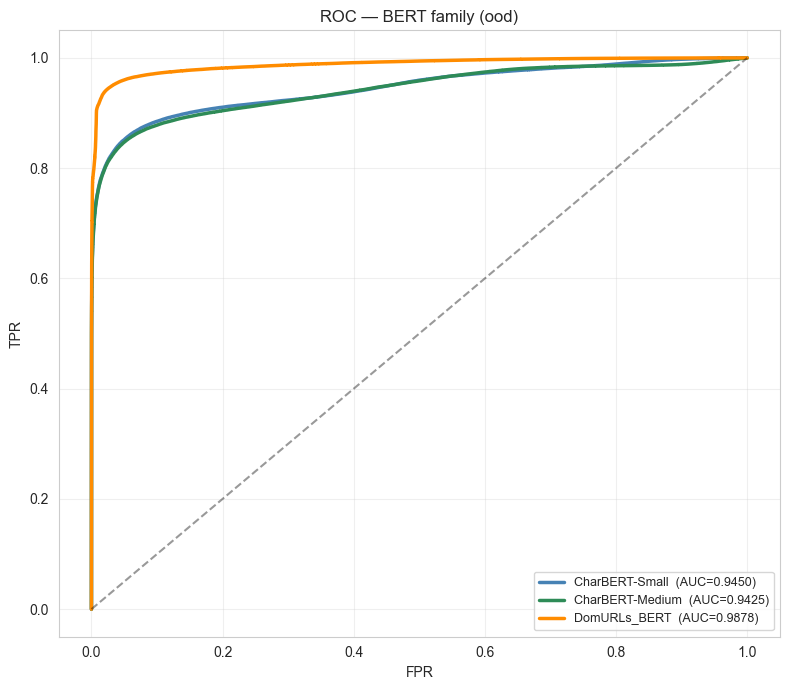

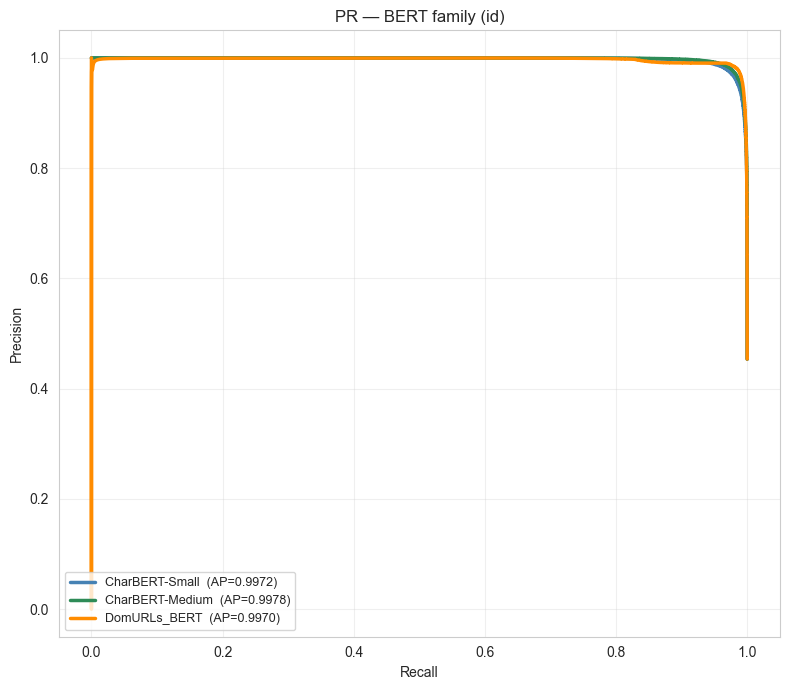

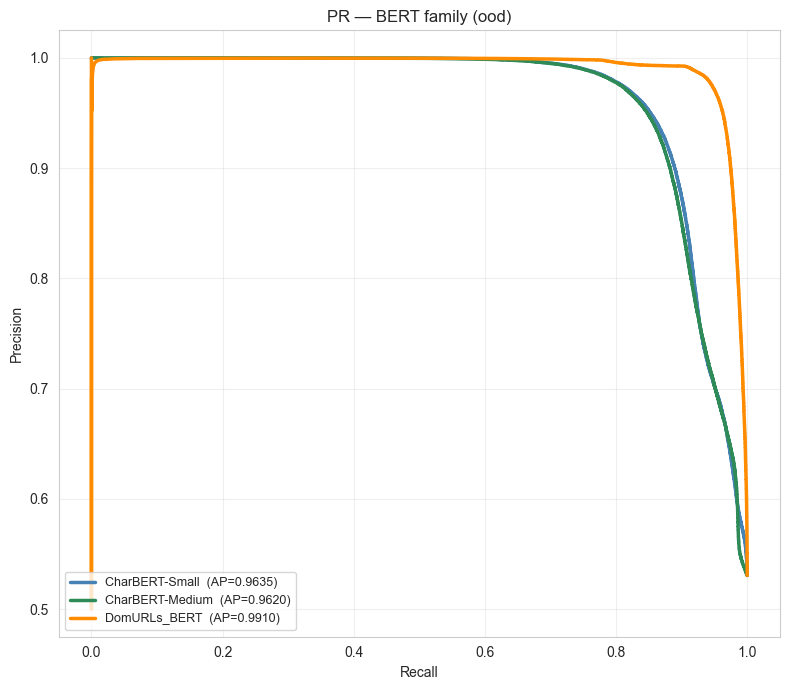

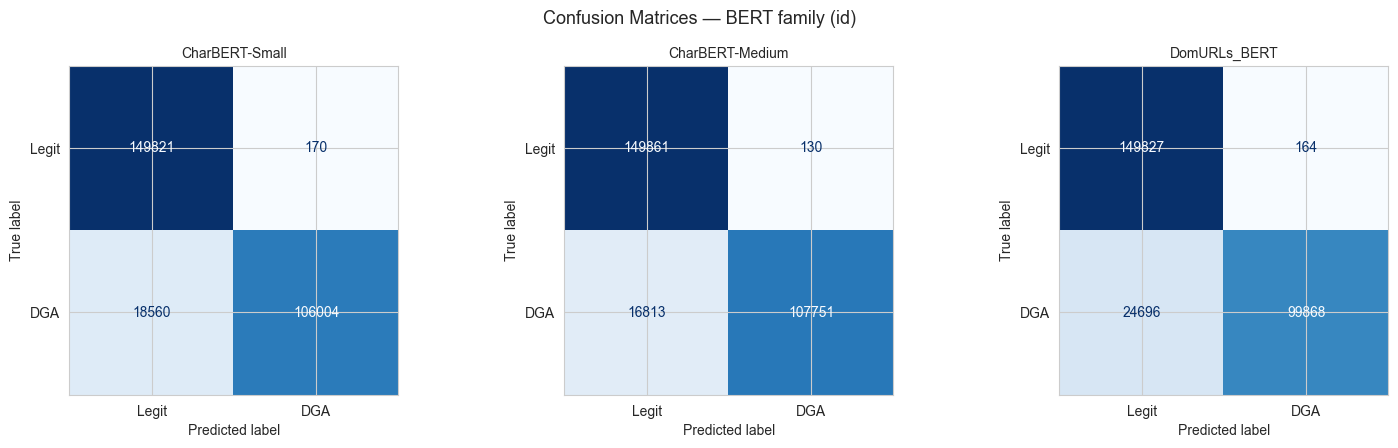

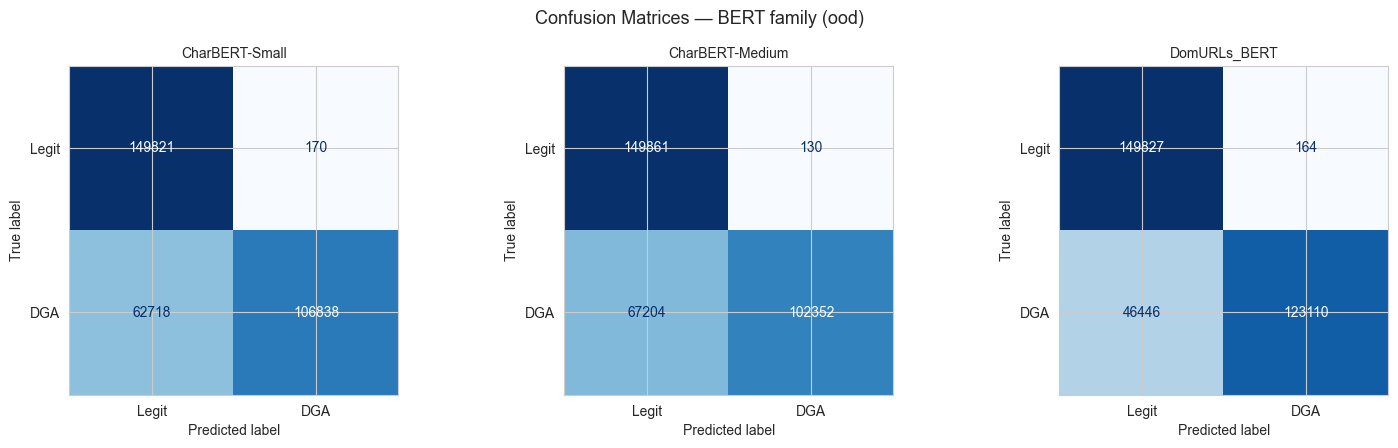

In [100]:
BERT_ORDER = ["CharBERT-Small", "CharBERT-Medium", "DomURLs_BERT"]

BERT_ID_PROBS = {
    **{n: test_id_probs[n] for n in BERT_ORDER if n != "DomURLs_BERT"},
    "DomURLs_BERT": p_test_id_dom,
}
BERT_OOD_PROBS = {
    **{n: test_ood_probs[n] for n in BERT_ORDER if n != "DomURLs_BERT"},
    "DomURLs_BERT": p_ood_dom,
}
BERT_THR = {
    **{n: thresholds[n] for n in BERT_ORDER if n != "DomURLs_BERT"},
    "DomURLs_BERT": thr_dom,
}

# ROC (id / ood)
for split in ["id", "ood"]:
    y_true = y_test_id if split == "id" else y_test_ood
    probs = BERT_ID_PROBS if split == "id" else BERT_OOD_PROBS

    _fig, ax = plt.subplots(figsize=(8, 7))
    for name in BERT_ORDER:
        fpr, tpr, _ = roc_curve(y_true, probs[name])
        auc = roc_auc_score(y_true, probs[name])
        ax.plot(
            fpr,
            tpr,
            color=BERT_COLORS[name],
            linewidth=2.5,
            label=f"{name}  (AUC={auc:.4f})",
        )
    ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
    ax.set_title(f"ROC — BERT family ({split})")
    ax.set_xlabel("FPR")
    ax.set_ylabel("TPR")
    ax.legend(fontsize=9, loc="lower right")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(PATHS["plots_dir"] / f"roc_bert_{split}.png", dpi=140)
    plt.show()

# PR (id / ood)
for split in ["id", "ood"]:
    y_true = y_test_id if split == "id" else y_test_ood
    probs = BERT_ID_PROBS if split == "id" else BERT_OOD_PROBS

    _fig, ax = plt.subplots(figsize=(8, 7))
    for name in BERT_ORDER:
        p, r, _ = precision_recall_curve(y_true, probs[name])
        ap = average_precision_score(y_true, probs[name])
        ax.plot(
            r,
            p,
            color=BERT_COLORS[name],
            linewidth=2.5,
            label=f"{name}  (AP={ap:.4f})",
        )
    ax.set_title(f"PR — BERT family ({split})")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend(fontsize=9, loc="lower left")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(PATHS["plots_dir"] / f"pr_bert_{split}.png", dpi=140)
    plt.show()

# CM (id / ood) — 1×3 grid
for split in ["id", "ood"]:
    y_true = y_test_id if split == "id" else y_test_ood
    probs = BERT_ID_PROBS if split == "id" else BERT_OOD_PROBS

    _fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    for ax, name in zip(axes, BERT_ORDER):
        pred = (probs[name] >= BERT_THR[name]).astype(int)
        cm = confusion_matrix(y_true, pred, labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=["Legit", "DGA"]).plot(
            ax=ax, cmap="Blues", colorbar=False, values_format="d"
        )
        ax.set_title(name, fontsize=10)
    plt.suptitle(f"Confusion Matrices — BERT family ({split})", fontsize=13)
    plt.tight_layout()
    plt.savefig(PATHS["plots_dir"] / f"cm_bert_{split}.png", dpi=140)
    plt.show()

In [101]:
with open(PATHS["artifact"], "r", encoding="utf-8") as f:
    artifact = json.load(f)

feature_keys_before = {
    "thresholds": set(artifact["thresholds"].keys()),
    "metrics_id": set(artifact["metrics_id"].keys()),
    "metrics_ood": set(artifact["metrics_ood"].keys()),
}

# Deep thresholds + metrics (7 base models)
for name in DEEP_MODEL_NAMES:
    artifact["thresholds"][name] = float(thresholds[name])
    artifact["metrics_id"][name] = {
        k: float(v) for k, v in metrics_id_df.loc[name].items()
    }
    artifact["metrics_ood"][name] = {
        k: float(v) for k, v in metrics_ood_df.loc[name].items()
    }

# Deep latency (CPU = production default)
for name in DEEP_MODEL_NAMES:
    artifact["latency"][name] = deep_latency_cpu[name]

# Versions
artifact["versions"]["torch"] = torch.__version__

# External model reference (DomURLs not merged into thresholds/metrics)
artifact.setdefault("external_models", {})["DomURLs_BERT"] = {
    "meta_path": "models/DomURLs_BERT/meta.json",
    "preds_path": "models/DomURLs_BERT/preds.npz",
    "calibrator_path": "models/DomURLs_BERT_cal.pkl",
    "metrics_id_path": "models/reports/metrics_id_dom.csv",
    "metrics_ood_path": "models/reports/metrics_ood_dom.csv",
}

# Assert: feature model keys preserved
for key, saved_keys in feature_keys_before.items():
    assert saved_keys.issubset(set(artifact[key].keys())), (
        f"{key}: feature model keys lost!"
    )

# Assert: all 7 base models present
for name in MODEL_ORDER:
    assert name in artifact["thresholds"], f"{name} missing from artifact.thresholds"
    assert name in artifact["metrics_id"], f"{name} missing from artifact.metrics_id"
    assert name in artifact["metrics_ood"], f"{name} missing from artifact.metrics_ood"

with open(PATHS["artifact"], "w", encoding="utf-8") as f:
    json.dump(artifact, f, ensure_ascii=False, indent=2, default=float)

print("Artifact updated (single write)")
print(f"- thresholds:  {len(artifact['thresholds'])} models")
print(f"- metrics_id:  {len(artifact['metrics_id'])} models")
print(f"- metrics_ood: {len(artifact['metrics_ood'])} models")
print(f"- latency:     {len(artifact['latency'])} models")
print(f"- versions:    {list(artifact['versions'].keys())}")
print(f"- external:    {list(artifact.get('external_models', {}).keys())}")

Artifact updated (single write)
- thresholds:  10 models
- metrics_id:  10 models
- metrics_ood: 10 models
- latency:     10 models
- versions:    ['sklearn', 'lightgbm', 'xgboost', 'numpy', 'pandas', 'shap', 'torch']
- external:    ['DomURLs_BERT']
